# Importing Libraries and Loading the Dataset

We will load air quality data, meteorological data and human activity data to build our forecasting model. We may have some intermediate data and previous model data.

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
!pip install scikeras==0.9.0
# !pip install scikit-learn==1.1.2
# !pip install --upgrade scikit-learn scikeras

ERROR: Ignored the following versions that require a different python version: 0.10.0 Requires-Python >=3.7.0,<3.11.0; 0.2.0 Requires-Python >=3.6.7,<3.9; 0.2.1 Requires-Python >=3.6.7,<3.9; 0.6.0 Requires-Python >=3.7.0,<3.10.0; 0.6.1 Requires-Python >=3.7.0,<3.10.0; 0.7.0 Requires-Python >=3.7.0,<3.10.0; 0.8.0 Requires-Python >=3.7.0,<3.11.0; 0.9.0 Requires-Python >=3.7.0,<3.11.0
ERROR: Could not find a version that satisfies the requirement scikeras==0.9.0 (from versions: 0.1.6, 0.1.7, 0.1.8, 0.3.0, 0.3.1, 0.3.3, 0.4.0, 0.4.1, 0.11.0, 0.12.0, 0.13.0)
ERROR: No matching distribution found for scikeras==0.9.0


In [ ]:
!pip install pydrive
!pip install statsmodels
!pip install lightgbm
!pip install xgboost
!pip install --upgrade keras
!pip install tensorflow
# !pip install keras-tuner==1.1.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 33.1 MB/s eta 0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 3.8.0
    Uninstalling keras-3.8.0:
      Successfully uninstalled keras-3.8.0


In [ ]:
import os
import pprint
import random
import copy
import json
import itertools

from pydrive.auth import GoogleAuth
from pydrive.drive import GoogleDrive
from google.colab import auth
from oauth2client.client import GoogleCredentials

import pandas as pd
import numpy as np

from collections import defaultdict
from statistics import mean, stdev

from IPython.display import IFrame, display
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf

from scipy.stats import t
import scipy.stats as stats
from scipy.stats import mode

from sklearn.model_selection import TimeSeriesSplit, train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import BayesianRidge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn import tree
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score,median_absolute_error
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
# %run us_common_functions.ipynb

In [ ]:
# from tensorflow.python.client import device_lib
# print(device_lib.list_local_devices())

In [ ]:
from numpy import array
from numpy import hstack
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Flatten
# from keras.layers.convolutional import Conv1D
# from keras.layers.convolutional import MaxPooling1D
from keras.layers import Conv1D
from keras.layers import MaxPooling1D
from keras.layers import ConvLSTM1D
from keras.layers import LSTM
from keras.layers import Bidirectional
from keras.layers import Dropout
from keras.regularizers import l2
from keras.models import load_model
from keras.layers import Input, Reshape, Concatenate

In [ ]:
# % pip install tensorflow-addons

# from keras.models import Sequential
# from keras.layers import Dense, Flatten, Dropout
# from keras.utils import to_categorical
# from tensorflow.keras.utils import to_categorical


# import tensorflow
# import tensorflow.keras as K
# import tensorflow_addons as tfa
# from tensorflow.keras import Sequential
# from tensorflow.keras.layers import LSTM, Dense, Dropout, TimeDistributed, Conv1D, MaxPooling1D, Flatten, Bidirectional
# from tensorflow.keras.layers import Input, Flatten, Activation, Reshape, RepeatVector, Concatenate, ConvLSTM1D
# from tensorflow.keras.models import Model
from tensorflow.keras.utils import plot_model
# from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
# from tensorflow.keras.regularizers import l2


In [ ]:
auth.authenticate_user()
gauth = GoogleAuth()
gauth.credentials = GoogleCredentials.get_application_default()
drive = GoogleDrive(gauth)

In [ ]:
bd_3_division_series_file = 'bd_3_division_series.csv'
dhaka_city_and_nearby_readings = 'Dhaka_city_and_nearby_readings.csv'
region_series_file = 'region_series.csv'
dhaka_weather_file = 'Dhaka_weather.csv'
model_file = 'aq_model.h5'
dhaka_mobility_file = 'dhaka_mobility.csv'

In [ ]:
fileDownloaded = drive.CreateFile({'id':'1lMp3kqKyiVkb_dtk3XX0CpU6aqAey8d6'})
fileDownloaded.GetContentFile(bd_3_division_series_file)

fileDownloaded = drive.CreateFile({'id':'1EmxlFdy7XYumFd33oeEn1kuFVmgF45Wc'})
fileDownloaded.GetContentFile(dhaka_city_and_nearby_readings)

fileDownloaded = drive.CreateFile({'id':'1-uYvA9hYUwJLziTJX9G6cl3k-Y7oabbm'})
fileDownloaded.GetContentFile(region_series_file)

fileDownloaded = drive.CreateFile({'id':'1cIRgcdMGVifbzy02N6ncAwLZDltSor4t'})
fileDownloaded.GetContentFile(dhaka_weather_file)

fileDownloaded = drive.CreateFile({'id':'1N1GKqqjLRD3v6JS4FAjPX0lOsD8UbKvo'})
fileDownloaded.GetContentFile(dhaka_mobility_file)

In [ ]:
# fileDownloaded = drive.CreateFile({'id':'1cSv2lVnKaekvdW-YFsvnJijvJvoe8Mj3'})
# fileDownloaded.GetContentFile(model_file)

In [ ]:
#USA Pred

us_west_reading_series = 'us_west_reading_series.csv'
weather_file = 'Seattle_Weather.csv'

fileDownloaded = drive.CreateFile({'id':'1kCvjGZ5Zi2bIIley3Zt_egFzlOT4XK2t'})
fileDownloaded.GetContentFile(us_west_reading_series)

fileDownloaded = drive.CreateFile({'id':'1ns0L-EZg9F8TZMsadHr5OhAaQFMxlda4'})
fileDownloaded.GetContentFile(weather_file)

# Reading and Cleaning Data

We used one of the zonal readings data of Dhaka city and meteoroglocal data from wunderground. We conisdered the data of three years from 2019-2021 due to availability of the data. We imputed the mssiong values by taking the reading values of previous 3 days and next 3 days and taking the average of those values. For meteorlogival varibles we considered temperature, dew point, humidity, wind speed, pressure.

## US West Data

In [ ]:
#USA Pred
raw_pm_series = pd.read_csv(us_west_reading_series,index_col='time')
raw_pm_series.index = pd.to_datetime(raw_pm_series.index)
raw_pm_series.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 157800 entries, 2004-01-01 00:00:00 to 2021-12-31 23:00:00
Data columns (total 12 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Albuquerque_New Mexico    148699 non-null  float64
 1   Austin_Texas              148660 non-null  float64
 2   Billings_Montana          148674 non-null  float64
 3   Boise_Idaho               148706 non-null  float64
 4   Cheyenne_Wyoming          148615 non-null  float64
 5   Denver_Colorado           148616 non-null  float64
 6   Las Vegas_Nevada          148702 non-null  float64
 7   Phoenix_Arizona           148707 non-null  float64
 8   Portland_Oregon           148701 non-null  float64
 9   Salt Lake City_Utah       148711 non-null  float64
 10  San Francisco_California  148699 non-null  float64
 11  Seattle_Washington        148709 non-null  float64
dtypes: float64(12)
memory usage: 15.7 MB


In [ ]:
#USA Pred
raw_pm_series_zone = raw_pm_series[['Seattle_Washington']]['2012':'2016']
raw_pm_series_zone.shape

(43848, 1)

In [ ]:
raw_pm_series_zone.isna().sum()

,0
Seattle_Washington,0


In [ ]:
# # #USA Pred
# raw_weather_series = pd.read_csv(weather_file,index_col='Time')
# raw_weather_series = eliminate_invalid_values(raw_weather_series)
# raw_weather_series.index = pd.to_datetime(raw_weather_series.index)
# raw_weather_series.index.name = 'time'
# raw_weather_series.info()

In [ ]:
# # USA Pred
# weather_series_model = weather_series_model.apply(FillMissingDataFromDays, args=[7])
# # weather_series_model = weather_series_model.apply(FillMissingDataFromDays, args=[3]).fillna(mean)

## Bangladesh

### Reading Data

In [ ]:
# raw_series = pd.read_csv(region_series_file,index_col='time')
# raw_series.index = pd.to_datetime(raw_series.index)
# raw_series.head()

In [ ]:
raw_pm_series = pd.read_csv(dhaka_city_and_nearby_readings,index_col='time')
raw_pm_series.index = pd.to_datetime(raw_pm_series.index)
raw_pm_series.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 46704 entries, 2017-01-01 00:00:00 to 2022-04-30 23:00:00
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Azimpur_Dhaka      44084 non-null  float64
 1   Dhaka_Dhaka        44034 non-null  float64
 2   Narayanganj_Dhaka  43933 non-null  float64
 3   Narsingdi_Dhaka    43898 non-null  float64
 4   Paltan_Dhaka       44085 non-null  float64
 5   Tungi_Dhaka        43956 non-null  float64
dtypes: float64(6)
memory usage: 2.5 MB


In [ ]:
# raw_series_zone = raw_series[['Dhaka']]['2019':'2021']
raw_pm_series_zone = raw_pm_series[['Tungi_Dhaka']]['2018':'2021']
raw_pm_series_zone.shape

(35064, 1)

In [ ]:
raw_pm_series_zone[raw_pm_series_zone.isna().any(axis=1)].index

DatetimeIndex(['2018-01-04 23:00:00', '2018-01-05 00:00:00',
               '2018-01-05 01:00:00', '2018-01-05 02:00:00',
               '2018-01-05 03:00:00', '2018-01-05 04:00:00',
               '2018-01-05 05:00:00', '2018-01-05 06:00:00',
               '2018-01-05 07:00:00', '2018-01-05 08:00:00',
               ...
               '2021-12-03 19:00:00', '2021-12-03 20:00:00',
               '2021-12-06 02:00:00', '2021-12-06 10:00:00',
               '2021-12-22 17:00:00', '2021-12-23 19:00:00',
               '2021-12-23 20:00:00', '2021-12-29 03:00:00',
               '2021-12-29 17:00:00', '2021-12-29 18:00:00'],
              dtype='datetime64[ns]', name='time', length=1101, freq=None)

In [ ]:
# series = raw_series_zone.fillna(raw_series_zone.mean())

### Handling Missing Value

In [ ]:
def FillMissingDataFromDays(x, days=3):
    ss = [x.shift(shft, freq='D') for shft in np.delete(np.arange(-days, days + 1), days)]
    return x.fillna((pd.concat(ss, axis=1).mean(axis=1)))

In [ ]:
pm_series = raw_pm_series_zone.apply(FillMissingDataFromDays, args=[3])
pm_series.columns = ["Reading"]
pm_series.resample('Y').median()

<ipython-input-24-06d9b4069bdb>:3: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  pm_series.resample('Y').median()


,Reading
time,
2018-12-31,52.00
2019-12-31,51.05
2020-12-31,47.50
2021-12-31,61.00


In [ ]:
pm_series.isna().sum()

,0
Reading,177


In [ ]:
pm_series[raw_pm_series_zone.isna().any(axis=1)]

,Reading
time,
2018-01-04 23:00:00,157.733333
2018-01-05 00:00:00,153.633333
2018-01-05 01:00:00,153.566667
2018-01-05 02:00:00,153.100000
2018-01-05 03:00:00,159.333333
...,...
2021-12-23 19:00:00,216.183333
2021-12-23 20:00:00,219.550000
2021-12-29 03:00:00,133.860000


In [ ]:
series_for_vis = pm_series.copy()
series_for_vis['missing'] = raw_pm_series_zone.isna()
series_for_vis.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 35064 entries, 2018-01-01 00:00:00 to 2021-12-31 23:00:00
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Reading  34887 non-null  float64
 1   missing  35064 non-null  bool   
dtypes: bool(1), float64(1)
memory usage: 582.1 KB


In [ ]:
# # series_for_vis = series_for_vis['2021']
# fig = px.scatter(series_for_vis, y="reading", x=series_for_vis.index, color="missing", color_discrete_map={False:'silver',True:'purple'})
# fig.update_traces(marker_size=10)
# fig.show()

### Reading Wather Data

In [ ]:
def eliminate_invalid_values(raw_data):
    raw_data.Temperature = raw_data.Temperature.mask(raw_data.Temperature < 0, np.nan).astype(float)
    raw_data['Dew Point'] = raw_data['Dew Point'].mask(raw_data['Dew Point'] < 0, np.nan).astype(float)
    raw_data.Pressure = raw_data.Pressure.mask(raw_data.Pressure == 0, np.nan).astype(float)
    raw_data.Humidity = raw_data.Humidity.mask(raw_data.Humidity == 0, np.nan).astype(float)
    return raw_data

def read_and_prepare_weather_file(weather_file):
  raw_weather_series = pd.read_csv(weather_file,index_col='Time')
  raw_weather_series = eliminate_invalid_values(raw_weather_series)
  raw_weather_series.index = pd.to_datetime(raw_weather_series.index)
  raw_weather_series.index.name = 'time'
  return raw_weather_series

raw_weather_series = read_and_prepare_weather_file(dhaka_weather_file)
raw_weather_series.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 52100 entries, 2019-01-01 00:00:00 to 2021-12-31 23:30:00
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  52060 non-null  float64
 1   Dew Point    52060 non-null  float64
 2   Humidity     52057 non-null  float64
 3   Wind         52000 non-null  object 
 4   Wind Speed   52100 non-null  float64
 5   Wind Gust    52100 non-null  float64
 6   Pressure     52031 non-null  float64
 7   Precip.      52100 non-null  float64
 8   Condition    52100 non-null  object 
dtypes: float64(7), object(2)
memory usage: 4.0+ MB


In [ ]:
raw_weather_series.describe()

,Temperature,Dew Point,Humidity,Wind Speed,Wind Gust,Pressure,Precip.
count,52060.000000,52060.000000,52057.000000,52100.000000,52100.0,52031.000000,52100.0
mean,26.822570,20.754105,70.653899,5.679674,0.0,29.755563,0.0
std,4.612161,4.352229,13.223967,4.808957,0.0,0.167167,0.0
min,12.220000,5.000000,21.000000,0.000000,0.0,29.150000,0.0
25%,23.890000,17.220000,62.000000,3.000000,0.0,29.620000,0.0
50%,27.780000,22.220000,73.000000,6.000000,0.0,29.770000,0.0
75%,30.000000,23.890000,79.000000,8.000000,0.0,29.890000,0.0
max,37.780000,30.000000,100.000000,190.000000,0.0,30.390000,0.0


In [ ]:
weather_series_attributes = ['Temperature', 'Dew Point', 'Humidity', 'Wind Speed', 'Pressure']

In [ ]:
weather_series_model = raw_weather_series[weather_series_attributes].resample('H').mean()
# weather_series_model.describe()
weather_series_model.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26304 entries, 2019-01-01 00:00:00 to 2021-12-31 23:00:00
Freq: h
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  26129 non-null  float64
 1   Dew Point    26129 non-null  float64
 2   Humidity     26129 non-null  float64
 3   Wind Speed   26129 non-null  float64
 4   Pressure     26117 non-null  float64
dtypes: float64(5)
memory usage: 1.2 MB


<ipython-input-32-94ccab601117>:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  weather_series_model = raw_weather_series[weather_series_attributes].resample('H').mean()


In [ ]:
fig = px.line(weather_series_model['Temperature'])
fig.show()

In [ ]:
weather_series_model.isna().sum()

,0
Temperature,175
Dew Point,175
Humidity,175
Wind Speed,175
Pressure,187


In [ ]:
weather_series_model[weather_series_model.isna().any(axis=1)].index

DatetimeIndex(['2019-03-10 01:00:00', '2019-03-31 03:00:00',
               '2019-03-31 04:00:00', '2019-04-24 16:00:00',
               '2019-06-08 00:00:00', '2019-06-08 01:00:00',
               '2019-06-08 02:00:00', '2019-06-08 03:00:00',
               '2019-06-08 04:00:00', '2019-06-08 05:00:00',
               ...
               '2021-08-12 09:00:00', '2021-08-12 10:00:00',
               '2021-08-12 11:00:00', '2021-08-12 12:00:00',
               '2021-08-12 13:00:00', '2021-08-12 14:00:00',
               '2021-08-12 15:00:00', '2021-08-12 16:00:00',
               '2021-08-12 17:00:00', '2021-08-12 18:00:00'],
              dtype='datetime64[ns]', name='time', length=187, freq=None)

In [ ]:
weather_series_model = weather_series_model.apply(FillMissingDataFromDays, args=[3])

In [ ]:
weather_series_model.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26304 entries, 2019-01-01 00:00:00 to 2021-12-31 23:00:00
Freq: h
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  26304 non-null  float64
 1   Dew Point    26304 non-null  float64
 2   Humidity     26304 non-null  float64
 3   Wind Speed   26304 non-null  float64
 4   Pressure     26304 non-null  float64
dtypes: float64(5)
memory usage: 1.2 MB


In [ ]:
# weather_series_model.loc['2016-01-02 00:00:00']

In [ ]:
# weather_series_model['Dew Point'][weather_series_model['Dew Point'].isnull()]

In [ ]:
# weather_series_model['Dew Point'].sort_values()

### Merging PM and Weather Data

In [ ]:
series = pd.concat((pm_series,weather_series_model),axis=1)

In [ ]:
series.shape

(35064, 6)

In [ ]:
dhaka_mobility = pd.read_csv(dhaka_mobility_file,index_col='date',parse_dates=[0])
dhaka_mobility.index.name = 'time'
dhaka_mobility.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 809 entries, 2020-02-15 to 2022-05-03
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   retail_and_recreation  809 non-null    int64
 1   grocery_and_pharmacy   809 non-null    int64
 2   parks                  809 non-null    int64
 3   transit_stations       809 non-null    int64
 4   workplaces             809 non-null    int64
 5   residential            809 non-null    int64
dtypes: int64(6)
memory usage: 44.2 KB


In [ ]:
dhaka_mobility.describe()

,retail_and_recreation,grocery_and_pharmacy,parks,transit_stations,workplaces,residential
count,809.000000,809.000000,809.000000,809.000000,809.000000,809.000000
mean,5.639061,33.854141,21.107540,16.965389,9.132262,8.875155
std,37.206718,42.610003,36.920668,43.453842,31.242323,5.580242
min,-77.000000,-56.000000,-42.000000,-73.000000,-66.000000,-1.000000
25%,-18.000000,3.000000,-3.000000,-14.000000,-8.000000,5.000000
50%,3.000000,32.000000,15.000000,15.000000,8.000000,7.000000
75%,40.000000,74.000000,47.000000,56.000000,28.000000,11.000000
max,76.000000,139.000000,232.000000,106.000000,99.000000,28.000000


In [ ]:
(dhaka_mobility.transit_stations<15).sum(),(dhaka_mobility.workplaces<8).sum(),(dhaka_mobility.residential>7).sum()

(np.int64(404), np.int64(388), np.int64(400))

In [ ]:
mobility_binary = pd.concat(((dhaka_mobility.transit_stations<15),(dhaka_mobility.workplaces<8),(dhaka_mobility.residential>7)),axis=1).astype(int)

In [ ]:
mobility_binary.index

DatetimeIndex(['2020-02-15', '2020-02-16', '2020-02-17', '2020-02-18',
               '2020-02-19', '2020-02-20', '2020-02-21', '2020-02-22',
               '2020-02-23', '2020-02-24',
               ...
               '2022-04-24', '2022-04-25', '2022-04-26', '2022-04-27',
               '2022-04-28', '2022-04-29', '2022-04-30', '2022-05-01',
               '2022-05-02', '2022-05-03'],
              dtype='datetime64[ns]', name='time', length=809, freq=None)

In [ ]:
# series['hour'] = series.index.hour
# series['day'] = series.index.day
# series['month'] = series.index.month

# Data Preparation for Forecasting Model

## Approach of forecast
*   Recursive multi-step forecasting
*   Direct multi-step forecasting




## Features to consider, previous
*   PM Readings
*   Meteorological Varibles Readings
*   Time Granularity as one hot vectors

## Forecasting Objectives
*   24 hours
*   7 days
*   3 month

## Which previous features to consider
*   24 hours
  *   Last 24x7 hours or Last 24x30 (week/month)
  *   This 24 hours of previous year with next/prev 24 hours
*   7 days
  *   Last 7x4 days or 7*8 days (week/month)
  *   This 7 days of previous year with next/prev 7 days
*   3 month
  *   Last 3x4 months

In [ ]:
series.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 35064 entries, 2018-01-01 00:00:00 to 2021-12-31 23:00:00
Freq: h
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Reading      34887 non-null  float64
 1   Temperature  26304 non-null  float64
 2   Dew Point    26304 non-null  float64
 3   Humidity     26304 non-null  float64
 4   Wind Speed   26304 non-null  float64
 5   Pressure     26304 non-null  float64
dtypes: float64(6)
memory usage: 1.9 MB


In [ ]:
daily_series = series.resample('D').mean().round(2)
daily_series.describe()

,Reading,Temperature,Dew Point,Humidity,Wind Speed,Pressure
count,1461.000000,1096.00000,1096.000000,1096.000000,1096.000000,1096.000000
mean,72.378220,26.81917,20.754489,70.668020,5.673750,29.755520
std,51.311793,3.84006,4.162872,7.912132,3.146842,0.162128
min,5.000000,14.76000,10.150000,44.060000,0.120000,29.270000
25%,30.210000,24.12750,17.395000,65.350000,3.330000,29.620000
50%,52.890000,28.26000,22.260000,70.310000,5.260000,29.770000
75%,111.220000,29.75000,24.240000,76.160000,7.857500,29.900000
max,252.510000,33.49000,26.760000,91.120000,18.310000,30.070000


In [ ]:
# pd.concat((daily_series,mobility_binary))
# daily_series = daily_series.join(mobility_binary).fillna(0)
# daily_series

In [ ]:
hourly_series = series.round(2)
hourly_series

,Reading,Temperature,Dew Point,Humidity,Wind Speed,Pressure
time,,,,,,
2018-01-01 00:00:00,129.1,NaN,NaN,NaN,NaN,NaN
2018-01-01 01:00:00,133.0,NaN,NaN,NaN,NaN,NaN
2018-01-01 02:00:00,146.8,NaN,NaN,NaN,NaN,NaN
2018-01-01 03:00:00,174.1,NaN,NaN,NaN,NaN,NaN
2018-01-01 04:00:00,183.7,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
2021-12-31 19:00:00,127.6,24.44,15.00,55.5,4.5,30.06
2021-12-31 20:00:00,126.5,23.89,15.56,59.0,6.0,30.08
2021-12-31 21:00:00,127.0,23.34,16.11,63.0,1.5,30.09


In [ ]:
# date_range_prev = pd.date_range(end='1/1/2019', periods=15, closed='left')

In [ ]:
# from sklearn.preprocessing import MinMaxScaler
# norm = MinMaxScaler().fit(daily_series.copy())
# daily_series_normalized = pd.DataFrame(norm.transform(daily_series),columns=daily_series.columns,index=daily_series.index)
# daily_series_normalized.describe()

In [ ]:
augmented_daily_series = daily_series.copy()
# augmented_daily_series = daily_series_normalized.copy()
# window_length = 4*7
window_length = 2*7

for i in range(window_length):
    shifted_series = daily_series.shift(i)
    # shifted_series = daily_series_normalized.shift(i)
    shifted_series.columns = shifted_series.columns + f' {i} days ago'
    augmented_daily_series = pd.concat((augmented_daily_series,shifted_series),axis=1)

for i in range(1,8):
    shifted_series = daily_series[['Reading']].shift(-i)
    # shifted_series = daily_series_normalized[['Reading']].shift(-i)
    shifted_series.columns = shifted_series.columns + f' {i} day after'
    augmented_daily_series = pd.concat((augmented_daily_series,shifted_series),axis=1)

# width = 3
# for i in range(-width,width+1):
#   last_year_this_time_reading = daily_series.shift(365)
#   last_year_this_time_reading.columns = daily_series.columns + f' last_year_this_time {i} days'
#   augmented_daily_series = pd.concat((augmented_daily_series,last_year_this_time_reading),axis=1)

augmented_daily_series = augmented_daily_series.dropna()
augmented_daily_series = augmented_daily_series.drop(daily_series.columns,axis=1)
augmented_daily_series

,Reading 0 days ago,Temperature 0 days ago,Dew Point 0 days ago,Humidity 0 days ago,Wind Speed 0 days ago,Pressure 0 days ago,Reading 1 days ago,Temperature 1 days ago,Dew Point 1 days ago,Humidity 1 days ago,...,Humidity 13 days ago,Wind Speed 13 days ago,Pressure 13 days ago,Reading 1 day after,Reading 2 day after,Reading 3 day after,Reading 4 day after,Reading 5 day after,Reading 6 day after,Reading 7 day after
time,,,,,,,,,,,,,,,,,,,,,
2019-01-14,156.24,20.38,12.63,62.94,3.79,29.93,143.85,20.59,13.92,68.65,...,62.42,2.58,30.04,149.85,135.25,151.91,186.02,216.26,200.78,124.10
2019-01-15,149.85,19.86,12.24,62.75,6.56,29.98,156.24,20.38,12.63,62.94,...,62.71,3.27,30.03,135.25,151.91,186.02,216.26,200.78,124.10,91.27
2019-01-16,135.25,19.31,11.15,60.83,5.90,29.98,149.85,19.86,12.24,62.75,...,65.60,3.35,30.05,151.91,186.02,216.26,200.78,124.10,91.27,108.96
2019-01-17,151.91,20.05,11.66,61.17,2.65,29.91,135.25,19.31,11.15,60.83,...,63.10,4.92,30.07,186.02,216.26,200.78,124.10,91.27,108.96,129.80
2019-01-18,186.02,20.14,13.44,67.69,2.90,29.92,151.91,20.05,11.66,61.17,...,66.83,4.10,30.02,216.26,200.78,124.10,91.27,108.96,129.80,118.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-12-20,125.80,19.79,12.44,64.21,6.94,29.96,111.15,21.56,14.74,66.15,...,80.54,4.23,29.90,175.05,182.20,180.46,185.44,173.67,146.74,107.79
2021-12-21,175.05,20.40,13.89,67.62,5.60,29.92,125.80,19.79,12.44,64.21,...,69.48,1.35,29.96,182.20,180.46,185.44,173.67,146.74,107.79,96.04
2021-12-22,182.20,20.94,15.21,70.50,2.25,29.88,175.05,20.40,13.89,67.62,...,68.88,4.38,30.00,180.46,185.44,173.67,146.74,107.79,96.04,110.14


In [ ]:
# augmented_hourly_series = hourly_series.copy()
# window_length = 7*24

# for i in range(window_length):
#     shifted_series = hourly_series.shift(i)
#     shifted_series.columns = shifted_series.columns + f' {i} hours ago'
#     augmented_hourly_series = pd.concat((augmented_hourly_series,shifted_series),axis=1)

# for i in range(1,25):
#     shifted_series = hourly_series[['Reading']].shift(-i)
#     shifted_series.columns = shifted_series.columns + f' {i} hours after'
#     augmented_hourly_series = pd.concat((augmented_hourly_series,shifted_series),axis=1)

# augmented_hourly_series = augmented_hourly_series.dropna()

# augmented_hourly_series = augmented_hourly_series.drop(['Temperature', 'Dew Point', 'Humidity', 'Wind Speed','Pressure'],axis=1)
# augmented_hourly_series = augmented_hourly_series.drop(['Reading'],axis=1)

# augmented_hourly_series

In [ ]:
augmented_daily_series.columns

Index(['Reading 0 days ago', 'Temperature 0 days ago', 'Dew Point 0 days ago',
       'Humidity 0 days ago', 'Wind Speed 0 days ago', 'Pressure 0 days ago',
       'Reading 1 days ago', 'Temperature 1 days ago', 'Dew Point 1 days ago',
       'Humidity 1 days ago', 'Wind Speed 1 days ago', 'Pressure 1 days ago',
       'Reading 2 days ago', 'Temperature 2 days ago', 'Dew Point 2 days ago',
       'Humidity 2 days ago', 'Wind Speed 2 days ago', 'Pressure 2 days ago',
       'Reading 3 days ago', 'Temperature 3 days ago', 'Dew Point 3 days ago',
       'Humidity 3 days ago', 'Wind Speed 3 days ago', 'Pressure 3 days ago',
       'Reading 4 days ago', 'Temperature 4 days ago', 'Dew Point 4 days ago',
       'Humidity 4 days ago', 'Wind Speed 4 days ago', 'Pressure 4 days ago',
       'Reading 5 days ago', 'Temperature 5 days ago', 'Dew Point 5 days ago',
       'Humidity 5 days ago', 'Wind Speed 5 days ago', 'Pressure 5 days ago',
       'Reading 6 days ago', 'Temperature 6 days ago', 'De

In [ ]:
# augmented_hourly_series.columns

In [ ]:
from sklearn.preprocessing import MinMaxScaler

df = augmented_daily_series
horizon = 365
y_columns = ['Reading 1 day after', 'Reading 2 day after', 'Reading 3 day after', 'Reading 4 day after', 'Reading 5 day after', 'Reading 6 day after', 'Reading 7 day after']

# df = augmented_hourly_series.asfreq('h')
# horizon = 365*24
# y_columns = ['Reading 1 hours after', 'Reading 2 hours after', 'Reading 3 hours after', 'Reading 4 hours after', 'Reading 5 hours after', 'Reading 6 hours after',
#              'Reading 7 hours after', 'Reading 8 hours after', 'Reading 9 hours after', 'Reading 10 hours after', 'Reading 11 hours after', 'Reading 12 hours after',
#              'Reading 13 hours after', 'Reading 14 hours after', 'Reading 15 hours after', 'Reading 16 hours after', 'Reading 17 hours after', 'Reading 18 hours after',
#              'Reading 19 hours after', 'Reading 20 hours after', 'Reading 21 hours after', 'Reading 22 hours after', 'Reading 23 hours after', 'Reading 24 hours after']

X = df.drop(y_columns, axis=1)
y = df[y_columns]

norm_X = MinMaxScaler().fit(X.copy())
norm_y = MinMaxScaler().fit(y.copy())
X = pd.DataFrame(norm_X.transform(X),columns=X.columns,index=X.index)
y = pd.DataFrame(norm_y.transform(y),columns=y.columns,index=y.index)

#take last year of the dataset for validation and test
# X_train, X_test = X.iloc[:-horizon,:], X.iloc[-horizon:,:]
# y_train, y_test = y.iloc[:-horizon,:], y.iloc[-horizon:,:]

X_train, X_val, X_test = X.iloc[:-horizon,:], X.iloc[-horizon::2,:], X.iloc[-horizon+1::2,:]
y_train, y_val, y_test = y.iloc[:-horizon,:], y.iloc[-horizon::2,:], y.iloc[-horizon+1::2,:]

# X_train, X_test = X.iloc[horizon:,:], X.iloc[:horizon,:]
# y_train, y_test = y.iloc[horizon:,:], y.iloc[:horizon,:]

X_train.shape,X_val.shape,X_test.shape,y_train.shape,y_val.shape,y_test.shape

((711, 84), (183, 84), (182, 84), (711, 7), (183, 7), (182, 7))

In [ ]:
# Inverse transform for each subset of X
X_train_original = pd.DataFrame(norm_X.inverse_transform(X_train), columns=X.columns, index=X_train.index)
X_val_original = pd.DataFrame(norm_X.inverse_transform(X_val), columns=X.columns, index=X_val.index)
X_test_original = pd.DataFrame(norm_X.inverse_transform(X_test), columns=X.columns, index=X_test.index)

# Inverse transform for each subset of y
y_train_original = pd.DataFrame(norm_y.inverse_transform(y_train), columns=y.columns, index=y_train.index)
y_val_original = pd.DataFrame(norm_y.inverse_transform(y_val), columns=y.columns, index=y_val.index)
y_test_original = pd.DataFrame(norm_y.inverse_transform(y_test), columns=y.columns, index=y_test.index)

X_train_original.shape,X_val_original.shape,X_test_original.shape,y_train_original.shape,y_val_original.shape,y_test_original.shape

((711, 84), (183, 84), (182, 84), (711, 7), (183, 7), (182, 7))

In [ ]:
augmented_daily_series.index

DatetimeIndex(['2019-01-14', '2019-01-15', '2019-01-16', '2019-01-17',
               '2019-01-18', '2019-01-19', '2019-01-20', '2019-01-21',
               '2019-01-22', '2019-01-23',
               ...
               '2021-12-15', '2021-12-16', '2021-12-17', '2021-12-18',
               '2021-12-19', '2021-12-20', '2021-12-21', '2021-12-22',
               '2021-12-23', '2021-12-24'],
              dtype='datetime64[ns]', name='time', length=1076, freq='D')

# Forecast with Light Gradient Boosting Using other varibles

In [ ]:
daily_series_for_model = daily_series.copy().join(mobility_binary).fillna(0)
daily_series_for_model['pm_reading'] = daily_series.Reading
daily_series_for_model['Reading'] = daily_series.Reading.shift(-14)
daily_series_for_model = daily_series_for_model.dropna(axis=0)
month_var = pd.get_dummies(daily_series_for_model.index.month)
month_var.index = daily_series_for_model.index
month_var = month_var.add_prefix('month_')
daily_series_for_model = pd.concat((daily_series_for_model,month_var),axis=1)
daily_series_for_model.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1447 entries, 2018-01-01 to 2021-12-17
Freq: D
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Reading           1447 non-null   float64
 1   Temperature       1447 non-null   float64
 2   Dew Point         1447 non-null   float64
 3   Humidity          1447 non-null   float64
 4   Wind Speed        1447 non-null   float64
 5   Pressure          1447 non-null   float64
 6   transit_stations  1447 non-null   float64
 7   workplaces        1447 non-null   float64
 8   residential       1447 non-null   float64
 9   pm_reading        1447 non-null   float64
 10  month_1           1447 non-null   bool   
 11  month_2           1447 non-null   bool   
 12  month_3           1447 non-null   bool   
 13  month_4           1447 non-null   bool   
 14  month_5           1447 non-null   bool   
 15  month_6           1447 non-null   bool   
 16  month_7         

In [ ]:
from sklearn.preprocessing import MinMaxScaler
norm = MinMaxScaler().fit(daily_series_for_model)
daily_series_for_model = pd.DataFrame(norm.transform(daily_series_for_model),columns=daily_series_for_model.columns)
daily_series_for_model.describe()

,Reading,Temperature,Dew Point,Humidity,Wind Speed,Pressure,transit_stations,workplaces,residential,pm_reading,...,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
count,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,...,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000,1447.000000
mean,0.267857,0.600342,0.582104,0.580336,0.233252,0.739865,0.279198,0.264686,0.251555,0.269685,...,0.085695,0.082930,0.085695,0.082930,0.085695,0.085695,0.082930,0.085695,0.082930,0.076019
std,0.203042,0.362449,0.363608,0.345503,0.200746,0.429894,0.448760,0.441318,0.434057,0.206260,...,0.280009,0.275872,0.280009,0.275872,0.280009,0.280009,0.275872,0.280009,0.275872,0.265121
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.101753,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.101753,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.190982,0.783517,0.711883,0.740342,0.216275,0.986365,0.000000,0.000000,0.000000,0.190982,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.424447,0.874291,0.892750,0.812994,0.372474,0.992684,1.000000,1.000000,1.000000,0.425781,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
# series['Prev Day Reading'] = series['Reading'].shift(24)
# series['Prev Week Reading'] = series['Reading'].shift(24*7)
# series['Prev Year Reading'] = series['Reading'].shift(24*365)

In [ ]:
# series = series.drop(['day','hour','month'],axis=1)

In [ ]:
# series = series.drop('Prev Month Reading',axis=1)
# series = series.drop(['Prev Day Reading','Prev Week Reading','Prev Year Reading'],axis=1)

In [ ]:
# day_series = series["2019":"2021"].resample("D").mean()

# for i in range(1,1+7):
#   day_series[f'Reading {i} day ago'] = day_series.Reading.shift(i)


# day_series = day_series.dropna()
# # day_series

# train_time_series_with_folds(day_series,horizon=365)

In [ ]:
def train_time_series_with_folds(df, horizon=24*7):
    X = df.drop('Reading', axis=1)
    y = df['Reading']
    # y = df[['Reading']]

    # y_columns = ['Reading 1 day after', 'Reading 2 day after', 'Reading 3 day after', 'Reading 4 day after', 'Reading 5 day after', 'Reading 6 day after', 'Reading 7 day after']
    # X = df.drop(y_columns, axis=1)
    # y = df['Reading 1 day after']


    #take last week of the dataset for validation
    X_train, X_test = X.iloc[:-horizon,:], X.iloc[-horizon:,:]
    y_train, y_test = y.iloc[:-horizon], y.iloc[-horizon:]
    # y_train, y_test = y.iloc[:-horizon,:], y.iloc[-horizon:,:]

    #create, train and do inference of the model
    model = (LGBMRegressor(random_state=42))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    #calculate MAE
    mae = np.round(mean_squared_error(y_test, predictions), 3)

    #plot reality vs prediction for the last week of the dataset
    fig = plt.figure(figsize=(16,8))
    # plt.title(f'Real vs Prediction - MAE {mae}', fontsize=20)
    plt.plot(y_test, color='red')
    plt.plot(pd.Series(predictions, index=y_test.index), color='green')
    # plt.plot(pd.Series(predictions[:,0], index=y_test.index), color='green')
    plt.xlabel('Day', fontsize=16)
    plt.ylabel('PM2.5 Reading', fontsize=16)
    plt.legend(labels=['Real', 'Prediction'], fontsize=16)
    plt.grid()
    plt.show()

    #create a dataframe with the variable importances of the model
    df_importances = pd.DataFrame({
        'feature': model.booster_.feature_name(),
        'importance': model.feature_importances_
    }).sort_values(by='importance', ascending=False).head(15)

    #plot variable importances of the model
    plt.title('Variable Importances', fontsize=16)
    sns.barplot(x=df_importances.importance, y=df_importances.feature, orient='h')
    plt.show()

    return model

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001689 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 507
[LightGBM] [Info] Number of data points in the train set: 17544, number of used features: 5
[LightGBM] [Info] Start training from score 68.378946


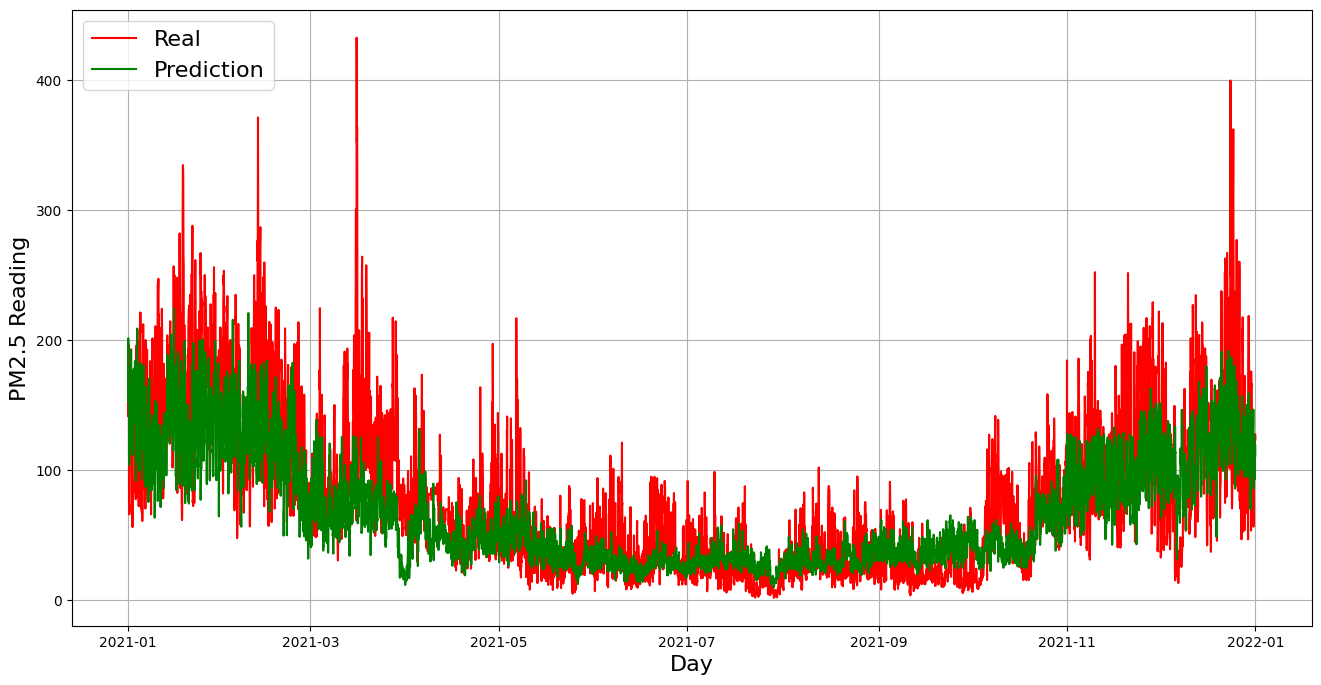

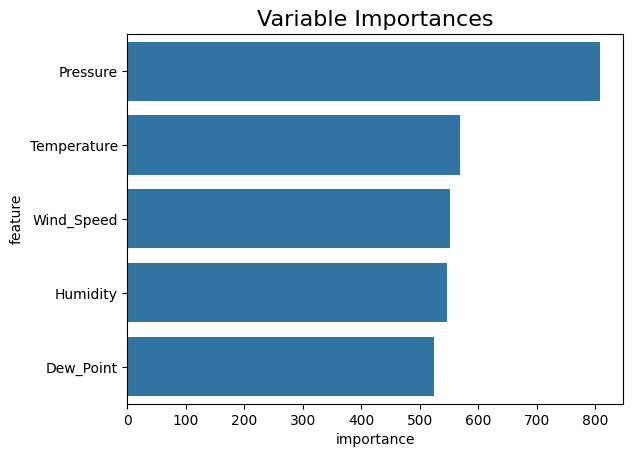

LGBMRegressor(random_state=42)

In [ ]:
train_time_series_with_folds(series["2019":"2021"],horizon=365*24)

In [ ]:
# model = train_time_series_with_folds(augmented_daily_series[:"2021-12"],horizon=365)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000306 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1310
[LightGBM] [Info] Number of data points in the train set: 1082, number of used features: 21
[LightGBM] [Info] Start training from score 0.261213


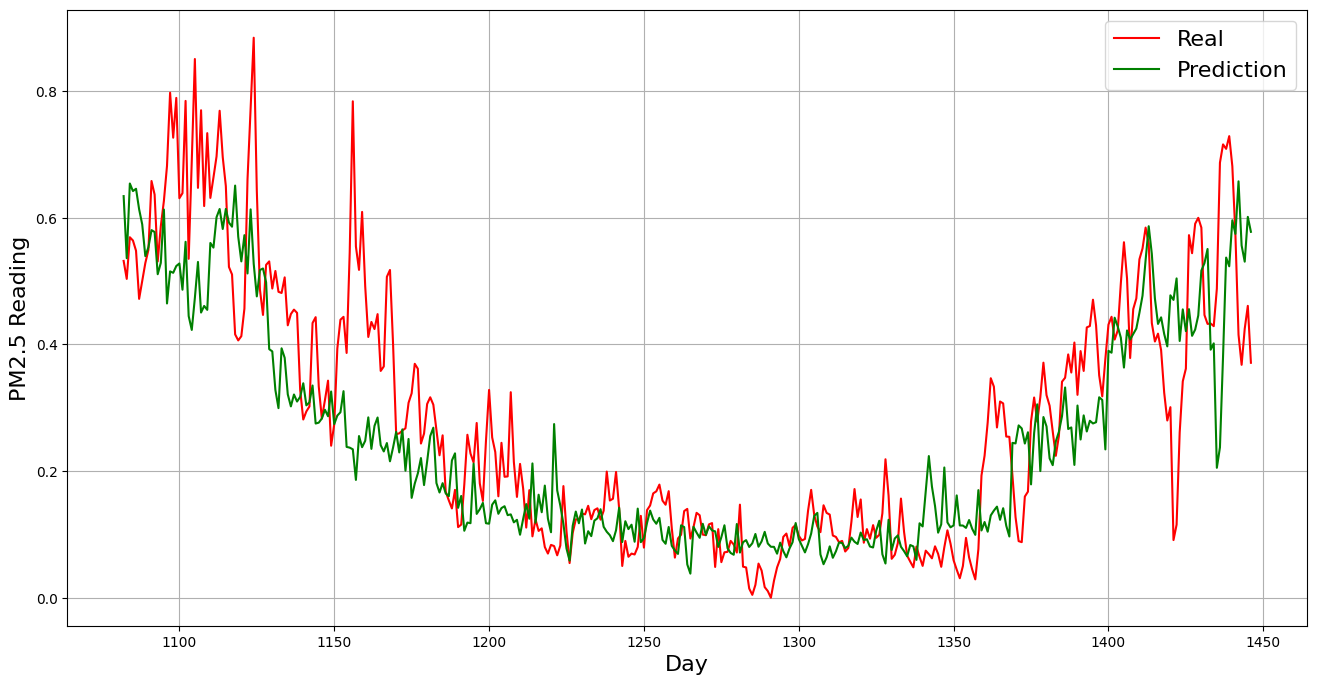

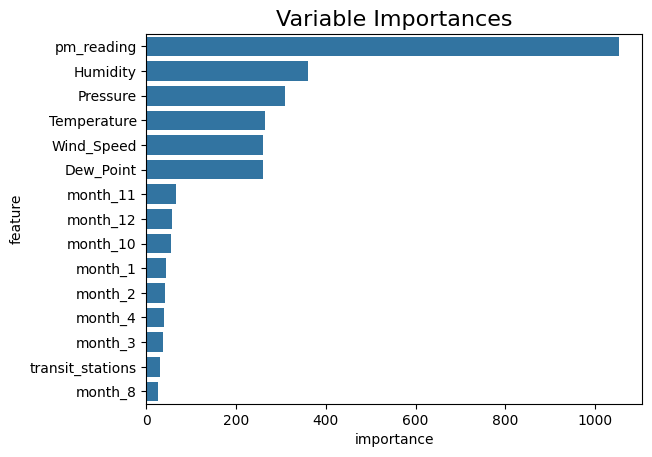

In [ ]:
model = train_time_series_with_folds(daily_series_for_model,horizon=365)

In [ ]:
feature = ['pm_reading','Temperature','Dew_Point','Humidity','Pressure','Wind_Speed','transit_stations','workplaces','residential']
colors= ['#4B0150','#FFA500','#EADAA2','#87CEEB','#2B65EC','#C38EC7','#C04000','#EB5406','#CCCCFF']

df_importances = pd.DataFrame({
    'feature': model.booster_.feature_name(),
    'importance': model.feature_importances_,
    'color': '#666666',
}).sort_values(by='importance', ascending=False)

df_importances.loc[df_importances['feature'].str.contains("month"),'color'] = '#848482'
for factor,color in zip(feature,colors):
  df_importances.loc[df_importances.feature==factor,'color']=color
df_importances.T

,8,2,4,0,3,1,19,20,18,9,...,12,11,5,16,17,14,7,13,15,6
feature,pm_reading,Humidity,Pressure,Temperature,Wind_Speed,Dew_Point,month_11,month_12,month_10,month_1,...,month_4,month_3,transit_stations,month_8,month_9,month_6,residential,month_5,month_7,workplaces
importance,1053,360,309,265,261,260,65,56,54,43,...,40,36,31,25,24,23,18,17,12,6
color,#4B0150,#87CEEB,#2B65EC,#FFA500,#C38EC7,#EADAA2,#848482,#848482,#848482,#848482,...,#848482,#848482,#C04000,#848482,#848482,#848482,#CCCCFF,#848482,#848482,#EB5406


<Axes: xlabel='importance', ylabel='feature'>

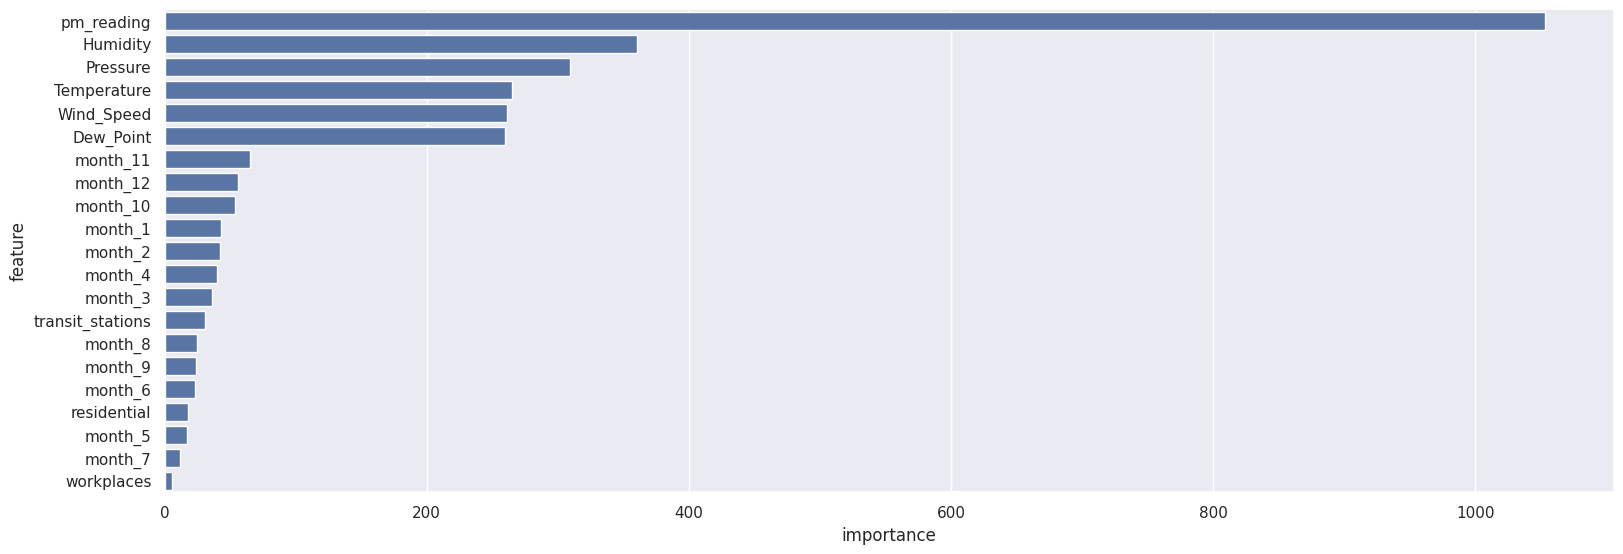

In [ ]:
# sns.set()
sns.set(rc={'figure.figsize':(18.7,6.27)})
# sns.barplot(y=df_importances.feature, x=df_importances.importance, palette=df_importances.color)
sns.barplot(y=df_importances.feature, x=df_importances.importance)

# Multioutput Regression

## OLS

In [ ]:
series.corr()

,Reading,Temperature,Dew Point,Humidity,Wind Speed,Pressure
Reading,1.000000,-0.576780,-0.721652,-0.171384,-0.407086,0.618649
Temperature,-0.576780,1.000000,0.709806,-0.418142,0.403193,-0.646822
Dew Point,-0.721652,0.709806,1.000000,0.333879,0.342958,-0.758628
Humidity,-0.171384,-0.418142,0.333879,1.000000,-0.084643,-0.122539
Wind Speed,-0.407086,0.403193,0.342958,-0.084643,1.000000,-0.422350
Pressure,0.618649,-0.646822,-0.758628,-0.122539,-0.422350,1.000000


In [ ]:
fig = go.Figure(data=go.Heatmap(
                   z=series.corr(),
                   x=series.columns,
                   y=series.columns,
                  #  colorscale='rdylbu',
                   colorscale='greys',
                   text=series.corr().values.round(2),
                   texttemplate="%{text}",
                   zmin=-1,
                   zmax=1))

fig.update_layout(
    title='Correlation Heatmap',
    xaxis_title='Variables',
    yaxis_title='Variables',
    width=900,
    height=900,
    font=dict(
        size=18,
    )
)
fig.show()


In [ ]:
import statsmodels.api as sm
import pandas as pd

horizon = 365
X_for_model = daily_series_for_model.drop('Reading', axis=1)
y_for_model = daily_series_for_model['Reading']

#take last week of the dataset for validation
X_train_for_model, X_test_for_model = X_for_model.iloc[:-horizon,:], X_for_model.iloc[-horizon:,:]
y_train_for_model, y_test_for_model = y_for_model.iloc[:-horizon], y_for_model.iloc[-horizon:]

# print(X_train_for_model,y_train_for_model)

ols_model = sm.OLS(y_train_for_model, X_train_for_model).fit()
# coefficients[f'Target_'] = ols_model.params  # Store coefficients for each target
print(f"OLS Summary for Target {i+1}")
print(ols_model.summary())

OLS Summary for Target 8
                            OLS Regression Results                            
Dep. Variable:                Reading   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.804
Method:                 Least Squares   F-statistic:                     223.3
Date:                Fri, 21 Mar 2025   Prob (F-statistic):               0.00
Time:                        11:31:17   Log-Likelihood:                 1091.2
No. Observations:                1082   AIC:                            -2140.
Df Residuals:                    1061   BIC:                            -2036.
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Temperature    

In [ ]:
# Assuming X_train is your feature matrix and y_train is an n x 7 matrix
X_train_with_const = sm.add_constant(X_train)  # Adds a constant term to the predictors

# Fit an OLS model for each output variable
coefficients = {}
ols_models = []

for i in range(y_train.shape[1]):
    ols_model = sm.OLS(y_train.iloc[:, i], X_train).fit()
    ols_models.append(ols_model)
    coefficients[f'Target_{i+1}'] = ols_model.params  # Store coefficients for each target
    print(f"OLS Summary for Target {i+1}")
    print(ols_model.summary())

# If you want to access the coefficients as a DataFrame
coefficients_df = pd.DataFrame(coefficients).T
print(coefficients_df)

OLS Summary for Target 1
                                 OLS Regression Results                                 
Dep. Variable:     Reading 1 day after   R-squared (uncentered):                   0.961
Model:                             OLS   Adj. R-squared (uncentered):              0.956
Method:                  Least Squares   F-statistic:                              183.1
Date:                 Fri, 21 Mar 2025   Prob (F-statistic):                        0.00
Time:                         11:31:17   Log-Likelihood:                          889.49
No. Observations:                  711   AIC:                                     -1611.
Df Residuals:                      627   BIC:                                     -1227.
Df Model:                           84                                                  
Covariance Type:             nonrobust                                                  
                              coef    std err          t      P>|t|      [0.025      

In [ ]:
coefficients_df

,Reading 0 days ago,Temperature 0 days ago,Dew Point 0 days ago,Humidity 0 days ago,Wind Speed 0 days ago,Pressure 0 days ago,Reading 1 days ago,Temperature 1 days ago,Dew Point 1 days ago,Humidity 1 days ago,...,Dew Point 12 days ago,Humidity 12 days ago,Wind Speed 12 days ago,Pressure 12 days ago,Reading 13 days ago,Temperature 13 days ago,Dew Point 13 days ago,Humidity 13 days ago,Wind Speed 13 days ago,Pressure 13 days ago
Target_1,0.731305,-0.160260,-0.045703,-0.099004,-0.010923,0.024710,-0.072285,-0.105141,0.061350,-0.028513,...,-0.372804,0.254362,-0.010795,0.204663,0.150538,-0.497821,0.425875,-0.281264,-0.001575,-0.057422
Target_2,0.464903,-0.337391,0.001951,-0.154935,0.031006,0.036096,-0.067930,0.075727,0.052341,0.064218,...,-0.037056,0.030325,0.008737,0.160253,0.110559,-0.711892,0.672610,-0.462459,-0.031786,-0.094234
Target_3,0.259071,-0.220782,0.029743,-0.060549,0.041663,0.013655,-0.015986,-0.000555,-0.039405,0.053629,...,0.309861,-0.239705,-0.012645,0.012097,0.052307,-0.511046,0.634272,-0.410803,-0.050180,-0.029721
Target_4,0.152305,-0.253337,0.015725,-0.039261,0.073294,0.150578,-0.010463,0.314177,-0.313832,0.232926,...,0.517320,-0.343435,-0.037658,0.006394,0.093978,-0.083010,0.233044,-0.143002,-0.030192,0.007833
Target_5,0.101370,-0.026365,-0.197282,0.123092,0.022968,0.135348,0.000884,0.285462,-0.233777,0.164626,...,0.349589,-0.239282,-0.036252,0.048896,0.085226,0.411508,-0.214069,0.181254,-0.004215,-0.010902
Target_6,0.087011,0.004473,-0.181752,0.109702,0.039373,0.218590,-0.025180,0.265972,-0.247162,0.169061,...,-0.185022,0.158326,-0.018992,-0.043060,0.045101,0.257192,-0.109363,0.103113,0.015232,0.051364
Target_7,0.048725,0.072516,-0.229213,0.140777,-0.017601,0.103855,0.108638,-0.187728,0.163952,-0.109969,...,-0.094876,0.092993,0.011042,0.025620,0.002260,0.218144,-0.089528,0.074855,-0.003220,0.041017


In [ ]:
coefficients_df_mean = coefficients_df.abs().iloc[0:1].mean()
coefficients_df_top_coef = coefficients_df_mean.sort_values().tail(28)
coefficients_df_top_coef

,0
Reading 9 days ago,0.150117
Reading 13 days ago,0.150538
Temperature 0 days ago,0.160260
Humidity 4 days ago,0.168681
Pressure 11 days ago,0.189698
Pressure 3 days ago,0.198020
Pressure 7 days ago,0.202245
Pressure 12 days ago,0.204663
Pressure 5 days ago,0.206281
Pressure 6 days ago,0.207168


In [ ]:
weather_factors = ['Reading', 'Temperature', 'Dew Point', 'Humidity', 'Wind Speed', 'Pressure']
days = list(range(14))

reshaped_df = pd.DataFrame(index=weather_factors, columns=days)

# Fill the DataFrame with values from the Series
for factor in weather_factors:
    for day in days:
        # Create the key pattern that matches your Series index
        key = f"{factor} {day} days ago"
        reshaped_df.loc[factor, day] = round(coefficients_df_mean[key],3)

# Rename columns to remove "days ago"
reshaped_df.columns = [f"{day}" for day in days]

# Format the numbers to avoid trailing zeros
# This uses a custom formatter for float values
def format_float(x):
    return f"{x:.3f}".rstrip('0').rstrip('.') if x != 0 else '0'

# Apply the formatter to the DataFrame
formatted_df = reshaped_df.T.map(format_float)

# Generate LaTeX table with formatted values
print(formatted_df.to_latex(escape=False))

\begin{tabular}{lllllll}
\toprule
 & Reading & Temperature & Dew Point & Humidity & Wind Speed & Pressure \\
\midrule
0 & 0.731 & 0.16 & 0.046 & 0.099 & 0.011 & 0.025 \\
1 & 0.072 & 0.105 & 0.061 & 0.029 & 0.037 & 0.049 \\
2 & 0.023 & 0.123 & 0.027 & 0.068 & 0.012 & 0.002 \\
3 & 0.025 & 0.038 & 0.092 & 0.025 & 0.057 & 0.198 \\
4 & 0.024 & 0.276 & 0.227 & 0.169 & 0.091 & 0.209 \\
5 & 0.014 & 0.04 & 0.001 & 0.003 & 0.055 & 0.206 \\
6 & 0.005 & 0.078 & 0.109 & 0.08 & 0.071 & 0.207 \\
7 & 0.084 & 0.395 & 0.321 & 0.227 & 0.081 & 0.202 \\
8 & 0.017 & 0.006 & 0.069 & 0.063 & 0.047 & 0.124 \\
9 & 0.15 & 0.055 & 0.006 & 0.038 & 0.028 & 0.112 \\
10 & 0.145 & 0.56 & 0.421 & 0.309 & 0.019 & 0.025 \\
11 & 0.009 & 0.287 & 0.271 & 0.138 & 0.055 & 0.19 \\
12 & 0.09 & 0.453 & 0.373 & 0.254 & 0.011 & 0.205 \\
13 & 0.151 & 0.498 & 0.426 & 0.281 & 0.002 & 0.057 \\
\bottomrule
\end{tabular}



In [ ]:
# prompt: coefficients_df_top_coef plotly horizontal bar chart with dark silver color with border

import plotly.graph_objects as go

# Assuming coefficients_df_top_coef is defined as in your provided code

fig = go.Figure(go.Bar(
    x=coefficients_df_top_coef.values,
    y=coefficients_df_top_coef.index,
    orientation='h',
    marker=dict(
        color='darkgray',  # Dark silver color
        line=dict(width=1, color='black')  # Black border
    )
))

fig.update_layout(
    title='Top Coefficients',
    xaxis_title='Coefficient Value',
    yaxis_title='Feature',
    height = 900,
    font_size = 18,
    template = 'plotly_white'
)

fig.show()

In [ ]:
from sklearn.multioutput import MultiOutputRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# Standardize the targets
scaler = StandardScaler()
y_train_scaled = scaler.fit_transform(y_train)

# Fit the MultiOutputRegressor on the standardized data
multi_reg = MultiOutputRegressor(LinearRegression())
multi_reg.fit(X_train, y_train_scaled)

# Access coefficients for each target
for i, model in enumerate(multi_reg.estimators_):
    print(f"Coefficients for Target {i+1} (Scaled):")
    print(model.coef_)

Coefficients for Target 1 (Scaled):
[ 3.43149428 -0.89151155 -0.08351924 -0.55794471 -0.05117347  0.11559705
 -0.33827477 -0.58075832  0.3679038  -0.18872976  0.17624121 -0.228942
 -0.1108062   0.49046464  0.20269216  0.26489926 -0.05861012  0.00850485
  0.11302015 -0.26696421 -0.35215275  0.05821212  0.26746503  0.92993254
 -0.11690067  1.21726693 -0.991735    0.74142057 -0.42790948 -0.98360264
  0.06404718  0.10998182  0.07334248 -0.06184072  0.25792578  0.96836161
 -0.02136565  0.29692477 -0.44754797  0.3271409  -0.33279066 -0.97141442
  0.3926499  -1.93939347  1.5789817  -1.12016846  0.37872056  0.9489717
  0.08075085 -0.04253919  0.3844792  -0.33989095 -0.22305857 -0.57771412
 -0.70935564 -0.33905441  0.0971637   0.12675696 -0.13454114  0.52280123
  0.67762323  2.54991026 -1.90906293  1.3979473  -0.08809547 -0.11487693
  0.04079417 -1.43048713  1.34283119 -0.69982625  0.25477719 -0.89016039
 -0.42457904  2.05158209 -1.69021984  1.14532127 -0.05090917  0.95585959
  0.70262168 -2.48

## Regression

In [ ]:
# model_lr = LinearRegression()

# model_lr.fit(X_train, y_train)

# predictions = model_lr.predict(X_test)
# predictions.shape

In [ ]:
models = [
    MultiOutputRegressor(LinearRegression()),
    MultiOutputRegressor(BayesianRidge()),
    MultiOutputRegressor(KNeighborsRegressor(n_neighbors=12)),
    MultiOutputRegressor(tree.DecisionTreeRegressor()),
    # MultiOutputRegressor(GradientBoostingRegressor(random_state=42)),
    MultiOutputRegressor(LGBMRegressor(random_state=42)),
    # MultiOutputRegressor(XGBRegressor(random_state=42,silent=True)),
    # MultiOutputRegressor(MLPRegressor(hidden_layer_sizes=(50,30,10),max_iter=900)),
    # MultiOutputRegressor(MLPRegressor(hidden_layer_sizes=(150,100,50,30,10),max_iter=900))
    MultiOutputRegressor(MLPRegressor(hidden_layer_sizes=(300),max_iter=900))
][:]

In [ ]:
models = {
    'LinearRegression': MultiOutputRegressor(LinearRegression()),
    'BayesianRidge': MultiOutputRegressor(BayesianRidge()),
    'KNeighborsRegressor': MultiOutputRegressor(KNeighborsRegressor()),
    'DecisionTreeRegressor': MultiOutputRegressor(tree.DecisionTreeRegressor()),
    'LGBMRegressor': MultiOutputRegressor(LGBMRegressor(random_state=42)),
    'MLPRegressor': MultiOutputRegressor(MLPRegressor(max_iter=900))
}

# Hyperparameter grids for each model
param_grids = {
    'LinearRegression': {
        # Linear regression has no hyperparameters to tune here
    },
    'BayesianRidge': {
        'estimator__alpha_1': [1e-6, 1e-5, 1e-4],
        'estimator__alpha_2': [1e-6, 1e-5, 1e-4]
    },
    'KNeighborsRegressor': {
        'estimator__n_neighbors': [3, 5, 7, 12],
        'estimator__weights': ['uniform', 'distance']
    },
    'DecisionTreeRegressor': {
        'estimator__max_depth': [3, 5, 10, None],
        'estimator__min_samples_split': [2, 5, 10]
    },
    'LGBMRegressor': {
        'estimator__n_estimators': [100, 200],
        'estimator__learning_rate': [0.01, 0.1, 0.05],
        'estimator__num_leaves': [31, 40, 50]
    },
    'MLPRegressor': {
        'estimator__hidden_layer_sizes': [(50,), (100,), (100, 100)],
        'estimator__activation': ['relu', 'tanh'],
        'estimator__solver': ['adam', 'sgd']
    }
}

In [ ]:
param_grids = {
    'LinearRegression': {},
    'BayesianRidge':{'estimator__alpha_1': [1e-06], 'estimator__alpha_2': [0.0001]},
    'KNeighborsRegressor': {'estimator__n_neighbors': [12], 'estimator__weights': ['uniform']},
    'DecisionTreeRegressor': {'estimator__max_depth': [3], 'estimator__min_samples_split': [10]},
    'LGBMRegressor': {'estimator__learning_rate': [0.05], 'estimator__n_estimators': [100], 'estimator__num_leaves': [31]},
    'MLPRegressor': {'estimator__activation': ['tanh'], 'estimator__hidden_layer_sizes': [(100, 100)], 'estimator__solver': ['adam']}
}

In [ ]:
from sklearn.model_selection import GridSearchCV

# Dictionary to store the results
best_params = {}
best_scores = {}
best_models = {}

# Loop through each model and perform grid search
for model_name, model in models.items():
    print(f"Tuning {model_name}...")

    # Get the hyperparameter grid
    param_grid = param_grids.get(model_name, {})

    # Initialize GridSearchCV
    grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=3, n_jobs=-1, scoring='neg_mean_squared_error')

    # Fit grid search
    grid_search.fit(X_train, y_train)

    # Get best parameters and score
    best_params[model_name] = grid_search.best_params_
    best_scores[model_name] = grid_search.best_score_
    best_models[model_name] = grid_search.best_estimator_

    print(f"Best parameters for {model_name}: {best_params[model_name]}")
    print(f"Best score for {model_name}: {best_scores[model_name]}")

# Summarize the results
print("Hyperparameter Tuning Results:")
for model_name in models.keys():
    print(f"{model_name} - Best Params: {best_params[model_name]}, Best Score: {best_scores[model_name]}")

Tuning LinearRegression...
Best parameters for LinearRegression: {}
Best score for LinearRegression: -0.01202318365997763
Tuning BayesianRidge...
Best parameters for BayesianRidge: {'estimator__alpha_1': 1e-06, 'estimator__alpha_2': 0.0001}
Best score for BayesianRidge: -0.01086723014233814
Tuning KNeighborsRegressor...
Best parameters for KNeighborsRegressor: {'estimator__n_neighbors': 12, 'estimator__weights': 'uniform'}
Best score for KNeighborsRegressor: -0.012658580777966147
Tuning DecisionTreeRegressor...
Best parameters for DecisionTreeRegressor: {'estimator__max_depth': 3, 'estimator__min_samples_split': 10}
Best score for DecisionTreeRegressor: -0.017042769403379763
Tuning LGBMRegressor...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000814 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 17457
[LightGBM] [Inf

In [ ]:
# Best parameters for LinearRegression: {}
# Best score for LinearRegression: -0.01202318365997763
# Tuning BayesianRidge...
# Best parameters for BayesianRidge: {'estimator__alpha_1': 1e-06, 'estimator__alpha_2': 0.0001}
# Best score for BayesianRidge: -0.01086723014233814
# Tuning KNeighborsRegressor...
# Best parameters for KNeighborsRegressor: {'estimator__n_neighbors': 12, 'estimator__weights': 'uniform'}
# Best score for KNeighborsRegressor: -0.012658580777966147
# Tuning DecisionTreeRegressor...
# Best parameters for DecisionTreeRegressor: {'estimator__max_depth': 3, 'estimator__min_samples_split': 10}
# Best score for DecisionTreeRegressor: -0.016816045707919083
# Best parameters for LGBMRegressor: {'estimator__learning_rate': 0.05, 'estimator__n_estimators': 100, 'estimator__num_leaves': 31}
# # Best score for LGBMRegressor: -0.01206690513744785
# Tuning MLPRegressor...
# Best parameters for MLPRegressor: {'estimator__activation': 'tanh', 'estimator__hidden_layer_sizes': (100, 100), 'estimator__solver': 'adam'}
# Best score for MLPRegressor: -0.012235070029391093

# Hyperparameter Tuning Results:
# LinearRegression - Best Params: {}, Best Score: -0.01202318365997763
# BayesianRidge - Best Params: {'estimator__alpha_1': 1e-06, 'estimator__alpha_2': 0.0001}, Best Score: -0.01086723014233814
# KNeighborsRegressor - Best Params: {'estimator__n_neighbors': 12, 'estimator__weights': 'uniform'}, Best Score: -0.012658580777966147
# DecisionTreeRegressor - Best Params: {'estimator__max_depth': 3, 'estimator__min_samples_split': 10}, Best Score: -0.016816045707919083
# LGBMRegressor - Best Params: {'estimator__learning_rate': 0.05, 'estimator__n_estimators': 100, 'estimator__num_leaves': 31}, Best Score: -0.01206690513744785
# MLPRegressor - Best Params: {'estimator__activation': 'tanh', 'estimator__hidden_layer_sizes': (100, 100), 'estimator__solver': 'adam'}, Best Score: -0.012235070029391093

In [ ]:
models['LinearRegression'].__class__.__name__

'MultiOutputRegressor'

In [ ]:
# models_name = ['LinearRegression','BayesianRidge','GradientBoostingRegressor','LGBMRegressor','XGBRegressor','MLPRegressor']
models_name = ['LinearRegression','BayesianRidge','KNeighborsRegressor','DecisionTreeRegressor','LGBMRegressor','MLPRegressor']
# models_color = ['#38ACEC','#617C58','#342D7E','#F6BE00','#C04000','#726E6D']
models_color = ['#53C8AC','#AAD684','#FBF87D','#FCC66E','#F298B1','#9876B1']
eval_matrices = ['model','mae','mse','rmse','mape','mdae','mase'][:-1]

models_color_series = pd.Series(index=models_name,name='color',data=models_color)
models_color_series

,color
LinearRegression,#53C8AC
BayesianRidge,#AAD684
KNeighborsRegressor,#FBF87D
DecisionTreeRegressor,#FCC66E
LGBMRegressor,#F298B1
MLPRegressor,#9876B1


In [ ]:
# for model in models[:]:
#   print(model)
#   model.fit(X_train, y_train)

In [ ]:
# models[-1] = MultiOutputRegressor(MLPRegressor(hidden_layer_sizes=(300),max_iter=900,learning_rate='adaptive'))
# models[-1].fit(X_train, y_train)

# models[-2] = MultiOutputRegressor(KNeighborsRegressor(n_neighbors=12))
# models[-2].fit(X_train, y_train)

# models[-3] = MultiOutputRegressor(tree.DecisionTreeRegressor())
# models[-3].fit(X_train, y_train)

In [ ]:
import pickle

filename = 'traditional_models.sav'

In [ ]:
pickle.dump(models, open(filename, 'wb'))

In [ ]:
models = pickle.load(open(filename, 'rb'))

In [ ]:
models

{'LinearRegression': MultiOutputRegressor(estimator=LinearRegression()),
 'BayesianRidge': MultiOutputRegressor(estimator=BayesianRidge()),
 'KNeighborsRegressor': MultiOutputRegressor(estimator=KNeighborsRegressor()),
 'DecisionTreeRegressor': MultiOutputRegressor(estimator=DecisionTreeRegressor()),
 'LGBMRegressor': MultiOutputRegressor(estimator=LGBMRegressor(random_state=42)),
 'MLPRegressor': MultiOutputRegressor(estimator=MLPRegressor(max_iter=900))}

In [ ]:
ml_models = models.copy()

## Evaluation

In [ ]:
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def mean_absolute_scaled_error(y, y_hat, y_train):

    ## Naive in-sample Forecast
    # naive_y_hat = y_train[:-1]
    # naive_y = y_train[1:]

    naive_y_hat = y_train.values[:-1]
    naive_y = y_train.values[1:]
    # print(y_train.shape,naive_y_hat,naive_y)

    ## Calculate MAE (in sample)
    mae_in_sample = np.mean(np.abs(naive_y - naive_y_hat))
    mae = np.mean(np.abs(y - y_hat))

    return mae/mae_in_sample

In [ ]:
def get_performance_metrices(y_test,predictions,model_name):
  metrices = pd.DataFrame(index=range(7),columns=eval_matrices)
  # print(metrices)

  for i in range(7):
    real = y_test.iloc[:,i]
    real.index = real.index.shift(i)
    prediction = pd.Series(predictions[:,i], index=real.index)
    mae = np.round(mean_absolute_error(real, prediction), 3)
    mse = np.round(mean_squared_error(real, prediction), 3)
    # rmse = np.round(mean_squared_error(real, prediction,squared=False), 3)
    rmse = np.round(np.sqrt(mean_squared_error(real, prediction)), 3)
    mape = np.round(mean_absolute_percentage_error(real+1e-1, prediction), 3)
    mdae = np.round(median_absolute_error(real, prediction), 3)
    # r2 = np.round(r2_score(real, prediction), 3)
    # mase = np.round(mean_absolute_scaled_error(real, prediction,y_train), 3)
    metrices.loc[i] = [model_name,mae,mse,rmse,mape,mdae]
  return metrices

def get_models_metrices_concatanated_indexed(models_metrices_list):
  models_metrices_concatanated = pd.concat(models_metrices_list)
  models_metrices_concatanated.index.name = 'time_offset'
  models_metrices_concatanated_indexed = models_metrices_concatanated.set_index([models_metrices_concatanated.index,'model'])
  return models_metrices_concatanated_indexed

In [ ]:
y_test.index

DatetimeIndex(['2020-12-26', '2020-12-28', '2020-12-30', '2021-01-01',
               '2021-01-03', '2021-01-05', '2021-01-07', '2021-01-09',
               '2021-01-11', '2021-01-13',
               ...
               '2021-12-05', '2021-12-07', '2021-12-09', '2021-12-11',
               '2021-12-13', '2021-12-15', '2021-12-17', '2021-12-19',
               '2021-12-21', '2021-12-23'],
              dtype='datetime64[ns]', name='time', length=182, freq='2D')

In [ ]:
models_metrices = dict()
models_metrices_list = []

# for model,model_name in zip(models[:],models_name):
for model_name, model in models.items():
  # print(model)
  model = best_models[model_name]
  predictions = model.predict(X_test)
  print(predictions,y_test)
  metrices = get_performance_metrices(y_test,predictions,model_name)
  # print(metrices)
  models_metrices_list.append(metrices)

models_metrices_concatanated_indexed = get_models_metrices_concatanated_indexed(models_metrices_list)
models_metrices_concatanated_indexed

[[0.65667329 0.6802513  0.66855988 ... 0.66819494 0.65554712 0.63560275]
 [0.80225352 0.69405774 0.70788854 ... 0.6566084  0.76094921 0.74735131]
 [0.67000496 0.63990469 0.62096573 ... 0.73138483 0.69006437 0.69498642]
 ...
 [0.49943901 0.44089642 0.44385144 ... 0.46906888 0.52736069 0.54337307]
 [0.73081742 0.66940766 0.59506934 ... 0.59273616 0.59855657 0.62144457]
 [0.67551219 0.64347769 0.60979347 ... 0.62820595 0.67431738 0.64098892]]             Reading 1 day after  Reading 2 day after  Reading 3 day after  \
time                                                                        
2020-12-26             0.740841             0.845683             0.658109   
2020-12-28             0.658109             0.646688             0.726725   
2020-12-30             0.726725             0.601416             0.569347   
2021-01-01             0.569347             0.643719             0.637917   
2021-01-03             0.637917             0.619644             0.533668   
...              

,,mae,mse,rmse,mape,mdae
time_offset,model,,,,,
0,LinearRegression,0.059,0.006,0.079,34.29,0.044
1,LinearRegression,0.072,0.01,0.101,34.05,0.049
2,LinearRegression,0.084,0.012,0.111,35.3,0.06
3,LinearRegression,0.086,0.014,0.118,33.192,0.069
4,LinearRegression,0.093,0.015,0.124,35.154,0.067
5,LinearRegression,0.093,0.016,0.125,32.995,0.072
6,LinearRegression,0.097,0.016,0.127,33.446,0.071
0,BayesianRidge,0.058,0.006,0.077,34.301,0.042
1,BayesianRidge,0.075,0.011,0.105,34.898,0.052


In [ ]:
for matrix in models_metrices_concatanated_indexed:
# for matrix in models_metrices_concatanated_indexed[['mape']]:
  # print(matrix)
  df = models_metrices_concatanated_indexed[matrix].unstack()
  # df.columns = models_name
  df = df[models_name]
  # print(df)
  fig = go.Figure()

  for alg in df:
    fig.add_trace(go.Bar(
        x=df.index+1,
        y=df[alg],
        name=alg,
        marker_color=models_color_series[alg]
    ))

  # Here we modify the tickangle of the xaxis, resulting in rotated labels.
  fig.update_layout(barmode='group', xaxis_tickangle=-45, title=matrix,font_size=18,xaxis_title='days',yaxis_title='score',
                    # legend=dict(orientation="h",y=1,yanchor="bottom"))
                    )
                    #legend=dict(orientation="h",yanchor="bottom",y=1.02,xanchor="right",x=1))
  fig.show()

In [ ]:
model

MultiOutputRegressor(estimator=MLPRegressor(activation='tanh',
                                            hidden_layer_sizes=(100, 100),
                                            max_iter=900))

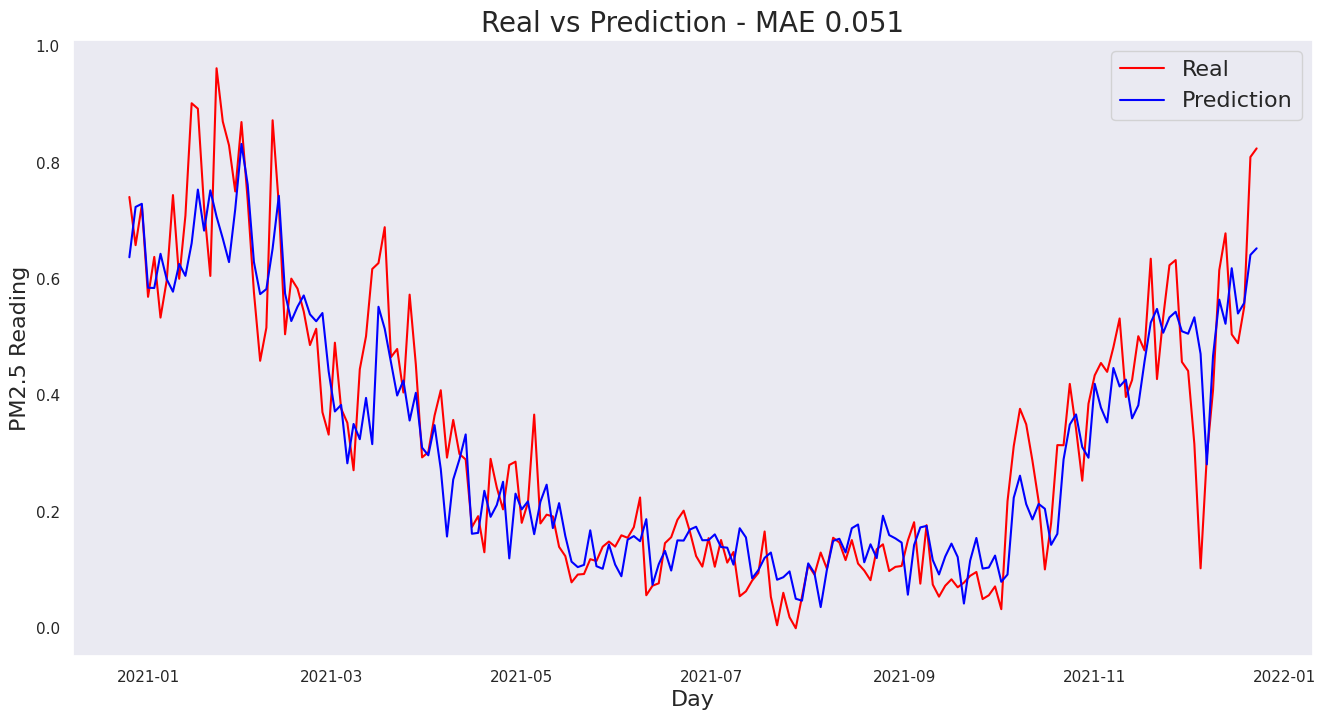

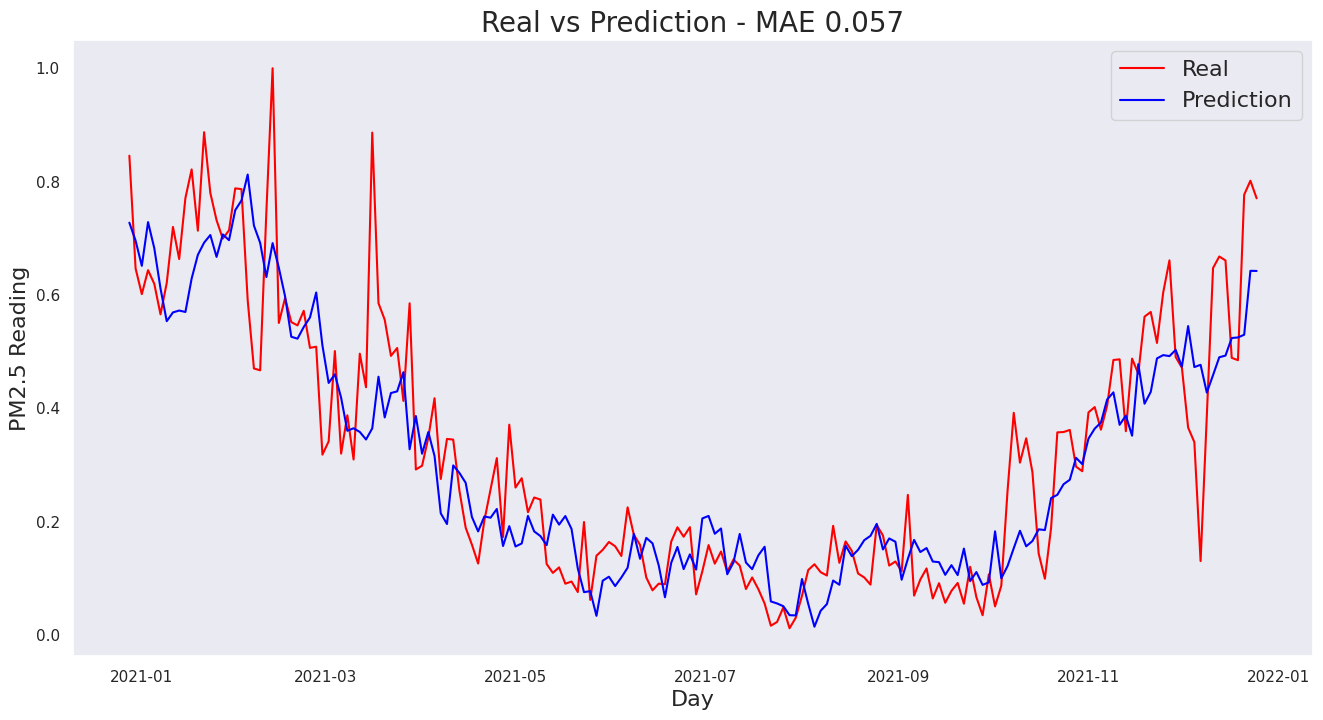

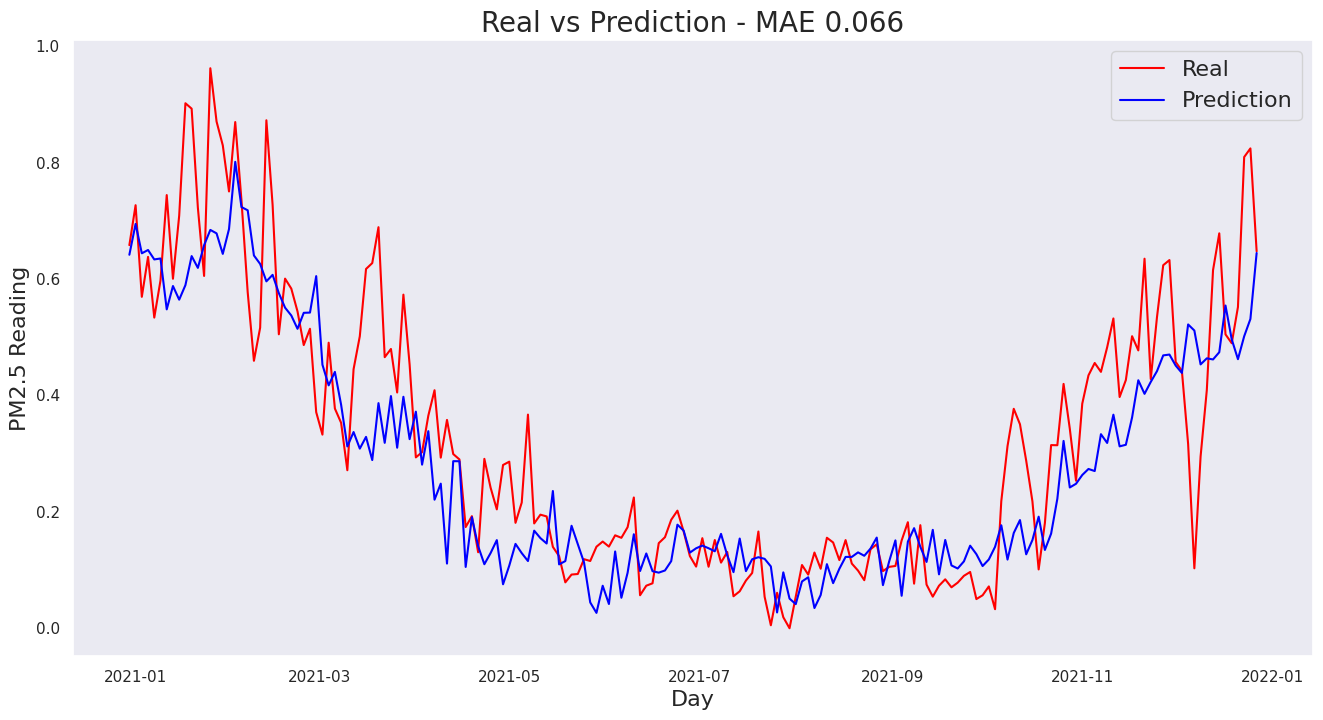

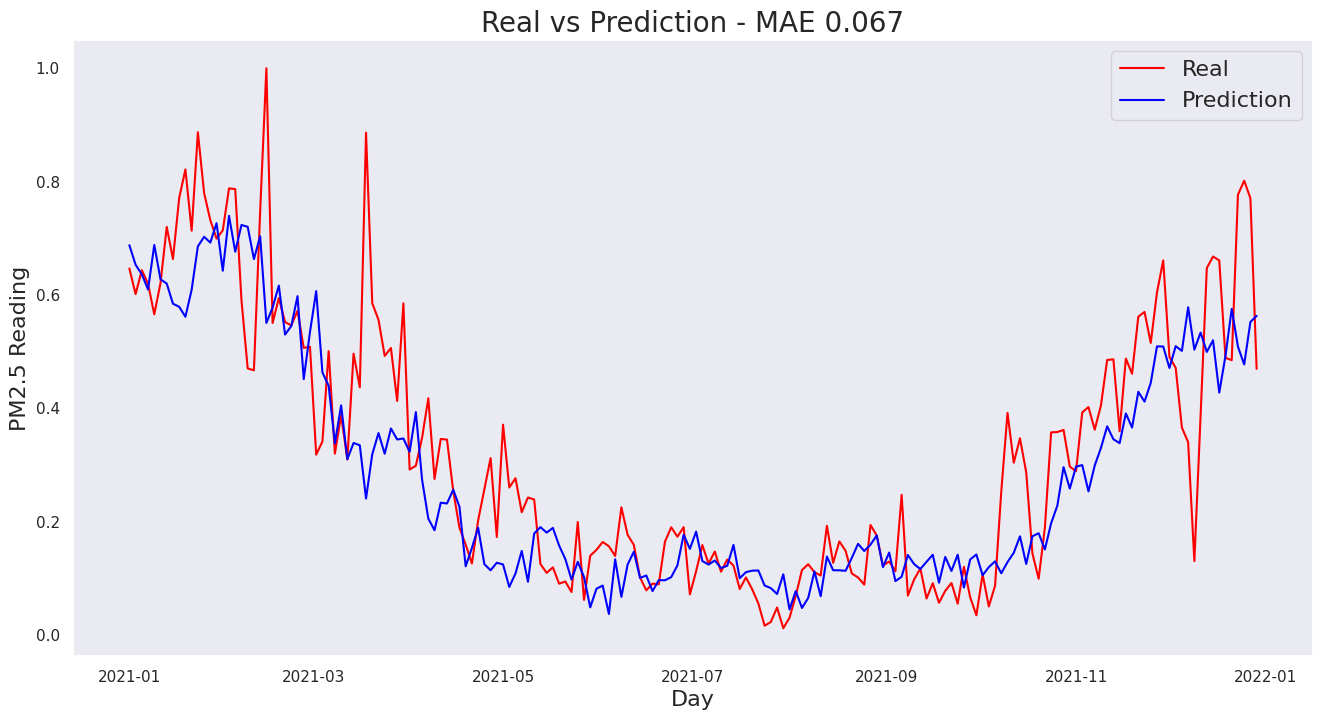

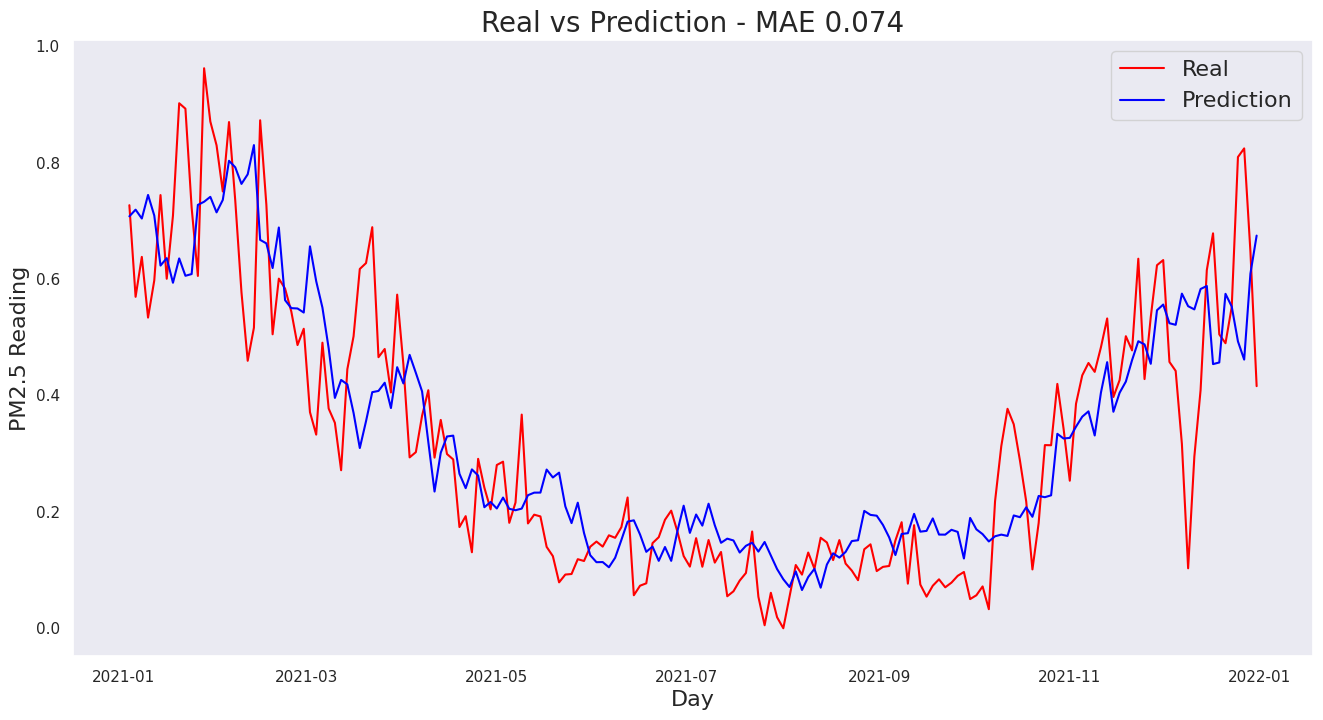

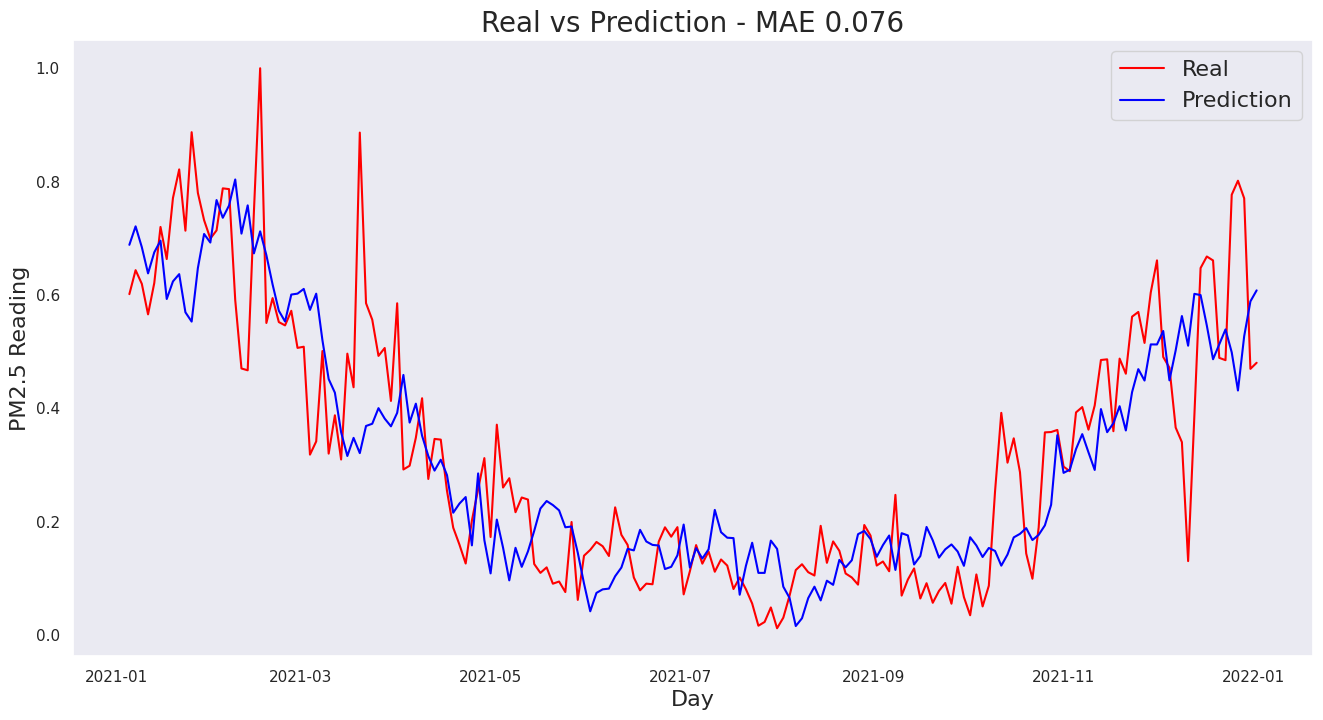

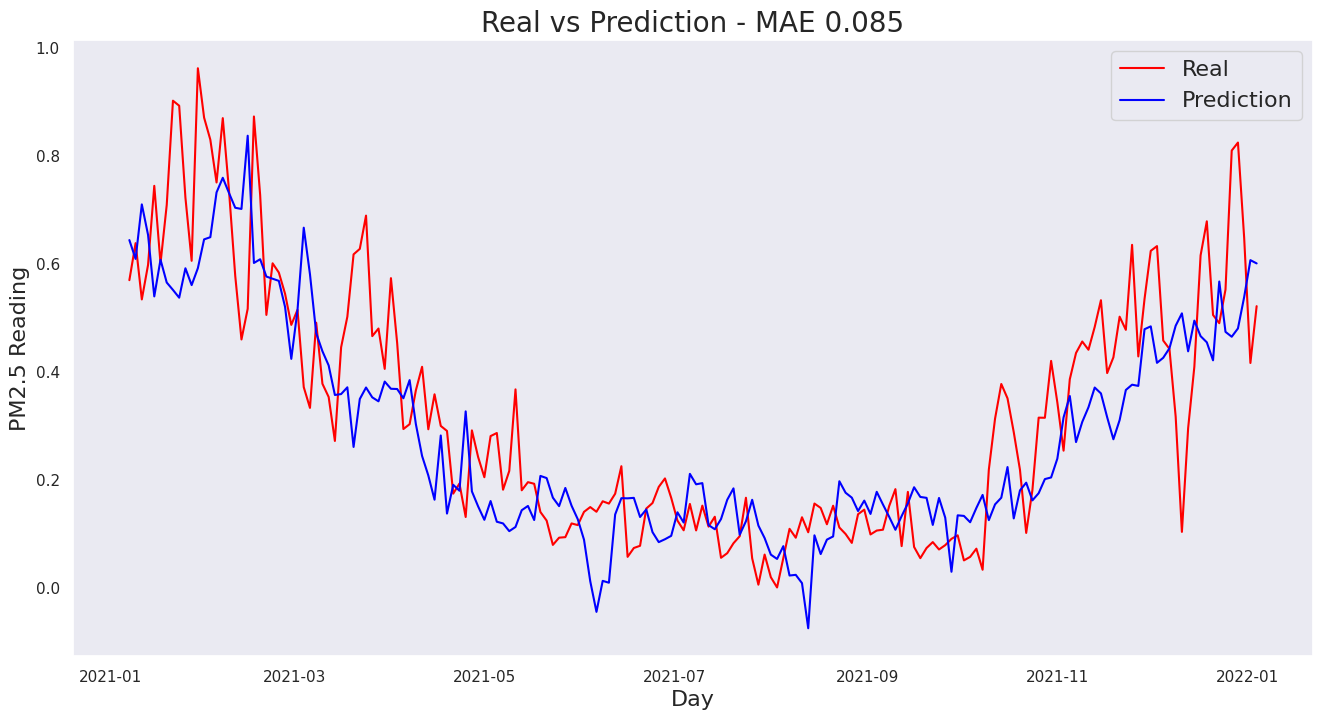

In [ ]:
#calculate MAE
# mae = np.round(mean_squared_error(y_test, predictions), 3)
predictions = model.predict(X_test)

for i in range(7):
  real = y_test.iloc[:,i]
  real.index = real.index.shift(i)
  # real.index = real.asfreq('H').index.shift(i)
  prediction = pd.Series(predictions[:,i], index=real.index)
  # print(pd.Series(predictions[:,i], index=real.index).corr(real))
  # print(pd.Series(predictions[:,i], index=real.index).shift(-i).corr(real))
  mae = np.round(median_absolute_error(real, prediction), 3)
  # print(mae)

  #plot reality vs prediction for the last week of the dataset
  fig = plt.figure(figsize=(16,8))
  plt.title(f'Real vs Prediction - MAE {mae}', fontsize=20)

  plt.plot(real, color='red')
  plt.plot(prediction, color='blue')
  # plt.plot(pd.Series(predictions[:,i], index=real.index).shift(-i-1), color='blue')
  # plt.plot(pd.DataFrame(predictions, index=y_test.index), color='green')
  plt.xlabel('Day', fontsize=16)
  plt.ylabel('PM2.5 Reading', fontsize=16)
  plt.legend(labels=['Real', 'Prediction'], fontsize=16)
  plt.grid()
  plt.show()

# #create a dataframe with the variable importances of the model
# df_importances = pd.DataFrame({
#     'feature': model.booster_.feature_name(),
#     'importance': model.feature_importances_
# }).sort_values(by='importance', ascending=False).head(15)

# #plot variable importances of the model
# plt.title('Variable Importances', fontsize=16)
# sns.barplot(x=df_importances.importance, y=df_importances.feature, orient='h')
# plt.show()


In [ ]:
# # Inverse transform for each subset of X
# X_train_original = pd.DataFrame(norm_X.inverse_transform(X_train), columns=X.columns, index=X_train.index)
# X_val_original = pd.DataFrame(norm_X.inverse_transform(X_val), columns=X.columns, index=X_val.index)
# X_test_original = pd.DataFrame(norm_X.inverse_transform(X_test), columns=X.columns, index=X_test.index)

# # Inverse transform for each subset of y
# y_train_original = pd.DataFrame(norm_y.inverse_transform(y_train), columns=y.columns, index=y_train.index)
# y_val_original = pd.DataFrame(norm_y.inverse_transform(y_val), columns=y.columns, index=y_val.index)
# y_test_original = pd.DataFrame(norm_y.inverse_transform(y_test), columns=y.columns, index=y_test.index)

In [ ]:
y_test

,Reading 1 day after,Reading 2 day after,Reading 3 day after,Reading 4 day after,Reading 5 day after,Reading 6 day after,Reading 7 day after
time,,,,,,,
2020-12-26,0.740841,0.845683,0.658109,0.646688,0.726725,0.601416,0.569347
2020-12-28,0.658109,0.646688,0.726725,0.601416,0.569347,0.643719,0.637917
2020-12-30,0.726725,0.601416,0.569347,0.643719,0.637917,0.619644,0.533668
2021-01-01,0.569347,0.643719,0.637917,0.619644,0.533668,0.565738,0.597579
2021-01-03,0.637917,0.619644,0.533668,0.565738,0.597579,0.621106,0.744130
...,...,...,...,...,...,...,...
2021-12-15,0.504842,0.488990,0.489630,0.484925,0.551850,0.776839,0.809502
2021-12-17,0.489630,0.484925,0.551850,0.776839,0.809502,0.801553,0.824303
2021-12-19,0.551850,0.776839,0.809502,0.801553,0.824303,0.770534,0.647510


In [ ]:
i=0

real = y_test
real_original = pd.DataFrame(norm_y.inverse_transform(y_test), columns=y.columns, index=y_test.index).iloc[:,i]

pred = predictions
pred_original = pd.DataFrame(norm_y.inverse_transform(predictions), columns=real.columns, index=real.index).iloc[:,i]

real_and_prediction = pd.concat((real_original,pred_original),axis=1)
# real_and_prediction = pd.concat((real,pd.Series(predictions[:,i], index=real.index)),axis=1).resample('H').mean()
real_and_prediction.columns = ['ground truth','prediction']
real_and_prediction

,ground truth,prediction
time,,
2020-12-26,167.17,144.502513
2020-12-28,149.06,163.426719
2020-12-30,164.08,164.604439
2021-01-01,129.63,133.035856
2021-01-03,144.64,132.950715
...,...,...
2021-12-15,115.51,140.377554
2021-12-17,112.18,123.351851
2021-12-19,125.80,127.319674


In [ ]:
# i=0
# real = y_test.iloc[:,i]
# pred = pd.Series(predictions[:,i], index=real.index)
# real_and_prediction = pd.concat((real,pred),axis=1)
# # real_and_prediction = pd.concat((real,pd.Series(predictions[:,i], index=real.index)),axis=1).resample('H').mean()
# real_and_prediction.columns = ['ground truth','prediction']

In [ ]:
import plotly.express as px
fig = px.line(real_and_prediction, y=real_and_prediction.columns, x=real_and_prediction.index, color_discrete_sequence = ['grey','black'])
fig.update_traces(opacity=.9)
fig.update_layout(yaxis_title = 'Reading (µgm<sup>-3</sup>)', font_size = 18, legend_orientation = 'h', template='plotly_white')
fig.show()

# DNN Prediction

## Data preparation

https://machinelearningmastery.com/how-to-develop-convolutional-neural-network-models-for-time-series-forecasting/

In [ ]:
from math import sqrt
from numpy import split
from numpy import array
from pandas import read_csv
from sklearn.metrics import mean_squared_error
from matplotlib import pyplot
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Flatten
from keras.layers import LSTM
from keras.layers import RepeatVector
from keras.layers import TimeDistributed
from keras.layers import ConvLSTM2D
from keras.callbacks import ModelCheckpoint
from tensorflow.keras.layers import BatchNormalization

In [ ]:
batch_size = 32

In [ ]:
# rearrenged_columns = list(X_train.filter(like='Reading').columns) + list(X_train.filter(like='Temperature').columns) + list(X_train.filter(like='Dew Point').columns) + list(X_train.filter(like='Humidity').columns) + list(X_train.filter(like='Wind Speed').columns) + list(X_train.filter(like='Pressure').columns )

In [ ]:
feature_list = daily_series.columns

In [ ]:
rearrenged_columns = []
for rearrenged_column in feature_list:
  rearrenged_columns=rearrenged_columns+list(X_train.filter(like=rearrenged_column).columns)
# rearrenged_columns

In [ ]:
# X_train.shape,X_train["2012":"2014"].shape,X_train["2015":"2015"].shape

In [ ]:
# X_train_dnn = X_train["2012":"2014"][rearrenged_columns].values.reshape(-1,6,28)
# X_valid_dnn = X_train["2015":"2015"][rearrenged_columns].values.reshape(-1,6,28)

n_features = len(feature_list)
X_train_dnn = X_train[rearrenged_columns].values.reshape(-1,n_features,window_length)
X_val_dnn = X_val[rearrenged_columns].values.reshape(-1,n_features,window_length)
X_test_dnn = X_test[rearrenged_columns].values.reshape(-1,n_features,window_length)

# X_train_dnn = X_train[rearrenged_columns].values.reshape(-1,6,7*24)
# X_test_dnn = X_test[rearrenged_columns].values.reshape(-1,6,7*24)

In [ ]:
X_train_dnn.shape, X_val_dnn.shape, X_test_dnn.shape

((711, 6, 14), (183, 6, 14), (182, 6, 14))

In [ ]:
y_train.iloc[:,0].shape

(711,)

In [ ]:
X_train_dnn_endc = X_train.values.reshape(-1,window_length,n_features)
X_val_dnn_endc = X_val.values.reshape(-1,window_length,n_features)
X_test_dnn_endc = X_test.values.reshape(-1,window_length,n_features)

X_train_dnn_endc.shape,X_val_dnn_endc.shape,X_test_dnn_endc.shape,y_train.shape,y_val.shape,y_test.shape

((711, 14, 6), (183, 14, 6), (182, 14, 6), (711, 7), (183, 7), (182, 7))

In [ ]:
n_steps, n_length, n_features, n_past,n_outputs =  2,7,6,14,7

In [ ]:
# train_x = X_train[rearrenged_columns].values.reshape((-1, n_features, n_steps,n_length,1))
# train_x = np.transpose(train_x,(0,2,4,3,1))

train_x = X_train.values.reshape((-1, n_steps, 1, n_length, n_features))
val_x = X_val.values.reshape((-1, n_steps, 1, n_length, n_features))
test_x = X_test.values.reshape((-1, n_steps, 1, n_length, n_features))

# train_x[0,0,0].shape,train_x[0,0,0]

# reshape output into [samples, timesteps, features]
train_y = y_train.values.reshape((y_train.shape[0], y_train.shape[1], 1))
val_y = y_val.values.reshape((y_val.shape[0], y_val.shape[1], 1))
test_y = y_test.values.reshape((y_test.shape[0], y_test.shape[1], 1))
# train_y = train_y.reshape((train_y.shape[0], 1, train_y.shape[1] * train_y.shape[2]))

train_x.shape,train_y.shape,test_x.shape,test_y.shape

((711, 2, 1, 7, 6), (711, 7, 1), (182, 2, 1, 7, 6), (182, 7, 1))

In [ ]:
def loss_curve(history):
  loss = history.history['loss']
  val_loss = history.history['val_loss']

  loss_df = pd.DataFrame({'loss':loss,'val_loss':val_loss})
  fig = px.line(loss_df, y=loss_df.columns, x=loss_df.index)
  fig.update_traces(opacity=.9)
  fig.update_layout(yaxis_title = 'loss', font_size = 15, legend_orientation = 'h', template = "plotly_white", width=450)
  fig.show()

In [ ]:
loss_curve(history_endc)

NameError: name 'history_endc' is not defined

## CNN

In [ ]:
# model_cnn = Sequential()
# model_cnn.add(Input(shape=(X_train_dnn.shape[1], X_train_dnn.shape[2])))  # Use Input layer for input shape
# model_cnn.add(Conv1D(32, 2, activation="relu"))
# model_cnn.add(MaxPooling1D(pool_size=2))
# model_cnn.add(Flatten())
# model_cnn.add(Dense(64, activation="relu"))
# model_cnn.add(Dense(y_train.shape[1]))
# # model_cnn.add(Dense(1))
# model_cnn.compile(loss="mse", optimizer="adam")

In [ ]:
# history_cnn = model_cnn.fit(X_train_dnn, y_train, batch_size=batch_size,epochs=90, verbose=1,validation_data=(X_test_dnn,y_test))
# history_cnn = model_cnn.fit(X_train_dnn, y_train.iloc[:,0], batch_size=batch_size,epochs=90, verbose=1,validation_data=(X_test_dnn,y_test.iloc[:,0]))
# history_cnn = model_cnn.fit(X_train_dnn, y_train, batch_size=1024,epochs=300, verbose=1)

In [ ]:
# import numpy as np
# import tensorflow as tf
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Dense, Conv1D, MaxPooling1D, Flatten
from sklearn.model_selection import GridSearchCV
from sklearn.base import BaseEstimator

class KerasRegressorWrapper(BaseEstimator):
    def __init__(self, conv_filters=32, conv_kernel=2, pool_size=2, dense_units=64, batch_size=32, epochs=50):
        self.conv_filters = conv_filters
        self.conv_kernel = conv_kernel
        self.pool_size = pool_size
        self.dense_units = dense_units
        self.batch_size = batch_size
        self.epochs = epochs
        self.model = None
        self.history = None  # To store training history

    def create_model(self):
        model = Sequential()
        model.add(Input(shape=(X_train_dnn.shape[1], X_train_dnn.shape[2])))

        model.add(Conv1D(self.conv_filters, self.conv_kernel, activation="relu"))
        model.add(MaxPooling1D(pool_size=self.pool_size))
        model.add(Flatten())
        model.add(Dense(self.dense_units, activation="relu"))
        model.add(Dense(y_train.shape[1]))  # Output layer with number of outputs matching the target dimensions
        model.compile(loss="mse", optimizer="adam")
        return model

    def fit(self, X, y, X_val=None, y_val=None):
        self.model = self.create_model()
        if X_val is not None and y_val is not None:
            # Include validation data during training
            self.history = self.model.fit(X, y, batch_size=self.batch_size, epochs=self.epochs, verbose=1,
                                          validation_data=(X_val, y_val))
        else:
            # Train without validation data
            self.history = self.model.fit(X, y, batch_size=self.batch_size, epochs=self.epochs, verbose=1)
        return self

    def predict(self, X):
        return self.model.predict(X)

    def score(self, X, y):
        return -self.model.evaluate(X, y, verbose=1)  # Negative MSE for scoring (higher is better)


# Define the grid search parameters
# param_grid = {
#     'conv_filters': [32, 64],
#     'conv_kernel': [2, 3],
#     'pool_size': [2],
#     'dense_units': [32, 64],
#     'batch_size': [32, 64],
#     'epochs': [50, 100]
# }

param_grid = {'batch_size': [64], 'conv_filters': [32], 'conv_kernel': [2], 'dense_units': [64], 'epochs': [50], 'pool_size': [2]}

# Create the grid search
grid = GridSearchCV(estimator=KerasRegressorWrapper(), param_grid=param_grid, cv=3, n_jobs=1, verbose=2)

# Fit the grid search
grid_result = grid.fit(X_train_dnn, y_train, X_val=X_val_dnn, y_val=y_val)

# Print the best parameters and score
print("Best parameters: ", grid_result.best_params_)
print("Best score: ", -grid_result.best_score_)  # Convert back to MSE

# Get the best model
best_model = grid_result.best_estimator_.model

# Evaluate the best model on the test set
test_loss = best_model.evaluate(X_test_dnn, y_test)
print(f"Test Loss: {test_loss}")

# If you want to make predictions
predictions = best_model.predict(X_test_dnn)

Fitting 3 folds for each of 1 candidates, totalling 3 fits
Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.2272 - val_loss: 0.1226
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0934 - val_loss: 0.0758
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0642 - val_loss: 0.0689
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0576 - val_loss: 0.0609
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0455 - val_loss: 0.0513
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0364 - val_loss: 0.0394
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0277 - val_loss: 0.0309
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0200 - val_loss: 0.0253
Epoch 9/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0179 - val_loss: 0.0240
Epoch 10/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0179 - val_loss: 0.0212
Epoch 11/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0155 - val_loss: 0.0227
Epoch 12/50
8/8 ━━━━━━━━━━━━━━━━━━

In [ ]:
history_cnn = grid_result.best_estimator_.history
model_cnn = best_model

In [ ]:
# plot_model(model_cnn,show_shapes=True)

In [ ]:
model_cnn.save('model_cnn.h5')  # creates a HDF5 file 'my_model.h5'
# model_cnn.save('cnn_hourly.h5')  # creates a HDF5 file 'my_model.h5'
# del model  # deletes the existing model

# returns a compiled model
# identical to the previous one
# model = load_model('cnn_daily.h5')

In [ ]:
type(history_cnn)

keras.src.callbacks.history.History

In [ ]:
print(history_cnn.history.keys())

dict_keys(['loss', 'val_loss'])


In [ ]:
loss_curve(history_cnn)

In [ ]:
# predictions_cnn = model_cnn.predict(X_test_dnn)
predictions_cnn = predictions
metrices_cnn=get_performance_metrices(y_test,predictions_cnn,'CNN')
print(metrices_cnn)

  model    mae    mse   rmse    mape   mdae
0   CNN   0.08  0.013  0.113  41.004  0.058
1   CNN  0.085  0.015  0.121  36.475   0.06
2   CNN  0.089  0.015  0.124  38.224  0.054
3   CNN  0.091  0.016  0.128  42.053  0.061
4   CNN  0.095  0.017   0.13  39.078  0.064
5   CNN  0.095  0.017  0.131  39.485  0.068
6   CNN  0.099  0.018  0.135  40.279  0.068


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/pytho

In [ ]:
predictions_cnn_original = pd.Series(norm_y.inverse_transform(predictions_cnn)[:,i], index=real.index)
real_original = pd.DataFrame(norm_y.inverse_transform(y_test), columns=y.columns, index=y_test.index).iloc[:,i]

In [ ]:
i=0
# real = y_test.iloc[:,i]
real_and_prediction = pd.concat((real_original,predictions_cnn_original),axis=1)
# real_and_prediction = pd.concat((real,pd.Series(predictions[:,i], index=real.index)),axis=1).resample('H').mean()
real_and_prediction.columns = ['ground truth','prediction']

In [ ]:
real_and_prediction

,ground truth,prediction
time,,
2020-12-26,167.17,165.046906
2020-12-28,149.06,156.568619
2020-12-30,164.08,138.124771
2021-01-01,129.63,151.374161
2021-01-03,144.64,148.345825
...,...,...
2021-12-15,115.51,106.204323
2021-12-17,112.18,124.269135
2021-12-19,125.80,118.564728


In [ ]:
# pred_original = pd.DataFrame(norm_y.inverse_transform(predictions), columns=real.columns, index=real.index).iloc[:,i]

# norm_y.inverse_transform(real_and_prediction.iloc[:,0].values.reshape(-1,1))

In [ ]:
import plotly.express as px
fig = px.line(real_and_prediction, y=real_and_prediction.columns, x=real_and_prediction.index, color_discrete_sequence = ['grey','black'])
fig.update_traces(opacity=.9)
fig.update_layout(yaxis_title = 'Reading (µgm<sup>-3</sup>)', font_size = 18, legend_orientation = 'h', template='plotly_white')
fig.show()

## CNN with LSTM

In [ ]:
# model_cnn_with_rnn = Sequential()
# model_cnn_with_rnn.add(Conv1D(32, 2, activation="relu", input_shape=(X_train_dnn.shape[1], X_train_dnn.shape[2])))
# model_cnn_with_rnn.add(MaxPooling1D(pool_size=2))

# model_cnn_with_rnn.add(Bidirectional(LSTM(128, kernel_regularizer=l2(0.01), recurrent_regularizer=l2(0.01),return_sequences=True),name ="BIDIRECTIONAL_LAYER_1"))
# model_cnn_with_rnn.add(Dropout(0.1,name ="DROPOUT_LAYER_1"))

# model_cnn_with_rnn.add(Flatten())
# model_cnn_with_rnn.add(Dense(64, activation="relu"))
# model_cnn_with_rnn.add(Dense(y_train.shape[1]))
# model_cnn_with_rnn.compile(loss="mse", optimizer="adam")

In [ ]:
# history_cnn_with_rnn = model_cnn_with_rnn.fit(X_train_dnn, y_train, batch_size=32,epochs=90, verbose=1)
# # history_cnn_with_rnn = model_cnn_with_rnn.fit(X_train_dnn, y_train, batch_size=1024,epochs=300, verbose=1)

In [ ]:
model_cnn_with_rnn.save('cnn_with_rnn_daily.h5')  # creates a HDF5 file 'my_model.h5'
# model_cnn_with_rnn.save('cnn_with_rnn_hourly.h5')  # creates a HDF5 file 'my_model.h5'
# del model  # deletes the existing model

# returns a compiled model
# identical to the previous one
# model = load_model('cnn_daily.h5')

## ConvLSTM1D

In [ ]:
# from keras.layers import ConvLSTM1D

# model_cnn_lstm = Sequential()
# model_cnn_lstm.add(ConvLSTM1D(32, 2, activation="relu", input_shape=(X_train_dnn.shape[1], X_train_dnn.shape[2],1)))
# model_cnn_lstm.add(MaxPooling1D(pool_size=2))
# model_cnn_lstm.add(Flatten())
# model_cnn_lstm.add(Dense(64, activation="relu"))
# model_cnn_lstm.add(Dense(y_train.shape[1]))
# model_cnn_lstm.compile(loss="mse", optimizer="adam")

In [ ]:
# history_cnn_lstm = model_cnn_lstm.fit(X_train_dnn, y_train, batch_size=32,epochs=300, verbose=1)
# # history_cnn_lstm = model_cnn_lstm.fit(X_train_dnn, y_train, batch_size=1024,epochs=300, verbose=1)

In [ ]:
# model_cnn_lstm.save('cnn_lstm_daily.h5')  # creates a HDF5 file 'my_model.h5'
# # model_cnn_lstm.save('cnn_lstm_hourly.h5')  # creates a HDF5 file 'my_model.h5'
# # del model  # deletes the existing model

# # returns a compiled model
# # identical to the previous one
# model = load_model('cnn_daily.h5')

## Combination of CNN, CNN with LSTM and ConvLSTM1D model results

In [ ]:
# dl_models_name = ['CNN','CNN with RNN','Conv_LSTM']
# dl_models = [model_cnn, model_cnn_with_rnn, model_cnn_lstm]
# dl_models_color = ['#F07DEA','#A460ED','#9FC9F3']

In [ ]:
dl_models_color_series = pd.Series(index=dl_models_name,name='color',data=dl_models_color)
dl_models_color_series

NameError: name 'dl_models_name' is not defined

In [ ]:
models_metrices = dict()
dl_models_metrices_list = []

for model,model_name in zip(dl_models[:],dl_models_name):
  print(model)
  predictions = model.predict(X_test_dnn)

  metrices = pd.DataFrame(index=range(7),columns=['model','mae','mse','rmse','mdae','r2'])
  # print(metrices)

  for i in range(7):
    real = y_test.iloc[:,i]
    real.index = real.index.shift(i)
    prediction = pd.Series(predictions[:,i], index=real.index)
    mae = np.round(mean_absolute_error(real, prediction), 3)
    mse = np.round(mean_squared_error(real, prediction), 3)
    rmse = np.round(mean_squared_error(real, prediction,squared=False), 3)
    mdae = np.round(median_absolute_error(real, prediction), 3)
    r2 = np.round(r2_score(real, prediction), 3)
    metrices.loc[i] = [model_name,mae,mse,rmse,mdae,r2]

  print(metrices)
  dl_models_metrices_list.append(metrices)

In [ ]:
models_metrices_concatanated = pd.concat(dl_models_metrices_list)
models_metrices_concatanated.index.name = 'time_offset'
models_metrices_concatanated_indexed = models_metrices_concatanated.set_index([models_metrices_concatanated.index,'model'])

In [ ]:
import plotly.graph_objects as go

for matrix in models_metrices_concatanated_indexed[['rmse']]:
  # print(matrix)
  df = models_metrices_concatanated_indexed[matrix].unstack()
  df.columns = dl_models_name
  # print(df)
  fig = go.Figure()

  for alg in df:
    fig.add_trace(go.Bar(
        x=df.index+1,
        y=df[alg],
        name=alg,
        marker_color=dl_models_color_series[alg]
    ))

  # Here we modify the tickangle of the xaxis, resulting in rotated labels.
  fig.update_layout(barmode='group', xaxis_tickangle=-45, title=matrix,font_size=18,xaxis_title='days',yaxis_title='score',
                    legend=dict(orientation="h",y=1,yanchor="bottom"))
                    #legend=dict(orientation="h",yanchor="bottom",y=1.02,xanchor="right",x=1))
  fig.show()

## Encoder Decoder Model

In [ ]:
import tensorflow as tf

encoder_inputs = tf.keras.layers.Input(shape=(X_train_dnn_endc.shape[1], X_train_dnn_endc.shape[2]))
encoder_l1 = tf.keras.layers.LSTM(100,return_sequences = True, return_state=True)
encoder_outputs1 = encoder_l1(encoder_inputs)
encoder_states1 = encoder_outputs1[1:]
encoder_l2 = tf.keras.layers.LSTM(100, return_state=True)
encoder_outputs2 = encoder_l2(encoder_outputs1[0])
encoder_states2 = encoder_outputs2[1:]

decoder_inputs = tf.keras.layers.RepeatVector(y_train.shape[1])(encoder_outputs2[0])

decoder_l1 = tf.keras.layers.LSTM(100, return_sequences=True)(decoder_inputs,initial_state = encoder_states1)
decoder_l2 = tf.keras.layers.LSTM(100, return_sequences=True)(decoder_l1,initial_state = encoder_states2)
decoder_outputs2 = tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(1))(decoder_l2)

model_e2d2 = tf.keras.models.Model(encoder_inputs,decoder_outputs2)

model_e2d2.summary()

Model: "functional_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4             │ (None, 14, 6)          │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm (LSTM)               │ [(None, 14, 100),      │         42,800 │ input_layer_4[0][0]    │
│                           │ (None, 100), (None,    │                │                        │
│                           │ 100)]                  │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_1 (LSTM)             │ [(None, 100), (None,   │         80,400 │ lstm[0][0]             │
│                           │ 100), (None, 100)]     │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ repeat_vector             │ (None, 7, 100)         │              0 │ lstm_1[0][0]           │
│ (RepeatVector)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_2 (LSTM)             │ (None, 7, 100)         │         80,400 │ repeat_vector[0][0],   │
│                           │                        │                │ lstm[0][1], lstm[0][2] │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_3 (LSTM)             │ (None, 7, 100)         │         80,400 │ lstm_2[0][0],          │
│                           │                        │                │ lstm_1[0][1],          │
│                           │                        │                │ lstm_1[0][2]           │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ time_distributed          │ (None, 7, 1)           │            101 │ lstm_3[0][0]           │
│ (TimeDistributed)         │                        │                │                        │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 284,101 (1.08 MB)

 Trainable params: 284,101 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import GridSearchCV
from sklearn.base import BaseEstimator

class LSTMEncoderDecoderWrapper(BaseEstimator):
    def __init__(self, lstm_units=100, batch_size=32, epochs=50):
        self.lstm_units = lstm_units
        self.batch_size = batch_size
        self.epochs = epochs
        self.model = None
        self.history = None  # Store training history

    def create_model(self):
        # Encoder
        encoder_inputs = tf.keras.layers.Input(shape=(X_train_dnn_endc.shape[1], X_train_dnn_endc.shape[2]))
        encoder_l1 = tf.keras.layers.LSTM(self.lstm_units, return_sequences=True, return_state=True)
        encoder_outputs1 = encoder_l1(encoder_inputs)
        encoder_states1 = encoder_outputs1[1:]  # Keep the LSTM states

        encoder_l2 = tf.keras.layers.LSTM(self.lstm_units, return_state=True)
        encoder_outputs2 = encoder_l2(encoder_outputs1[0])
        encoder_states2 = encoder_outputs2[1:]

        # Decoder
        decoder_inputs = tf.keras.layers.RepeatVector(y_train.shape[1])(encoder_outputs2[0])
        decoder_l1 = tf.keras.layers.LSTM(self.lstm_units, return_sequences=True)(decoder_inputs, initial_state=encoder_states1)
        decoder_l2 = tf.keras.layers.LSTM(self.lstm_units, return_sequences=True)(decoder_l1, initial_state=encoder_states2)
        decoder_outputs2 = tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(1))(decoder_l2)

        # Model definition
        model = tf.keras.models.Model(encoder_inputs, decoder_outputs2)
        model.compile(optimizer='adam', loss='mse')
        return model

    def fit(self, X, y, X_val=None, y_val=None):
        self.model = self.create_model()
        if X_val is not None and y_val is not None:
            # Train the model with validation data
            self.history = self.model.fit(X, y, batch_size=self.batch_size, epochs=self.epochs, verbose=1,
                                          validation_data=(X_val, y_val))
        else:
            # Train without validation data
            self.history = self.model.fit(X, y, batch_size=self.batch_size, epochs=self.epochs, verbose=1)
        return self

    def predict(self, X):
        return self.model.predict(X)

    def score(self, X, y):
        return -self.model.evaluate(X, y, verbose=1)  # Negative MSE for scoring (higher is better)


# Define the grid search parameters
# param_grid = {
#     'lstm_units': [50, 100, 150],
#     'batch_size': [32, 64],
#     'epochs': [50, 100]
# }

param_grid = {'batch_size': [32], 'epochs': [50], 'lstm_units': [50]}

# Create the grid search
grid = GridSearchCV(estimator=LSTMEncoderDecoderWrapper(), param_grid=param_grid, cv=3, n_jobs=1, verbose=2)

# Fit the grid search
# grid_result = grid.fit(X_train_dnn_endc, y_train)
grid_result = grid.fit(X_train_dnn_endc, y_train, X_val=X_val_dnn_endc, y_val=y_val)

# Print the best parameters and score
print("Best parameters: ", grid_result.best_params_)
print("Best score: ", -grid_result.best_score_)  # Convert back to MSE

# Get the best model
best_model = grid_result.best_estimator_.model

# Evaluate the best model on the test set
test_loss = best_model.evaluate(X_test_dnn_endc, y_test)
print(f"Test Loss: {test_loss}")

# If you want to make predictions
predictions = best_model.predict(X_test_dnn_endc)


Fitting 3 folds for each of 1 candidates, totalling 3 fits
Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 75ms/step - loss: 0.1022 - val_loss: 0.0275
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0148 - val_loss: 0.0182
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0144 - val_loss: 0.0156
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0125 - val_loss: 0.0139
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0133 - val_loss: 0.0165
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0121 - val_loss: 0.0177
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0111 - val_loss: 0.0148
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0125 - val_loss: 0.0166
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0123 - val_loss: 0.0153
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0107 - val_loss: 0.0157
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0106 - val_loss: 0.0142
Epoc

In [ ]:
# Print model summary
best_model.summary()

Model: "functional_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8             │ (None, 14, 6)          │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_16 (LSTM)            │ [(None, 14, 50),       │         11,400 │ input_layer_8[0][0]    │
│                           │ (None, 50), (None,     │                │                        │
│                           │ 50)]                   │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_17 (LSTM)            │ [(None, 50), (None,    │         20,200 │ lstm_16[0][0]          │
│                           │ 50), (None, 50)]       │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ repeat_vector_4           │ (None, 7, 50)          │              0 │ lstm_17[0][0]          │
│ (RepeatVector)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_18 (LSTM)            │ (None, 7, 50)          │         20,200 │ repeat_vector_4[0][0], │
│                           │                        │                │ lstm_16[0][1],         │
│                           │                        │                │ lstm_16[0][2]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_19 (LSTM)            │ (None, 7, 50)          │         20,200 │ lstm_18[0][0],         │
│                           │                        │                │ lstm_17[0][1],         │
│                           │                        │                │ lstm_17[0][2]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ time_distributed_4        │ (None, 7, 1)           │             51 │ lstm_19[0][0]          │
│ (TimeDistributed)         │                        │                │                        │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 216,155 (844.36 KB)

 Trainable params: 72,051 (281.45 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 144,104 (562.91 KB)

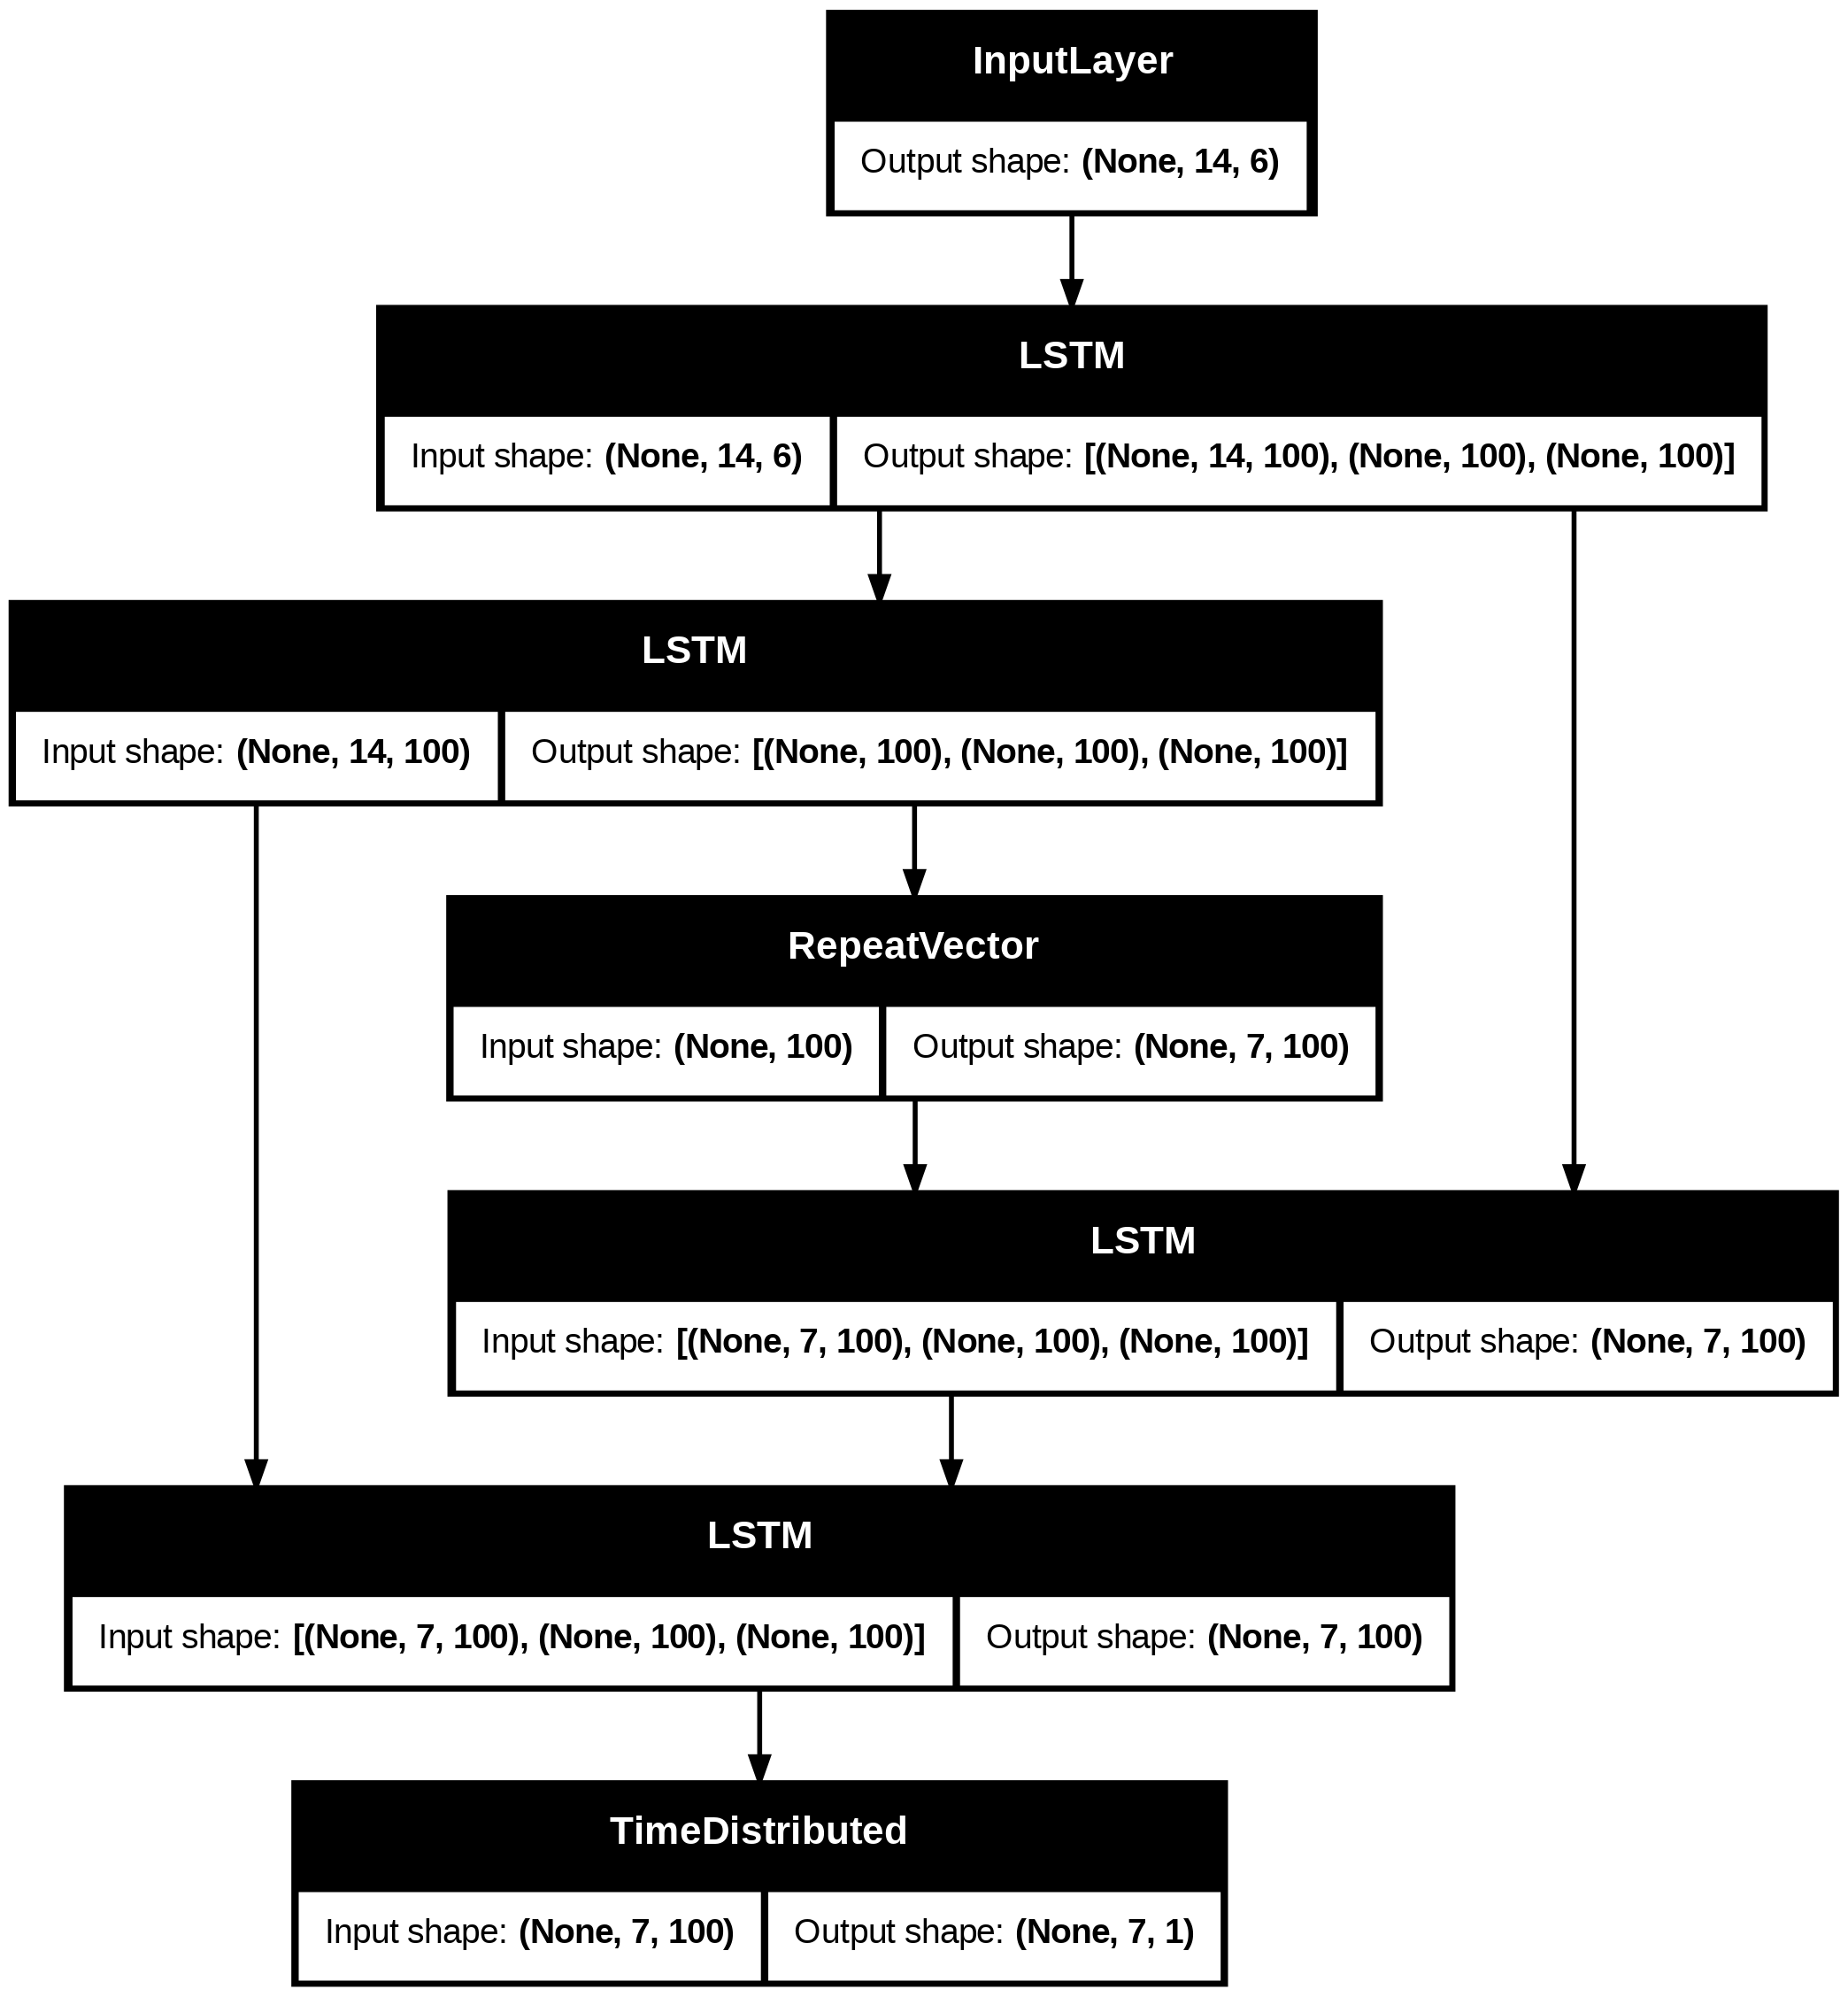

In [ ]:
plot_model(model_e2d2,show_shapes=True)

In [ ]:
# reduce_lrlr = tf.keras.callbacks.LearningRateScheduler(lambda x: 1e-3 * 0.90 ** x)
# #lrlrodelodel_e2d2.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.Huber())
# model_e2d2.compile(optimizer=tf.keras.optimizers.Adam(), loss='mse')
# # history_e2d2=model_e2d2.fit(X_train_dnn_endc,y_train,epochs=25*12,validation_data=(X_test_dnn_endc,y_test),batch_size=32,verbose=1,callbacks=[reduce_lr])
# history_e2d2=model_e2d2.fit(X_train_dnn_endc,y_train,epochs=9,validation_data=(X_test_dnn_endc,y_test),batch_size=batch_size,verbose=1)

In [ ]:
# model_e2d2.save('model_e2d2.h5')  # creates a HDF5 file 'my_model.h5'
# # model_cnn.save('cnn_hourly.h5')  # creates a HDF5 file 'my_model.h5'
# # del model  # deletes the existing model

# # returns a compiled model
# # identical to the previous one
# # model = load_model('cnn_daily.h5')

In [ ]:
history_e2d2 = grid_result.best_estimator_.history

In [ ]:
loss_curve(history_e2d2)

In [ ]:
# predictions_endc = model_e2d2.predict(X_test_dnn_endc)[:,:,0]
predictions_endc = predictions[:,:,0]
metrices_endc = get_performance_metrices(y_test,predictions_endc,'EnDc')
print(metrices_endc)

  model    mae    mse   rmse    mape   mdae
0  EnDc  0.087  0.014  0.119  34.186   0.06
1  EnDc  0.089  0.015  0.122  34.088  0.068
2  EnDc   0.09  0.015  0.123  34.456  0.066
3  EnDc  0.091  0.015  0.123   33.84  0.067
4  EnDc  0.093  0.016  0.126  34.214  0.065
5  EnDc  0.092  0.016  0.125  33.531  0.071
6  EnDc  0.095  0.016  0.128  33.786   0.07


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/pytho

## Conv-LSTM Encoder-Decoder model

In [ ]:
# define model
model_conv_lstm = Sequential()
model_conv_lstm.add(ConvLSTM2D(filters=64, kernel_size=(1,3), activation='relu', input_shape=(n_steps, 1, n_length, n_features)))
# model_conv_lstm.add(ConvLSTM2D(filters=32, kernel_size=(1,2), activation='relu', input_shape=(n_steps, 1, n_length, n_features)))
# model_conv_lstm.add(Dropout(.2))
model_conv_lstm.add(BatchNormalization())
model_conv_lstm.add(Flatten())
model_conv_lstm.add(RepeatVector(n_outputs))
model_conv_lstm.add(LSTM(200, activation='relu', return_sequences=True))
# model_conv_lstm.add(LSTM(100, activation='relu', return_sequences=True))
# model_conv_lstm.add(TimeDistributed(Dense(1000, activation='relu')))
# model_conv_lstm.add(TimeDistributed(Dense(500, activation='relu')))
model_conv_lstm.add(TimeDistributed(Dense(100, activation='relu')))
model_conv_lstm.add(TimeDistributed(Dense(1)))
# model_conv_lstm.add(TimeDistributed(Dense(train_y.shape[1]*train_y.shape[2])))
model_conv_lstm.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv_lstm2d (ConvLSTM2D)             │ (None, 1, 5, 64)            │          54,016 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 1, 5, 64)            │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 320)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_5 (RepeatVector)       │ (None, 7, 320)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_20 (LSTM)                       │ (None, 7, 200)              │         416,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_5 (TimeDistributed) │ (None, 7, 100)              │          20,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_6 (TimeDistributed) │ (None, 7, 1)                │             101 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 491,273 (1.87 MB)

 Trainable params: 491,145 (1.87 MB)

 Non-trainable params: 128 (512.00 B)

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import ConvLSTM2D, BatchNormalization, Flatten, RepeatVector, LSTM, TimeDistributed, Dense
from sklearn.model_selection import GridSearchCV
from sklearn.base import BaseEstimator

class ConvLSTMWrapper(BaseEstimator):
    def __init__(self, conv_filters=64, conv_kernel_size=(1,3), lstm_units=200, dense_units=100,
                 batch_size=32, epochs=50):
        self.conv_filters = conv_filters
        self.conv_kernel_size = conv_kernel_size
        self.lstm_units = lstm_units
        self.dense_units = dense_units
        self.batch_size = batch_size
        self.epochs = epochs
        self.model = None
        self.history = None  # To store training history

    def create_model(self):
        model = Sequential()
        model.add(ConvLSTM2D(filters=self.conv_filters, kernel_size=self.conv_kernel_size,
                             activation='relu', input_shape=(n_steps, 1, n_length, n_features)))
        model.add(BatchNormalization())
        model.add(Flatten())
        model.add(RepeatVector(n_outputs))
        model.add(LSTM(self.lstm_units, activation='relu', return_sequences=True))
        model.add(TimeDistributed(Dense(self.dense_units, activation='relu')))
        model.add(TimeDistributed(Dense(1)))

        model.compile(optimizer='adam', loss='mse')
        return model

    def fit(self, X, y, X_val=None, y_val=None):
        self.model = self.create_model()
        if X_val is not None and y_val is not None:
            # Train with validation data
            self.history = self.model.fit(X, y, batch_size=self.batch_size, epochs=self.epochs, verbose=1,
                                          validation_data=(X_val, y_val))
        else:
            # Train without validation data
            self.history = self.model.fit(X, y, batch_size=self.batch_size, epochs=self.epochs, verbose=1)
        return self

    def predict(self, X):
        return self.model.predict(X)

    def score(self, X, y):
        return -self.model.evaluate(X, y, verbose=1)  # Negative MSE for scoring (higher is better)

# Define the grid search parameters
param_grid = {
    'conv_filters': [32, 64, 128][:2],
    'conv_kernel_size': [(1,2), (1,3), (1,4)][:2],
    'lstm_units': [100, 200, 300][:2],
    'dense_units': [50, 100, 200][:2],
    'batch_size': [32, 64],
    'epochs': [50, 100][:1]
}

param_grid = {'batch_size': [32], 'conv_filters': [64], 'conv_kernel_size': [(1, 3)],
              'dense_units': [100], 'epochs': [50], 'lstm_units': [200]}

# Create the grid search
grid = GridSearchCV(estimator=ConvLSTMWrapper(), param_grid=param_grid, cv=3, n_jobs=1, verbose=2)

# Fit the grid search
grid_result = grid.fit(train_x, train_y,X_val=val_x, y_val=val_y)

# Print the best parameters and score
print("Best parameters: ", grid_result.best_params_)
print("Best score: ", -grid_result.best_score_)  # Convert back to MSE

# Get the best model
best_model = grid_result.best_estimator_.model

# Evaluate the best model on the test set
test_loss = best_model.evaluate(test_x, test_y)
print(f"Test Loss: {test_loss}")

# If you want to make predictions
predictions = best_model.predict(test_x)

# Print model summary
best_model.summary()

Fitting 3 folds for each of 1 candidates, totalling 3 fits
Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - loss: 0.0657 - val_loss: 0.1148
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0183 - val_loss: 0.0931
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0130 - val_loss: 0.0833
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0129 - val_loss: 0.0818
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - loss: 0.0114 - val_loss: 0.0770
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - loss: 0.0102 - val_loss: 0.0763
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - loss: 0.0099 - val_loss: 0.0754
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.0105 - val_loss: 0.0742
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0099 - val_loss: 0.0718
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0088 - val_loss: 0.0663
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0087 - val_loss: 0.0692
Epoc

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv_lstm2d_4 (ConvLSTM2D)           │ (None, 1, 5, 64)            │          54,016 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 1, 5, 64)            │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_8 (Flatten)                  │ (None, 320)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_9 (RepeatVector)       │ (None, 7, 320)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_24 (LSTM)                       │ (None, 7, 200)              │         416,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_13                  │ (None, 7, 100)              │          20,100 │
│ (TimeDistributed)                    │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_14                  │ (None, 7, 1)                │             101 │
│ (TimeDistributed)                    │                             │                 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,473,565 (5.62 MB)

 Trainable params: 491,145 (1.87 MB)

 Non-trainable params: 128 (512.00 B)

 Optimizer params: 982,292 (3.75 MB)

In [ ]:
test_x.shape

(182, 2, 1, 7, 6)

In [ ]:
test_y.shape

(182, 7, 1)

In [ ]:
test_loss = best_model.evaluate(test_x, test_y)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0192


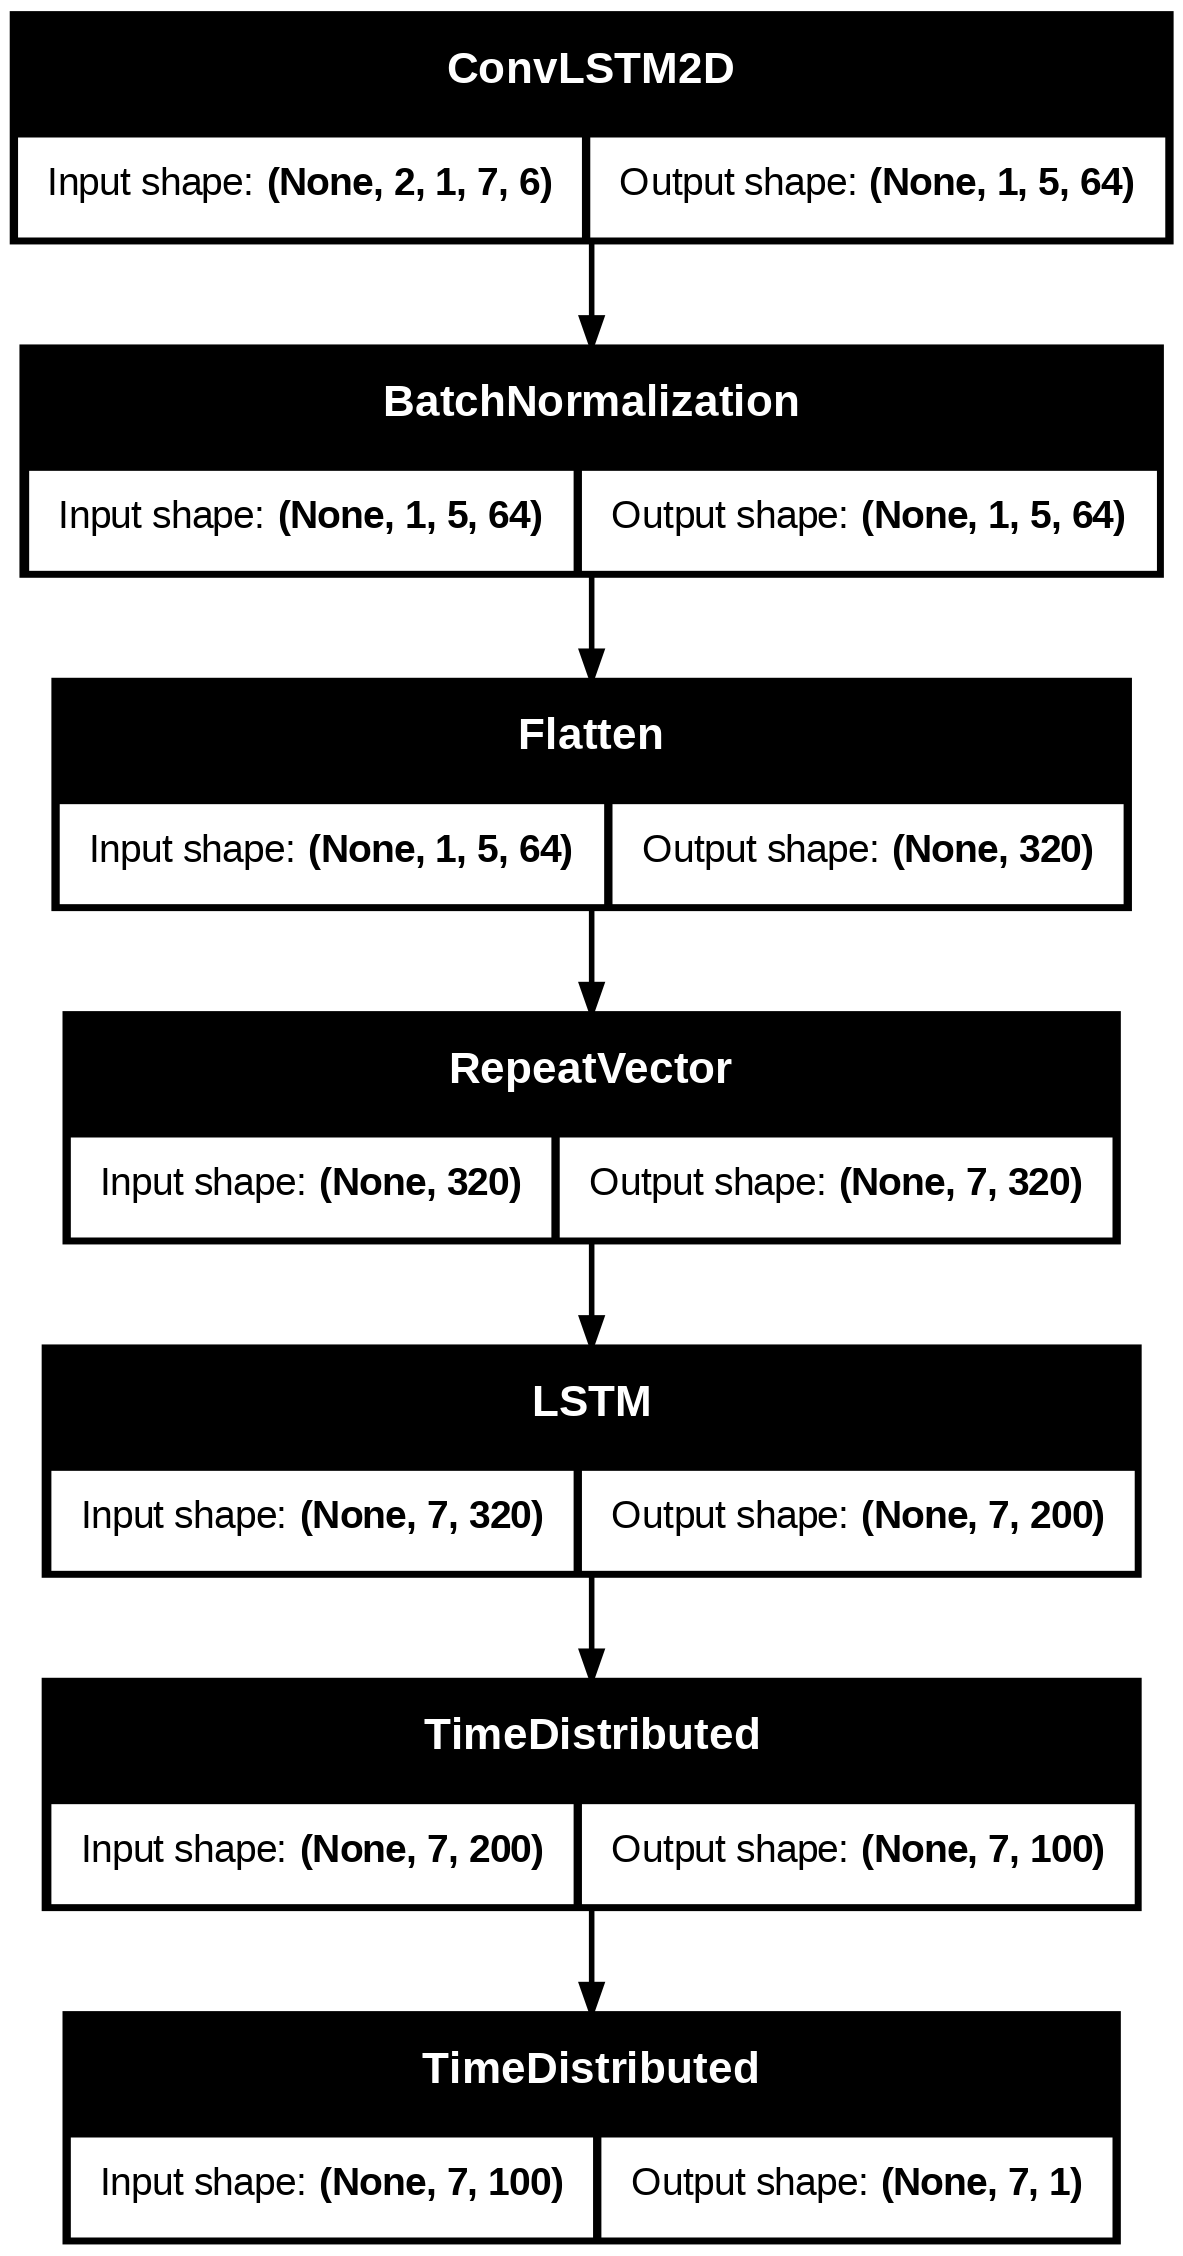

In [ ]:
plot_model(model_conv_lstm,show_shapes=True)

In [ ]:
history_conv_lstm = grid_result.best_estimator_.history

In [ ]:
# verbose, epochs, batch_size = 1, 30*3, 32


# filepath="aq.forecast.weights.best.hdf5"
# # checkpoint = ModelCheckpoint(filepath, monitor='loss', verbose=1, save_best_only=True, mode='min')
# # callbacks_list = [checkpoint]
# callbacks_list = []

# # if os.path.exists(filepath):
# # 	model.load_weights(filepath)

# model_conv_lstm.compile(loss='mse', optimizer='adam')
# # fit network
# history_conv_lstm = model_conv_lstm.fit(train_x, train_y, epochs=epochs, batch_size=batch_size, verbose=verbose,callbacks=callbacks_list,validation_data=(test_x,test_y))

In [ ]:
model_conv_lstm.save('model_conv_lstm.h5')  # creates a HDF5 file 'my_model.h5'
# model_cnn.save('cnn_hourly.h5')  # creates a HDF5 file 'my_model.h5'
# del model  # deletes the existing model

# returns a compiled model
# identical to the previous one
# model = load_model('cnn_daily.h5')

In [ ]:
loss_curve(history_conv_lstm)

In [ ]:
# predictions_conv_lstm = model_conv_lstm.predict(test_x)[:,:,0]
predictions_conv_lstm = predictions[:,:,0]
metrices_conv_lstm = get_performance_metrices(y_test,predictions_conv_lstm,'Conv LSTM')
print(metrices_conv_lstm)

       model    mae    mse   rmse    mape   mdae
0  Conv LSTM  0.068  0.008  0.088  30.689  0.054
1  Conv LSTM  0.083  0.013  0.113  33.879  0.061
2  Conv LSTM  0.092  0.015  0.122  34.842  0.069
3  Conv LSTM  0.097  0.017  0.132  33.707  0.078
4  Conv LSTM  0.102  0.019  0.137  34.604  0.073
5  Conv LSTM  0.109  0.022  0.147  34.486  0.086
6  Conv LSTM  0.109  0.023   0.15  34.419   0.08


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning:

'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.

/usr/local/lib/pytho

## All in one Evaluate

In [ ]:
from plotly.subplots import make_subplots

def compare_loss_curves(histories, titles=None):
    """
    Create side-by-side loss curves for multiple model histories in black and white.

    Parameters:
    histories (list): List of keras history objects
    titles (list): List of titles for each subplot. If None, uses default titles

    Returns:
    None: Displays the plot
    """
    # Default titles if none provided
    if titles is None:
        titles = [f'Model {i+1}' for i in range(len(histories))]

    # Create subplots
    fig = make_subplots(
        rows=1,
        cols=len(histories),
        subplot_titles=titles,
        shared_yaxes=True
    )

    # Line styles for different curves
    line_styles = {
        'loss': dict(color='black', width=2),
        'val_loss': dict(color='black', width=2, dash='dash')
    }

    # Add traces for each history
    for i, history in enumerate(histories):
        # Convert history to dataframe
        loss_df = pd.DataFrame({
            'loss': history.history['loss'],
            'val_loss': history.history['val_loss']
        })

        # Add training loss
        fig.add_trace(
            go.Scatter(
                x=loss_df.index,
                y=loss_df['loss'],
                name='Training Loss',
                line=line_styles['loss'],
                showlegend=(i == 0)  # Show legend only for first subplot
            ),
            row=1,
            col=i+1
        )

        # Add validation loss
        fig.add_trace(
            go.Scatter(
                x=loss_df.index,
                y=loss_df['val_loss'],
                name='Validation Loss',
                line=line_styles['val_loss'],
                showlegend=(i == 0)  # Show legend only for first subplot
            ),
            row=1,
            col=i+1
        )

    # Update layout
    fig.update_layout(
        height=400,
        width=1200,
        template="plotly_white",
        showlegend=True,
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.11,
            xanchor="right",
            x=1
        ),
        font=dict(size=15)
    )

    # Update axes
    fig.update_xaxes(title_text="Epoch")
    fig.update_yaxes(title_text="Loss")

    # Show the plot
    fig.show()


# Assuming you have three history objects: history1, history2, history3
histories = [history_cnn, history_e2d2, history_conv_lstm]
titles = ['CNN', 'Encoder Decoder', 'Conv LSTM']

compare_loss_curves(histories, titles)

In [ ]:
dl_models_metrices_all

[  model    mae    mse   rmse    mape   mdae
 0   CNN   0.08  0.013  0.113  41.004  0.058
 1   CNN  0.085  0.015  0.121  36.475   0.06
 2   CNN  0.089  0.015  0.124  38.224  0.054
 3   CNN  0.091  0.016  0.128  42.053  0.061
 4   CNN  0.095  0.017   0.13  39.078  0.064
 5   CNN  0.095  0.017  0.131  39.485  0.068
 6   CNN  0.099  0.018  0.135  40.279  0.068,
   model    mae    mse   rmse    mape   mdae
 0  EnDc  0.087  0.014  0.119  34.186   0.06
 1  EnDc  0.089  0.015  0.122  34.088  0.068
 2  EnDc   0.09  0.015  0.123  34.456  0.066
 3  EnDc  0.091  0.015  0.123   33.84  0.067
 4  EnDc  0.093  0.016  0.126  34.214  0.065
 5  EnDc  0.092  0.016  0.125  33.531  0.071
 6  EnDc  0.095  0.016  0.128  33.786   0.07,
        model    mae    mse   rmse    mape   mdae
 0  Conv LSTM  0.068  0.008  0.088  30.689  0.054
 1  Conv LSTM  0.083  0.013  0.113  33.879  0.061
 2  Conv LSTM  0.092  0.015  0.122  34.842  0.069
 3  Conv LSTM  0.097  0.017  0.132  33.707  0.078
 4  Conv LSTM  0.102  0.019 

In [ ]:
!zip dl_models.zip model_cnn.h5 model_e2d2.h5 model_conv_lstm.h5

	zip warning: name not matched: model_e2d2.h5
  adding: model_cnn.h5 (deflated 38%)
  adding: model_conv_lstm.h5 (deflated 10%)


In [ ]:
models_metrices_all = models_metrices_list.copy()
dl_models_metrices_all = [metrices_cnn,metrices_endc,metrices_conv_lstm]
models_metrices_all.extend(dl_models_metrices_all)
models_metrices_all

[              model    mae    mse   rmse    mape   mdae
 0  LinearRegression  0.059  0.006  0.079   34.29  0.044
 1  LinearRegression  0.072   0.01  0.101   34.05  0.049
 2  LinearRegression  0.084  0.012  0.111    35.3   0.06
 3  LinearRegression  0.086  0.014  0.118  33.192  0.069
 4  LinearRegression  0.093  0.015  0.124  35.154  0.067
 5  LinearRegression  0.093  0.016  0.125  32.995  0.072
 6  LinearRegression  0.097  0.016  0.127  33.446  0.071,
            model    mae    mse   rmse    mape   mdae
 0  BayesianRidge  0.058  0.006  0.077  34.301  0.042
 1  BayesianRidge  0.075  0.011  0.105  34.898  0.052
 2  BayesianRidge  0.086  0.013  0.114  36.078   0.06
 3  BayesianRidge  0.088  0.014   0.12  34.798  0.065
 4  BayesianRidge  0.093  0.015  0.123  35.354  0.071
 5  BayesianRidge  0.093  0.016  0.125  34.205  0.072
 6  BayesianRidge  0.095  0.016  0.125  34.462  0.077,
                  model    mae    mse   rmse    mape   mdae
 0  KNeighborsRegressor  0.086  0.014  0.117   40.

In [ ]:
models_metrices_concatanated = pd.concat(models_metrices_all)
models_metrices_concatanated.index.name = 'time_offset'
models_metrices_concatanated_indexed = models_metrices_concatanated.set_index([models_metrices_concatanated.index,'model'])
models_metrices_concatanated_indexed

,,mae,mse,rmse,mape,mdae
time_offset,model,,,,,
0,LinearRegression,0.059,0.006,0.079,34.29,0.044
1,LinearRegression,0.072,0.01,0.101,34.05,0.049
2,LinearRegression,0.084,0.012,0.111,35.3,0.06
3,LinearRegression,0.086,0.014,0.118,33.192,0.069
4,LinearRegression,0.093,0.015,0.124,35.154,0.067
...,...,...,...,...,...,...
2,Conv LSTM,0.092,0.015,0.122,34.842,0.069
3,Conv LSTM,0.097,0.017,0.132,33.707,0.078
4,Conv LSTM,0.102,0.019,0.137,34.604,0.073


In [ ]:
models_metrices_concatanated_indexed

,,mae,mse,rmse,mape,mdae
time_offset,model,,,,,
0,LinearRegression,0.059,0.006,0.079,34.29,0.044
1,LinearRegression,0.072,0.01,0.101,34.05,0.049
2,LinearRegression,0.084,0.012,0.111,35.3,0.06
3,LinearRegression,0.086,0.014,0.118,33.192,0.069
4,LinearRegression,0.093,0.015,0.124,35.154,0.067
...,...,...,...,...,...,...
2,Conv LSTM,0.092,0.015,0.122,34.842,0.069
3,Conv LSTM,0.097,0.017,0.132,33.707,0.078
4,Conv LSTM,0.102,0.019,0.137,34.604,0.073


In [ ]:
import plotly.graph_objects as go

models_color_all = ['#C4C4C4', '#FF69B4', '#848484', '#FF69B4', '#FF6EB4', '#B46FFF', '#00CCFF', '#44C5FF', '#64C0FF']


models_name_all = ['LinearRegression', 'BayesianRidge', 'KNeighborsRegressor',
       'DecisionTreeRegressor', 'LGBMRegressor', 'MLPRegressor', 'CNN', 'EnDc',
       'Conv LSTM']

models_color_series_all = pd.Series(index=models_name_all,name='color',data=models_color_all)
# models_color_series_all

models_color_series_all.iloc[[1,4,5,6,7,8]] = ['#E0E5E5', '#D1D0CE', '#A9A9A9', '#736F6E', '#625D5D', '#3A3B3C']


for matrix in models_metrices_concatanated_indexed:
  # print(matrix)
  df = models_metrices_concatanated_indexed[matrix].unstack()
  df_all = df.iloc[:,[7,0,5,3,6,8,1,4,2]]
  df = df.iloc[:,[0,6,8,1,4,2]]
  # print(matrix)
  # df_all.T.to_csv(f'{matrix}.csv')

  # continue
  # df.columns = models_name
  # print(df)
  fig = go.Figure()

  for alg in df:
    # print(alg)
    fig.add_trace(go.Bar(
        x=df.index+1,
        y=df[alg],
        name=alg,
        marker_color=models_color_series_all[alg],
        marker=dict(
        # color=models_color_all,
        line=dict(
            color='rgba(0,0,0,0.5)',
            width=1.5),
        opacity=0.8
        )
      )
    )

  # Here we modify the tickangle of the xaxis, resulting in rotated labels.
  fig.update_layout(barmode='group', xaxis_tickangle=-45, title=matrix,font_size=18,xaxis_title='days',yaxis_title=f'{matrix} score',
                    legend=dict(orientation="h",y=1,yanchor="bottom"), template = 'plotly_white')
                    #legend=dict(orientation="h",yanchor="bottom",y=1.02,xanchor="right",x=1))
  fig.show()
  # continue

In [ ]:
!zip results.zip mae.csv mse.csv rmse.csv mape.csv mdae.csv

	zip warning: name not matched: mae.csv
	zip warning: name not matched: mse.csv
	zip warning: name not matched: rmse.csv
	zip warning: name not matched: mape.csv
	zip warning: name not matched: mdae.csv

zip error: Nothing to do! (results.zip)


In [ ]:
df.columns

Index(['BayesianRidge', 'LGBMRegressor', 'MLPRegressor', 'CNN', 'EnDc',
       'Conv LSTM'],
      dtype='object', name='model')

In [ ]:
models_metrices_concatanated_indexed.to_csv('models_metrices_concatanated_indexed.csv')

In [ ]:
models_name_some = [ 'BayesianRidge', 'LGBMRegressor', 'MLPRegressor', 'CNN', 'EnDc', 'Conv LSTM']

models_metrices_concatanated_indexed_some = models_metrices_concatanated_indexed[models_metrices_concatanated_indexed.index.get_level_values(1).str.contains('|'.join(models_name_some), case=False)][['rmse','mape','mdae']]
models_metrices_concatanated_indexed_some

,,rmse,mape,mdae
time_offset,model,,,
0,BayesianRidge,0.077,34.301,0.042
1,BayesianRidge,0.105,34.898,0.052
2,BayesianRidge,0.114,36.078,0.06
3,BayesianRidge,0.12,34.798,0.065
4,BayesianRidge,0.123,35.354,0.071
5,BayesianRidge,0.125,34.205,0.072
6,BayesianRidge,0.125,34.462,0.077
0,LGBMRegressor,0.086,35.416,0.042
1,LGBMRegressor,0.119,37.992,0.055


In [ ]:
[models_metrices_concatanated_indexed_some[matrix].unstack() for matrix in models_metrices_concatanated_indexed_some][2].to_latex(float_format=lambda x: '%.3f' % x)

'\\begin{tabular}{lllllll}\n\\toprule\nmodel & BayesianRidge & LGBMRegressor & MLPRegressor & CNN & EnDc & Conv LSTM \\\\\ntime_offset &  &  &  &  &  &  \\\\\n\\midrule\n0 & 0.042 & 0.042 & 0.059 & 0.058 & 0.060 & 0.054 \\\\\n1 & 0.052 & 0.055 & 0.072 & 0.060 & 0.068 & 0.061 \\\\\n2 & 0.060 & 0.062 & 0.067 & 0.054 & 0.066 & 0.069 \\\\\n3 & 0.065 & 0.067 & 0.064 & 0.061 & 0.067 & 0.078 \\\\\n4 & 0.071 & 0.063 & 0.073 & 0.064 & 0.065 & 0.073 \\\\\n5 & 0.072 & 0.066 & 0.072 & 0.068 & 0.071 & 0.086 \\\\\n6 & 0.077 & 0.061 & 0.077 & 0.068 & 0.070 & 0.080 \\\\\n\\bottomrule\n\\end{tabular}\n'

## Load Saved Model Information

In [ ]:
!unzip dl_models.zip
!unzip results.zip

In [ ]:
model_cnn = load_model('model_cnn.h5')
model_e2d2 = load_model('model_e2d2.h5')
model_conv_lstm = load_model('model_conv_lstm.h5')

## Dummy DL (Conv1D) model

In [ ]:
# split a multivariate sequence into samples
def split_sequences(sequences, n_steps_in, n_steps_out):
	X, y = list(), list()
	for i in range(len(sequences)):
		# find the end of this pattern
		end_ix = i + n_steps_in
		out_end_ix = end_ix + n_steps_out
		# check if we are beyond the dataset
		if out_end_ix > len(sequences):
			break
		# gather input and output parts of the pattern
		seq_x, seq_y = sequences[i:end_ix, :], sequences[end_ix:out_end_ix, :]
		X.append(seq_x)
		y.append(seq_y)
	return array(X), array(y)

# define input sequence
in_seq1 = array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110])
in_seq2 = array([15, 25, 35, 45, 55, 65, 75, 85, 95, 105, 115])
out_seq = array([in_seq1[i]+in_seq2[i] for i in range(len(in_seq1))])
# convert to [rows, columns] structure
in_seq1 = in_seq1.reshape((len(in_seq1), 1))
in_seq2 = in_seq2.reshape((len(in_seq2), 1))
out_seq = out_seq.reshape((len(out_seq), 1))
# horizontally stack columns
dataset = hstack((in_seq1, in_seq2, out_seq))
# choose a number of time steps
n_steps_in, n_steps_out = 3, 2
# convert into input/output
X, y = split_sequences(dataset, n_steps_in, n_steps_out)
# flatten output
n_output = y.shape[1] * y.shape[2]
# y = y.reshape((y.shape[0], n_output))
# the dataset knows the number of features, e.g. 2
n_features = X.shape[2]


In [ ]:
X.shape, y.shape

In [ ]:
# define model
model = Sequential()
model.add(Conv1D(filters=64, kernel_size=2, activation='relu', input_shape=(n_steps_in, n_features)))
model.add(MaxPooling1D(pool_size=2))
model.add(Flatten())
model.add(Dense(50, activation='relu'))
model.add(Dense(n_output))
model.compile(optimizer='adam', loss='mse')
# fit model
model.fit(X, y, epochs=70, verbose=1)
# demonstrate prediction
x_input = array([[60, 65, 125], [70, 75, 145], [80, 85, 165]])
x_input = x_input.reshape((1, n_steps_in, n_features))
yhat = model.predict(x_input, verbose=0)
print(yhat)

# SHAP Analysis

## Installation

In [ ]:
!pip install shap

In [ ]:
# !pip install --upgrade jax

In [ ]:
!pip uninstall shap
!pip uninstall numba
!pip install numba
# !pip install shap==0.57
!pip install shap

In [ ]:
!pip uninstall numpy
!pip uninstall numba
!python3 -m pip install numba

In [ ]:
!python --version

Python 3.9.16


In [ ]:
!pip show shap

Name: shap
Version: 0.41.0
Summary: A unified approach to explain the output of any machine learning model.
Home-page: http://github.com/slundberg/shap
Author: Scott Lundberg
Author-email: slund1@cs.washington.edu
License: MIT
Location: /usr/local/lib/python3.9/dist-packages
Requires: cloudpickle, numba, numpy, packaging, pandas, scikit-learn, scipy, slicer, tqdm
Required-by: 


## ML

In [ ]:
import shap
shap.initjs()

In [ ]:
y_train.shape

(711, 7)

In [ ]:
X_train_sample = X_train.sample(71)
X_train_sample.shape

(71, 84)

### Tree model

In [ ]:
model = LGBMRegressor()
model.fit(X_train, y_train.iloc[:,0])
# shap_values = shap.TreeExplainer(model).shap_values(X_train)

LGBMRegressor()

In [ ]:
explainer = shap.Explainer(model)
shap_values = explainer(X_train)
# shap_interaction = explainer.shap_interaction_values(X)

In [ ]:
shap_values.shape,type(shap_values)

((711, 84), shap._explanation.Explanation)

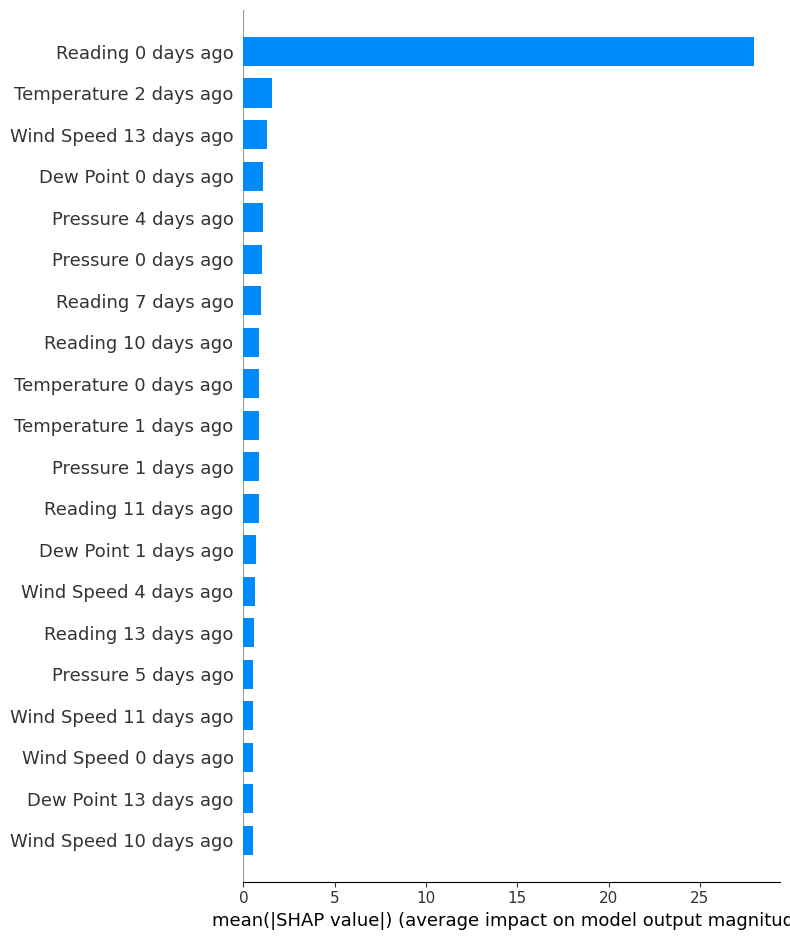

In [ ]:
shap.summary_plot(shap_values, X_train, plot_type="bar")

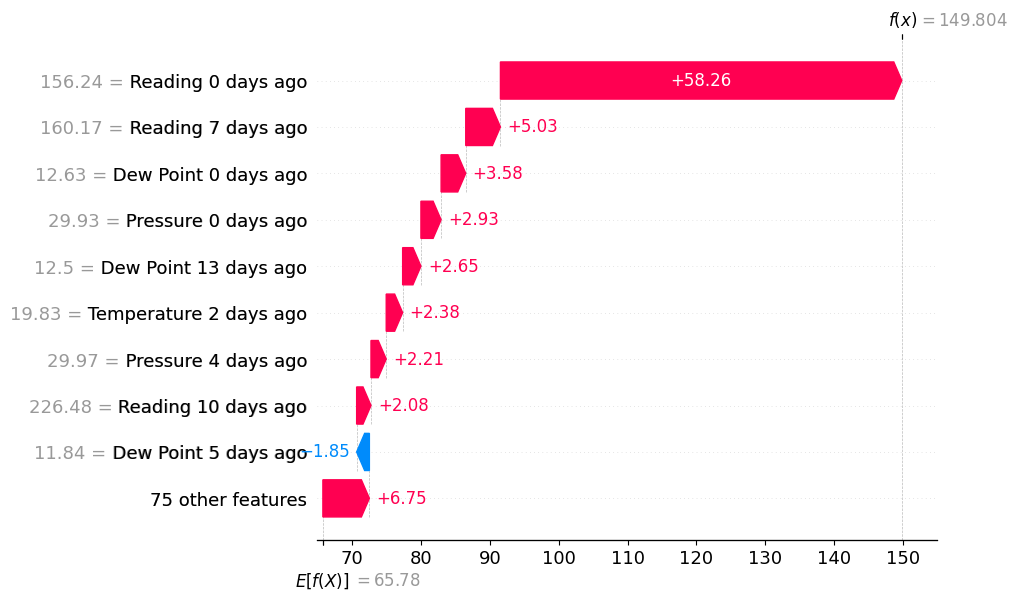

In [ ]:
shap.plots.waterfall(shap_values[0])
# shap.plots.waterfall(shap_values[90])
# shap.plots.waterfall(shap_values[180])
# shap.plots.waterfall(shap_values[270])
# shap.plots.waterfall(shap_values[360])

In [ ]:
shap.plots.force(shap_values[0])

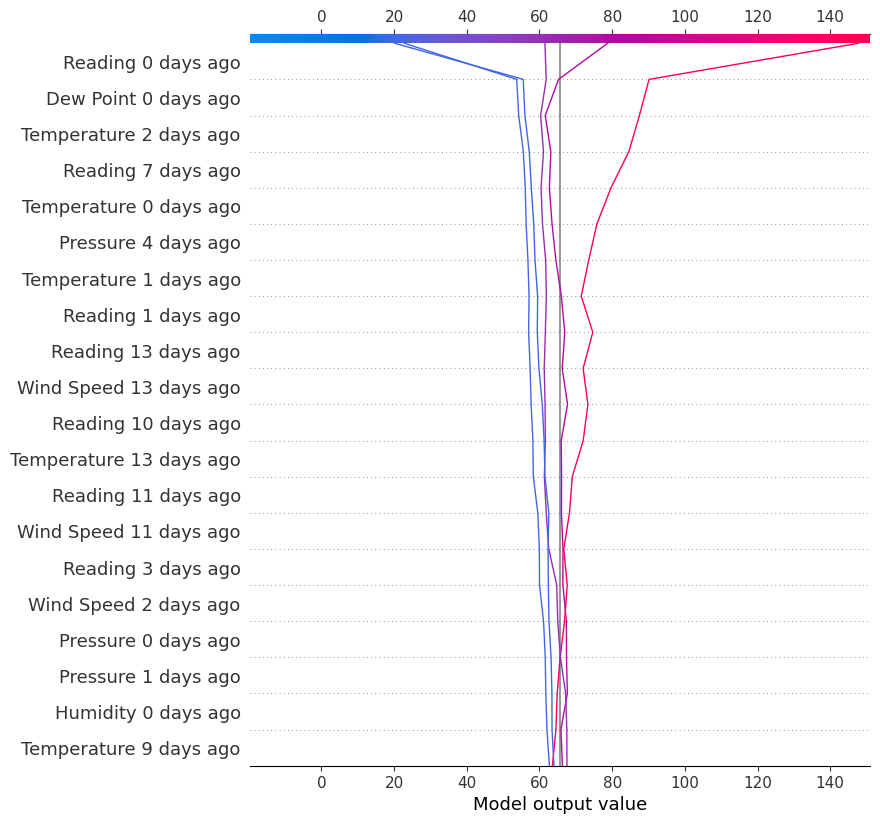

In [ ]:
# Get expected value and shap values array
expected_value = explainer.expected_value
shap_array = explainer.shap_values(X_train_sample)

#Descion plot for first 10 observations
shap.decision_plot(expected_value, shap_array[0:10],feature_names=list(X.columns))

In [ ]:
shap.plots.force(shap_values[0:100])

Exception: ignored

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


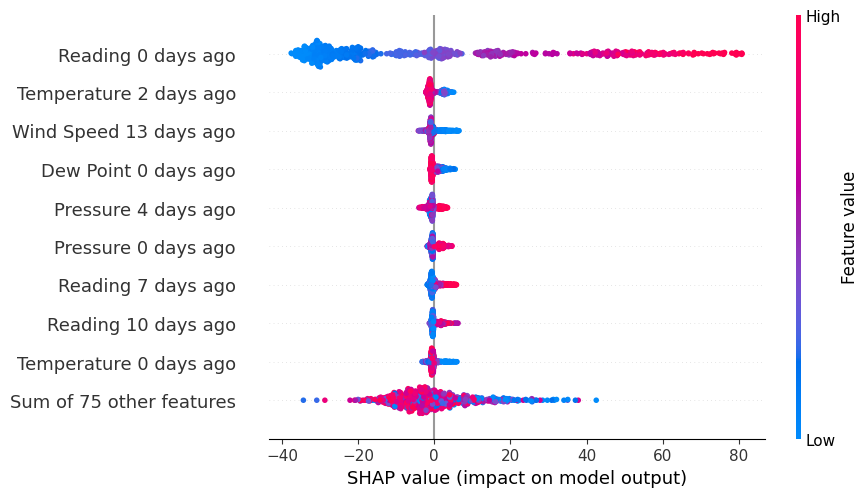

In [ ]:
shap.plots.beeswarm(shap_values)

In [ ]:
shap_values

.values =
array([[ 5.82556701e+01, -1.62253931e+00,  3.57601727e+00, ...,
        -4.61333184e-02,  1.63402935e+00,  1.41704071e+00],
       [ 5.62763463e+01,  2.70577828e+00,  2.63001671e+00, ...,
        -3.23585225e-01, -5.57672143e-01,  1.27241675e+00],
       [ 6.01975994e+01,  3.09242514e+00,  2.15982980e+00, ...,
        -6.48985445e-02, -5.91888137e-01,  1.08621470e+00],
       ...,
       [ 8.00678252e+01,  4.44928027e+00,  2.29257387e+00, ...,
        -5.30527949e-01,  2.10137948e+00, -3.46502078e-01],
       [ 7.33595188e+01,  4.59584123e+00,  1.43107785e+00, ...,
         1.40239334e-01, -4.15135580e-01, -1.11679876e+00],
       [ 5.61475492e+01, -1.68961897e+00,  1.61725574e+00, ...,
         4.12306801e-01, -1.90237637e+00, -1.31402253e+00]])

.base_values =
array([65.78001395, 65.78001395, 65.78001395, 65.78001395, 65.78001395,
       65.78001395, 65.78001395, 65.78001395, 65.78001395, 65.78001395,
       65.78001395, 65.78001395, 65.78001395, 65.78001395, 65.78001395,
 

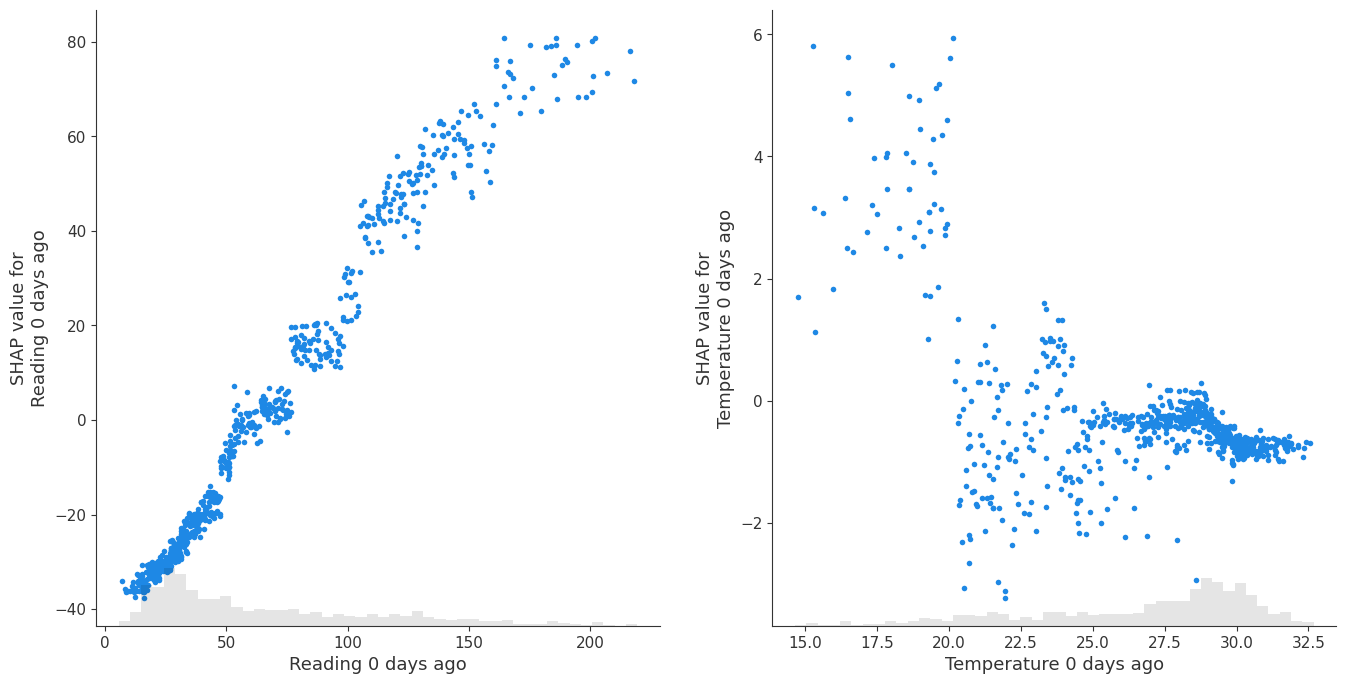

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2,figsize=(16,8))

#SHAP scatter plots
shap.plots.scatter(shap_values[:,"Reading 0 days ago"],ax=ax[0],show=False) #color=shap_values
shap.plots.scatter(shap_values[:,"Temperature 0 days ago"],ax=ax[1])

### Linear Models

In [ ]:
model_lr = LinearRegression()

model_lr.fit(X_train, y_train)

predictions = model_lr.predict(X_train)
predictions.shape

(711, 7)

In [ ]:
model_mlp = MultiOutputRegressor(MLPRegressor(hidden_layer_sizes=(300),max_iter=10,learning_rate='adaptive'))
model_mlp.fit(X_train, y_train)

# model = MLPRegressor(hidden_layer_sizes=(300),max_iter=10,learning_rate='adaptive')
# model.fit(X_train, y_train.iloc[:,0])

Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.


MultiOutputRegressor(estimator=MLPRegressor(hidden_layer_sizes=300,
                                            learning_rate='adaptive',
                                            max_iter=10))

In [ ]:
explainer = shap.KernelExplainer(model.predict, X_train_sample)

# Explain predictions on the first 10 samples
# shap_values = explainer.shap_values(X_train_sample[:3])
shap_values_mlp = explainer.shap_values(X_train_sample)

X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names


  0%|          | 0/71 [00:00<?, ?it/s]

X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with feature names
X does not have valid feature names, but MLPRegressor was fitted with featur

KeyboardInterrupt: ignored

In [ ]:
np.array(shap_values_mlp).shape,type(shap_values_mlp[0])

((7, 71, 84), numpy.ndarray)

In [ ]:
shap_values_mlp[0].shape

(71, 84)

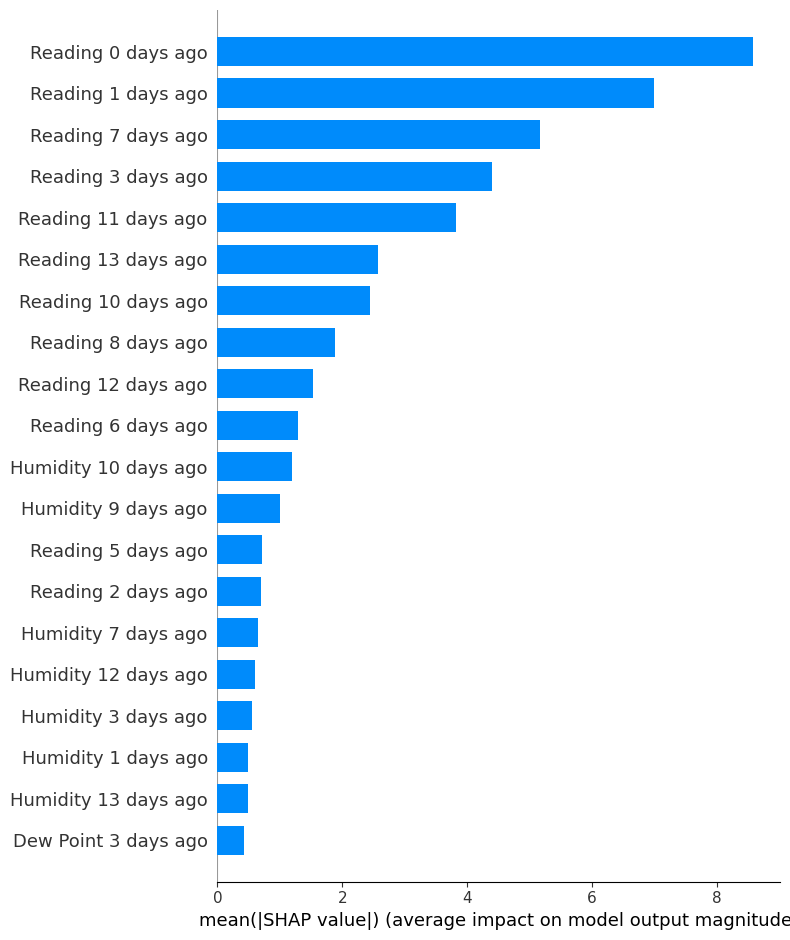

In [ ]:
shap.summary_plot(shap_values_mlp[0], plot_type = 'bar', feature_names = X_train.columns)

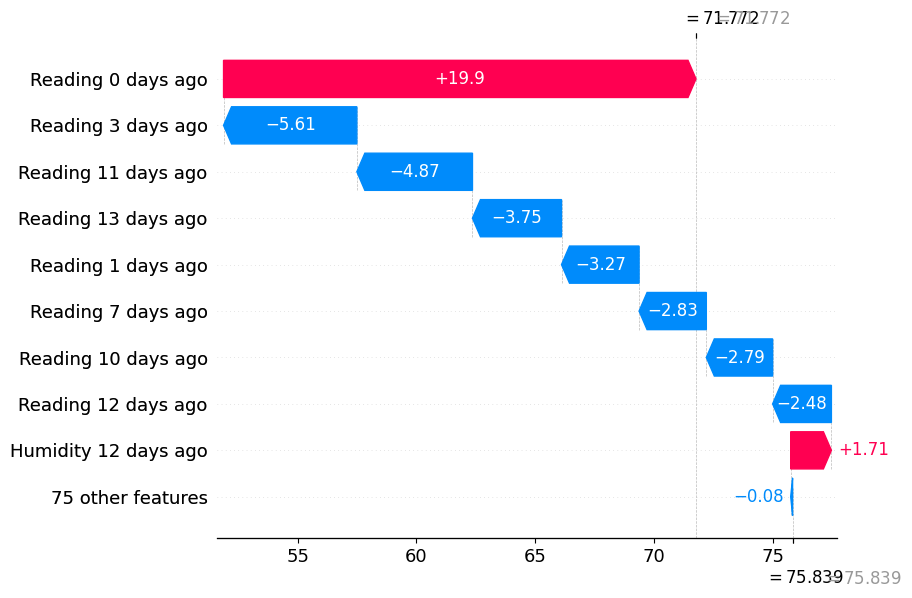

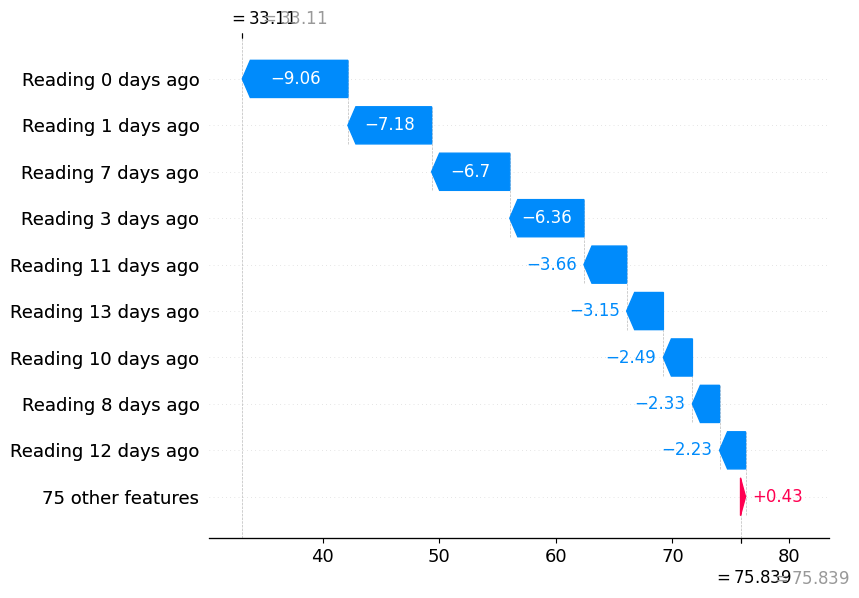

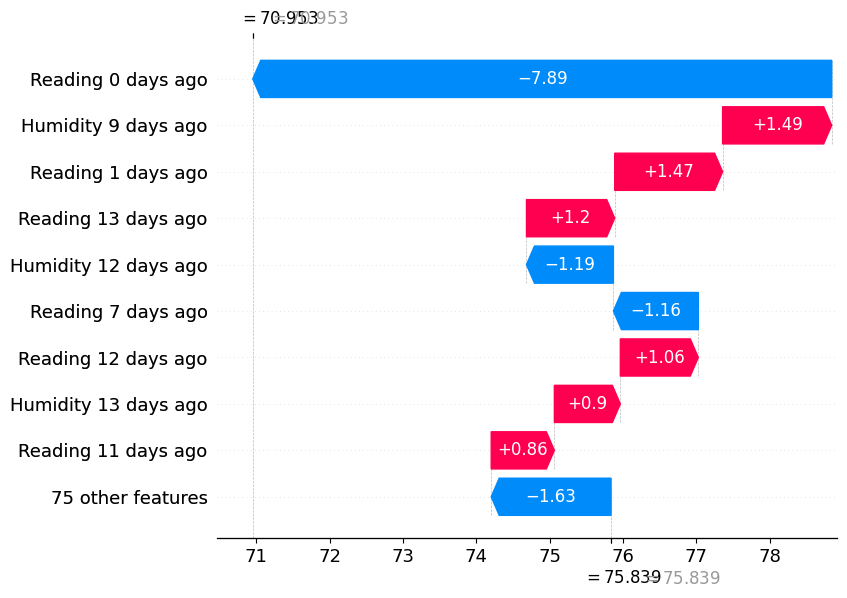

In [ ]:
shap.plots._waterfall.waterfall_legacy(explainer.expected_value[0], shap_values_mlp[0][0], feature_names = X_train.columns)
shap.plots._waterfall.waterfall_legacy(explainer.expected_value[0], shap_values_mlp[0][1], feature_names = X_train.columns)
shap.plots._waterfall.waterfall_legacy(explainer.expected_value[0], shap_values_mlp[0][2], feature_names = X_train.columns)

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


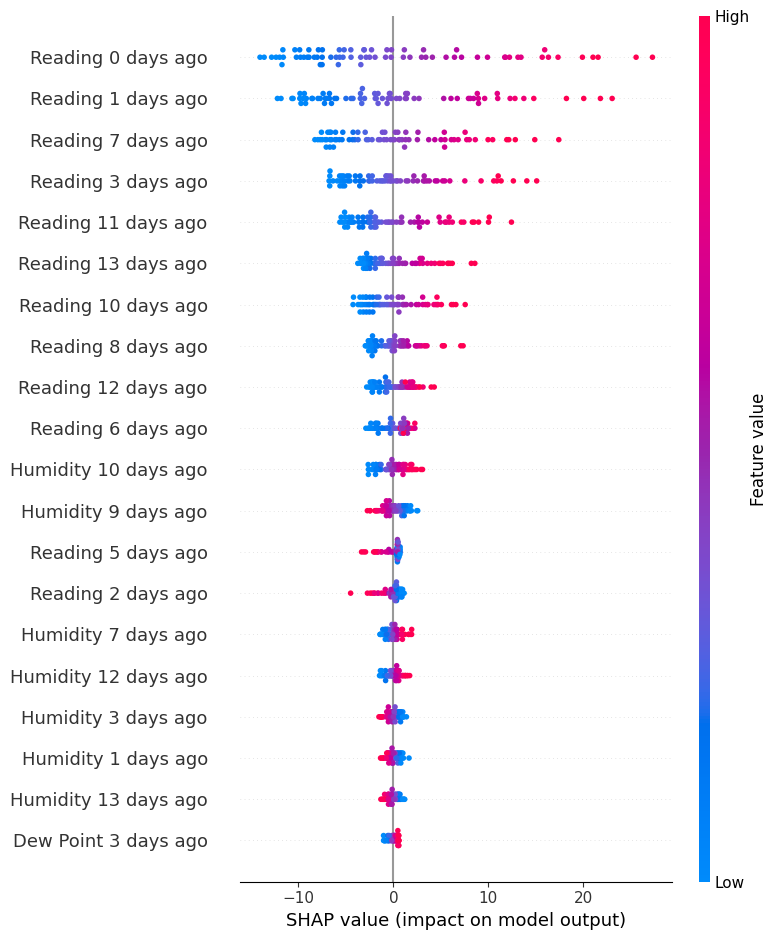

In [ ]:
shap.summary_plot(shap_values = shap_values_mlp[0],features = X_train_sample)

In [ ]:
explanation = shap.Explanation(values=shap_values_mlp[0], base_values=model.predict(X_train_sample)[:,0], data=X_train_sample)
explanation.shape

(71, 84)

In [ ]:
shap_values_mlp[0].shape

(71, 84)

In [ ]:
model.predict(X_train_sample).shape

(71, 7)

In [ ]:
explanation.shape

(71, 84)

TypeError: ignored

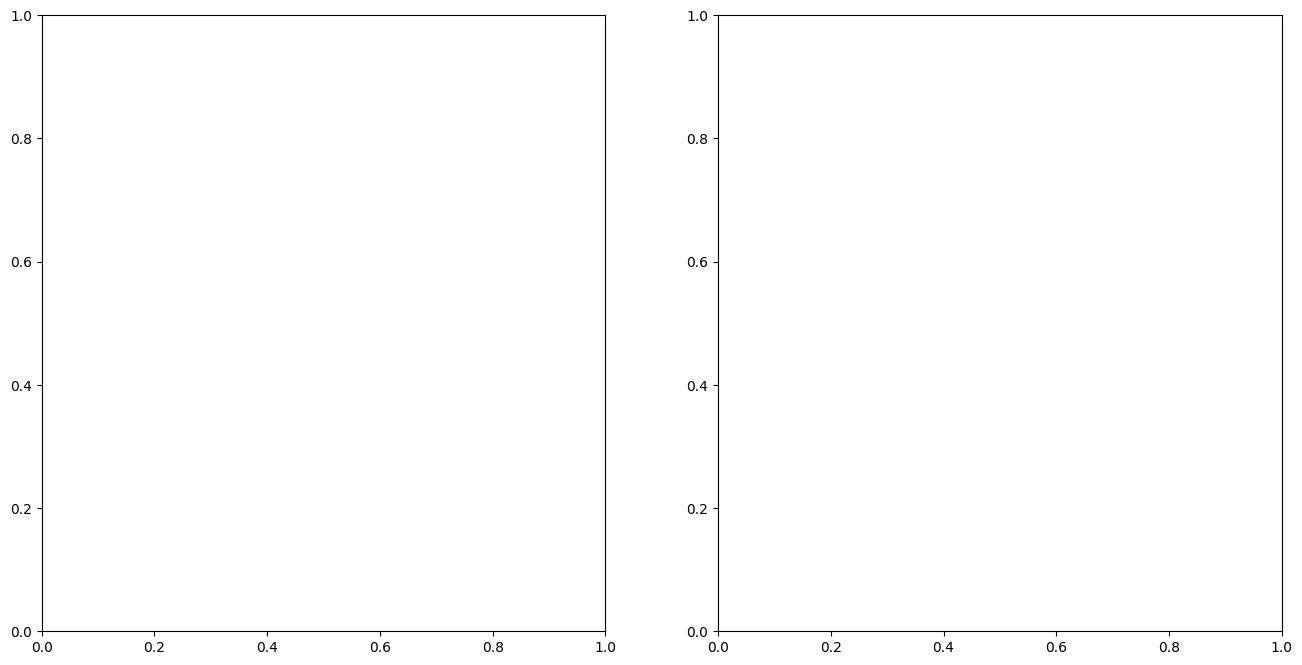

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2,figsize=(16,8))

#SHAP scatter plots
shap.plots.scatter(explanation[:,"Reading 0 days ago"],ax=ax[0],show=False)
shap.plots.scatter(shap_values[:,"Temperature 0 days ago"],ax=ax[1])

## DL

In [ ]:
np.random.choice(X_train.shape[0], 100, replace=False)

array([175, 140, 482, 100, 468,  37, 637, 270, 433, 223, 390, 596, 151,
       289, 567, 564,  60, 301, 688, 597, 589, 229, 377, 519,  55, 356,
       488, 275, 188, 147, 439, 190, 292, 470, 337, 542, 307, 478, 616,
       193, 532,  53, 549, 217, 398, 360, 156, 362, 575, 274, 252, 228,
       710, 641, 563, 541, 503, 372, 665, 146, 673, 213,  83, 645, 201,
       501, 546,  11, 116, 272,  38,  85, 568, 483, 230, 334, 316, 452,
         6, 278,   1, 500, 412, 690, 580, 464, 194, 413, 533,  32,  19,
       127, 253, 182,  16, 324, 129, 451, 610,  68])

In [ ]:
X_test.shape

(711, 6, 14)

In [ ]:
y_test.columns

Index(['Reading 1 day after', 'Reading 2 day after', 'Reading 3 day after',
       'Reading 4 day after', 'Reading 5 day after', 'Reading 6 day after',
       'Reading 7 day after'],
      dtype='object')

In [ ]:
background = X_train_dnn[np.random.choice(X_train_dnn.shape[0], 5, replace=False)]
# DeepExplainer to explain predictions of the model
explainer = shap.DeepExplainer(model_cnn, X_train_dnn)
# compute shap values
shap_values_dnn = explainer.shap_values(X_train_dnn)

Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
`tf.keras.backend.set_learning_phase` is deprecated and will be removed after 2020-10-11. To update it, simply pass a True/False value to the `training` argument of the `__call__` method of your layer or model.


In [ ]:
len(shap_values_dnn),shap_values_dnn[0].shape,np.array(shap_values_dnn).shape, type(shap_values_dnn),type(shap_values_dnn[0])

(7, (711, 6, 14), (7, 711, 6, 14), list, numpy.ndarray)

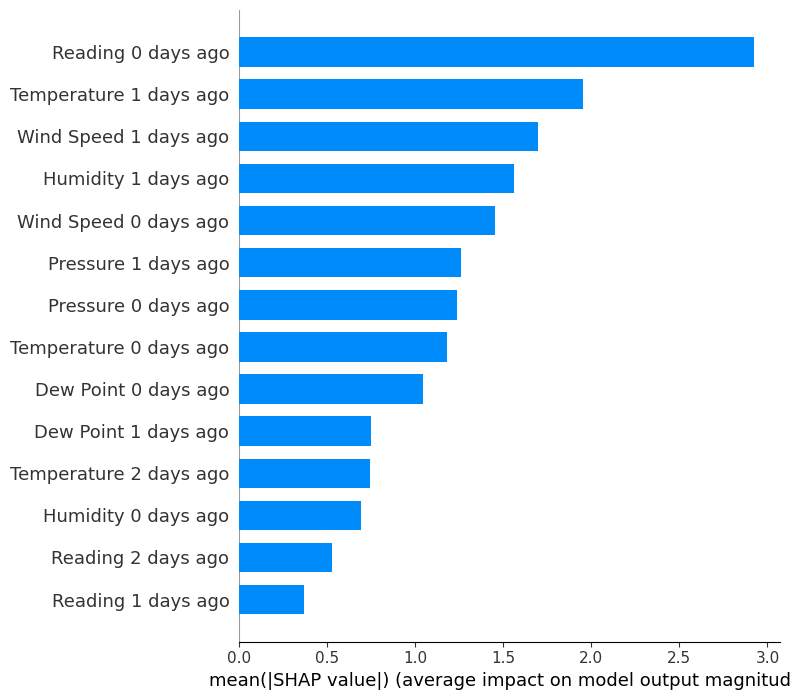

In [ ]:
shap.summary_plot(shap_values_dnn[6][0], plot_type = 'bar', feature_names = X_train.columns)

In [ ]:
explainer.expected_value.numpy()

array([68.48454 , 68.98649 , 68.527435, 69.78082 , 69.119644, 71.704445,
       68.11688 ], dtype=float32)

In [ ]:
shap_values_dnn[0][90].shape

(6, 14)

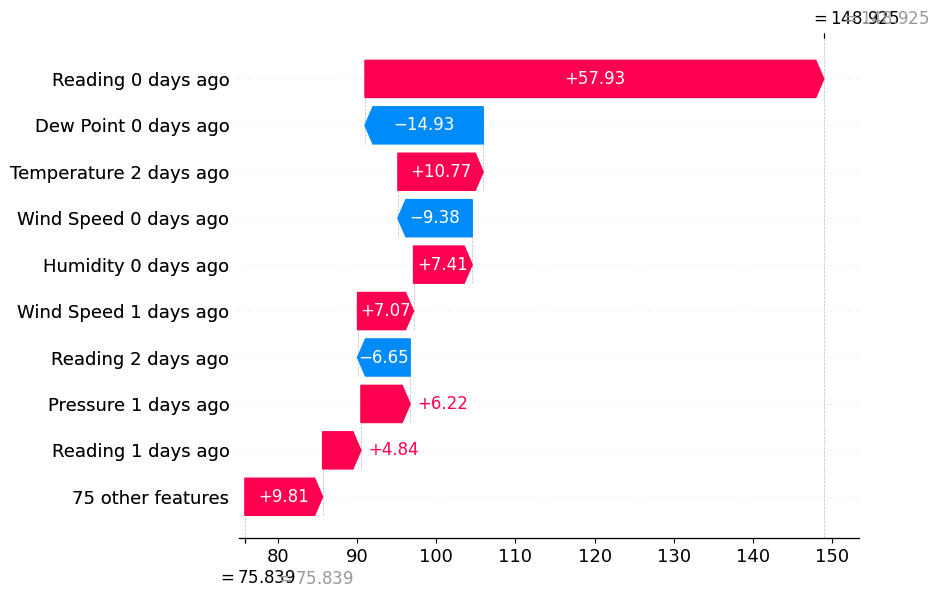

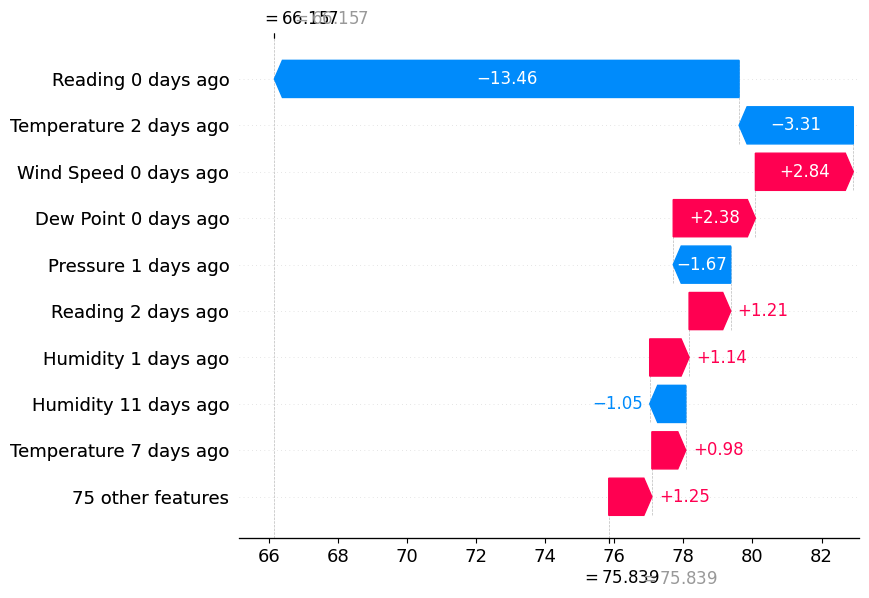

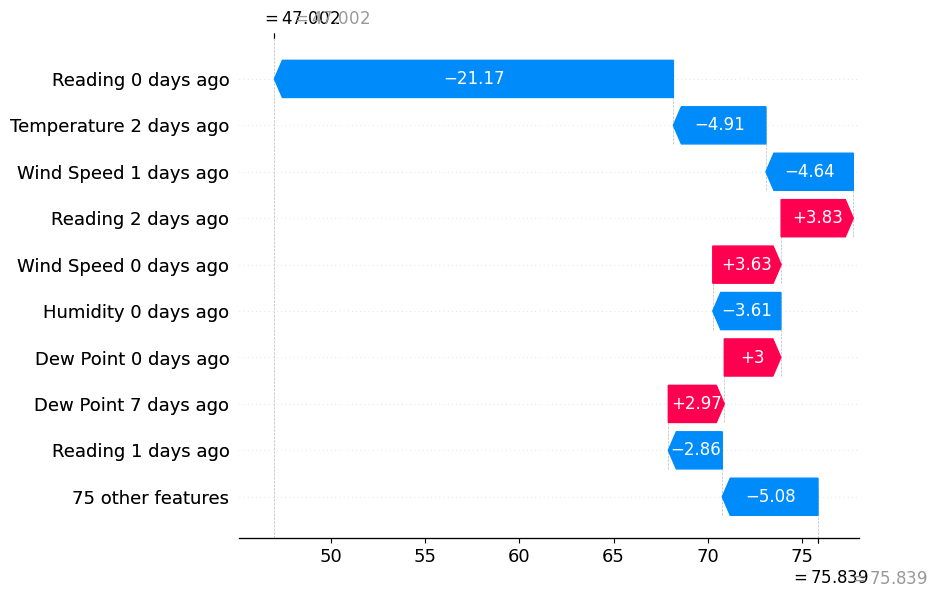

In [ ]:
shap.plots._waterfall.waterfall_legacy(explainer.expected_value[0], shap_values_dnn[0][0].reshape(-1,84)[0], feature_names = X_test.columns)
shap.plots._waterfall.waterfall_legacy(explainer.expected_value[0], shap_values_dnn[0][90].reshape(-1,84)[0], feature_names = X_test.columns)
shap.plots._waterfall.waterfall_legacy(explainer.expected_value[0], shap_values_dnn[0][180].reshape(-1,84)[0], feature_names = X_test.columns)

In [ ]:
shap_values[0].reshape(-1,84).shape

(72, 84)

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


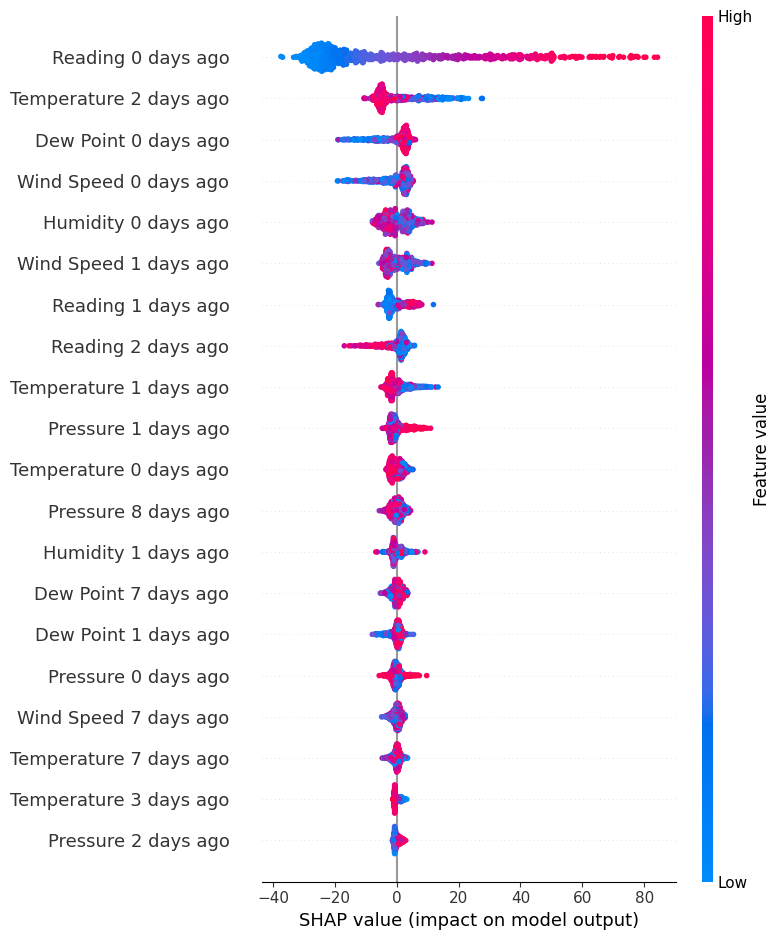

In [ ]:
# shap.summary_plot(shap_values = shap_values[0][0],features = X_test_dnn[:3][0])
# shap.summary_plot(shap_values = shap_values[0][0].transpose(),features = X_test_dnn[:3][0].transpose())
shap.summary_plot(shap_values = shap_values_dnn[0].reshape(-1,84),features = X_train)

In [ ]:
explainer.expected_value

array([75.83893737, 68.58968791, 63.71073057, 77.33858627, 78.00004531,
       77.79577949, 63.80120573])

In [ ]:
explanation = shap.Explanation(values=shap_values_dnn, base_values=model_cnn.predict(X_train_dnn), data=X_train_dnn)
explanation.shape

23/23 [==============================] - 0s 2ms/step


(7, 711, 6, 14)

IndexError: ignored

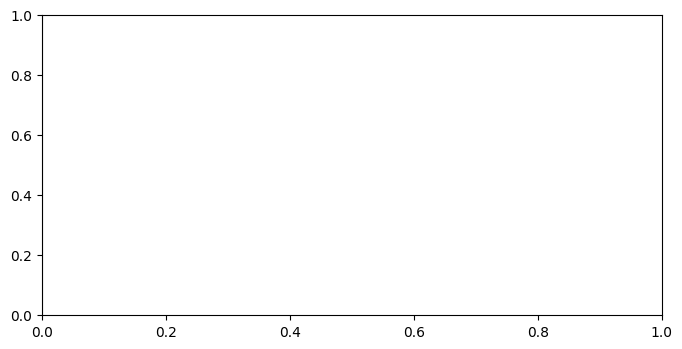

In [ ]:
shap.summary_plot(explanation, X_train_dnn)

In [ ]:
model_cnn.predict(X_train_dnn).mean(axis=1)

23/23 [==============================] - 0s 6ms/step


array([145.53891 , 142.0988  , 137.40367 , 135.5958  , 139.97118 ,
       146.95341 , 146.9676  , 140.32745 , 132.24458 , 133.52864 ,
       135.94966 , 131.588   , 132.83894 , 133.96884 , 134.77525 ,
       136.1393  , 135.07193 , 138.3029  , 127.612976, 132.29892 ,
       125.09457 , 120.688805, 118.04868 , 121.31972 , 121.57212 ,
       116.17928 , 105.17373 , 113.49836 , 118.797165, 121.3303  ,
       128.24725 , 131.12326 , 124.0732  , 114.973946, 113.08623 ,
       117.793686, 116.45451 , 117.15383 , 117.960396, 101.67779 ,
       116.548775, 113.4228  , 108.10008 , 102.084145, 107.234375,
       109.94176 , 109.79603 , 109.58861 , 119.56929 , 114.631004,
       104.45338 , 105.64778 ,  99.471565,  97.5764  ,  92.55458 ,
        87.14658 ,  84.74377 ,  89.073044,  94.26326 ,  86.984505,
        80.65746 ,  80.10931 ,  80.25753 ,  67.792946,  71.05799 ,
        74.22546 ,  66.01454 ,  64.22096 ,  65.6198  ,  73.42053 ,
        68.858955,  68.58104 ,  72.18519 ,  69.553215,  67.681

In [ ]:
shap.force_plot(base_value = explainer.expected_value[0],
                shap_values = shap_values[0],
                features = X.iloc[0:50,:]
                )

In [ ]:
shap.plots.scatter(shap_values[0][:,:], color=shap_values[0])

TypeError: ignored

IndexError: ignored

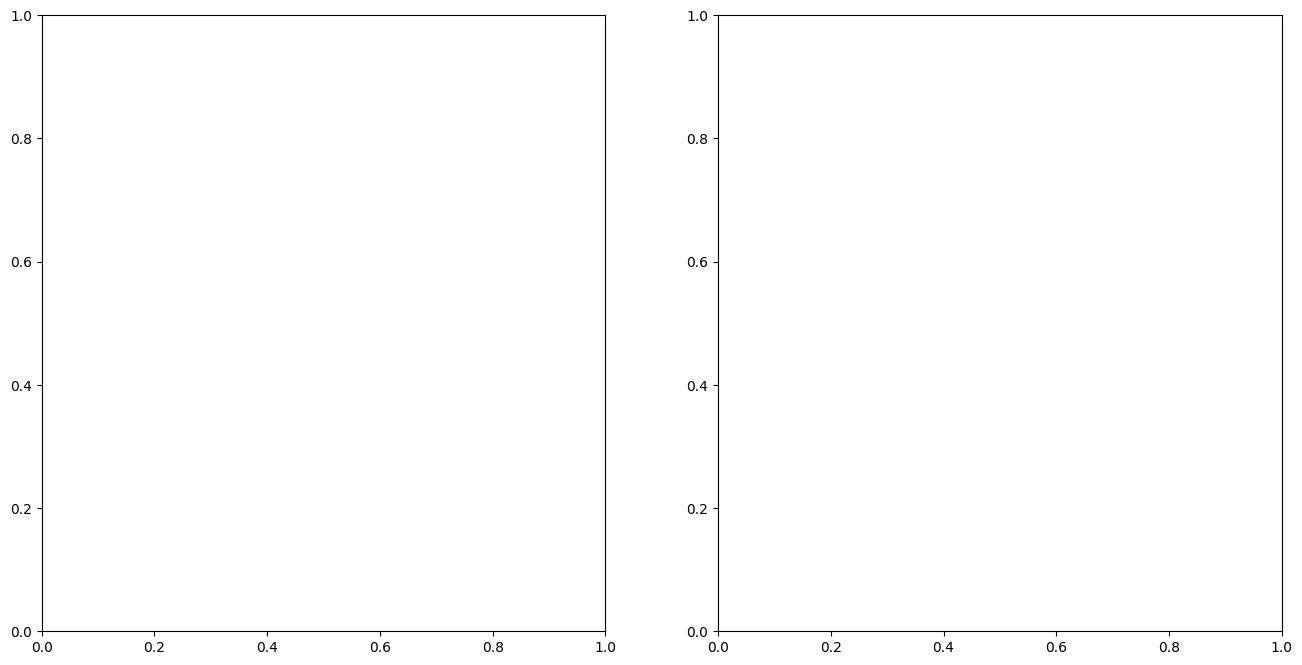

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2,figsize=(16,8))

#SHAP scatter plots
shap.plots.scatter(shap_values[:,"Reading 0 days ago"],ax=ax[0],show=False)
shap.plots.scatter(shap_values[:,"Temperature 0 days ago"],ax=ax[1])

# Multi Folding

In [ ]:
augmented_daily_series

,Reading 0 days ago,Temperature 0 days ago,Dew Point 0 days ago,Humidity 0 days ago,Wind Speed 0 days ago,Pressure 0 days ago,Reading 1 days ago,Temperature 1 days ago,Dew Point 1 days ago,Humidity 1 days ago,...,Humidity 13 days ago,Wind Speed 13 days ago,Pressure 13 days ago,Reading 1 day after,Reading 2 day after,Reading 3 day after,Reading 4 day after,Reading 5 day after,Reading 6 day after,Reading 7 day after
time,,,,,,,,,,,,,,,,,,,,,
2019-01-14,156.24,20.38,12.63,62.94,3.79,29.93,143.85,20.59,13.92,68.65,...,62.42,2.58,30.04,149.85,135.25,151.91,186.02,216.26,200.78,124.10
2019-01-15,149.85,19.86,12.24,62.75,6.56,29.98,156.24,20.38,12.63,62.94,...,62.71,3.27,30.03,135.25,151.91,186.02,216.26,200.78,124.10,91.27
2019-01-16,135.25,19.31,11.15,60.83,5.90,29.98,149.85,19.86,12.24,62.75,...,65.60,3.35,30.05,151.91,186.02,216.26,200.78,124.10,91.27,108.96
2019-01-17,151.91,20.05,11.66,61.17,2.65,29.91,135.25,19.31,11.15,60.83,...,63.10,4.92,30.07,186.02,216.26,200.78,124.10,91.27,108.96,129.80
2019-01-18,186.02,20.14,13.44,67.69,2.90,29.92,151.91,20.05,11.66,61.17,...,66.83,4.10,30.02,216.26,200.78,124.10,91.27,108.96,129.80,118.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-12-20,125.80,19.79,12.44,64.21,6.94,29.96,111.15,21.56,14.74,66.15,...,80.54,4.23,29.90,175.05,182.20,180.46,185.44,173.67,146.74,107.79
2021-12-21,175.05,20.40,13.89,67.62,5.60,29.92,125.80,19.79,12.44,64.21,...,69.48,1.35,29.96,182.20,180.46,185.44,173.67,146.74,107.79,96.04
2021-12-22,182.20,20.94,15.21,70.50,2.25,29.88,175.05,20.40,13.89,67.62,...,68.88,4.38,30.00,180.46,185.44,173.67,146.74,107.79,96.04,110.14


In [ ]:
from lightgbm import LGBMRegressor
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from scipy.stats import t
from sklearn.model_selection import TimeSeriesSplit, train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error
from sklearn.multioutput import MultiOutputRegressor


df = augmented_daily_series
X = df.drop('Reading', axis=1)
y = df['Reading']

In [ ]:
start = "2021-01-01"
end = "2021-12-31"
month_list_start = pd.date_range(start, end, freq='MS')
month_list_end = pd.date_range(start, end, freq='M')
month_list_end

In [ ]:
for month_start,month_end in zip(month_list_start,month_list_end):
  # print(month_start,month_end)
  exclusion_dates = pd.date_range(start=month_start, end=month_end)
  X_train, X_test = X.loc[~X.index.isin(exclusion_dates)], X.loc[month_start:month_end]
  y_train, y_test = y.loc[~y.index.isin(exclusion_dates)], y.loc[month_start:month_end]

  model = (LGBMRegressor(random_state=42))
  # model = (LinearRegression())
  # model = (SVR(kernel="linear"))

  model.fit(X_train, y_train)
  predictions = model.predict(X_test)

  #calculate MAE
  mae = np.round(mean_squared_error(y_test, predictions), 3)

  #plot reality vs prediction for the last week of the dataset
  fig = plt.figure(figsize=(16,8))
  plt.title(f'Real vs Prediction - MAE {mae}', fontsize=20)
  plt.plot(y_test, color='red')
  plt.plot(pd.Series(predictions, index=y_test.index), color='green')
  # plt.plot(pd.Series(predictions[:,0], index=y_test.index), color='green')
  plt.xlabel('Day', fontsize=16)
  plt.ylabel('PM2.5 Reading', fontsize=16)
  plt.legend(labels=['Real', 'Prediction'], fontsize=16)
  plt.grid()
  plt.show()

  # create a dataframe with the variable importances of the model
  df_importances = pd.DataFrame({
      'feature': model.booster_.feature_name(),
      'importance': model.feature_importances_
  }).sort_values(by='importance', ascending=False).head(15)


  # df_importances = pd.DataFrame({
  #     'feature': X_train.columns,
  #     'importance': model.coef_[0]
  # }).sort_values(by='importance', ascending=False).head(15)

  #plot variable importances of the model
  plt.title('Variable Importances', fontsize=16)
  sns.barplot(x=df_importances.importance, y=df_importances.feature, orient='h')
  plt.show()
  break

# Univariate Forecast

In [ ]:
no_period_entry = 24

# dataset = series['2017':'2020'].resample('D').mean()
dataset = series
train,test = dataset.loc['2019':'2020'].values,dataset.loc['2021'].values
# train,test = train[:-(train.shape[0]%no_period_entry)],test[:-(test.shape[0]%no_period_entry)]

train = np.array(np.split(train, len(train)/no_period_entry))
test = np.array(np.split(test, len(test)/no_period_entry))

In [ ]:
train.shape,test.shape

((731, 24, 6), (365, 24, 6))

In [ ]:
# univariate multi-step encoder-decoder convlstm
from math import sqrt
from numpy import split
from numpy import array
from pandas import read_csv
from sklearn.metrics import mean_squared_error
from matplotlib import pyplot
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Flatten
from keras.layers import LSTM
from keras.layers import RepeatVector
from keras.layers import TimeDistributed
from keras.layers import ConvLSTM2D
from keras.callbacks import ModelCheckpoint


# split a univariate dataset into train/test sets
def split_dataset(data):
	# split into standard weeks
	train, test = data[1:-328], data[-328:-6]
	# restructure into windows of weekly data
	train = array(split(train, len(train)/7))
	test = array(split(test, len(test)/7))
	return train, test

# evaluate one or more weekly forecasts against expected values
def evaluate_forecasts(actual, predicted):
	scores = list()
	# calculate an RMSE score for each day
	for i in range(actual.shape[1]):
		# calculate mse
		mse = mean_squared_error(actual[:, i], predicted[:, i])
		# calculate rmse
		rmse = sqrt(mse)
		# store
		scores.append(rmse)

	# print(actual[:, i].shape,predicted[:, i][:,0].shape)
	# days = list(range(actual[:, i].shape[0]))
	# pyplot.plot(days, actual[:, i], marker='o', label='actual')
	# pyplot.plot(days, predicted[:, i], marker='o', label='predicted')
	# pyplot.show()

	# calculate overall RMSE
	s = 0
	for row in range(actual.shape[0]):
		for col in range(actual.shape[1]):
			s += (actual[row, col] - predicted[row, col])**2
	score = sqrt(s / (actual.shape[0] * actual.shape[1]))
	return score, scores

# summarize scores
def summarize_scores(name, score, scores):
	s_scores = ', '.join(['%.1f' % s for s in scores])
	print('%s: [%.3f] %s' % (name, score, s_scores))

# convert history into inputs and outputs
def to_supervised(train, n_input, n_out=24):
	# flatten data
	data = train.reshape((train.shape[0]*train.shape[1], train.shape[2]))
	# data = train
	X, y = list(), list()
	in_start = 0
	# step over the entire history one time step at a time
	for _ in range(len(data)):
		# define the end of the input sequence
		in_end = in_start + n_input
		out_end = in_end + n_out
		# ensure we have enough data for this instance
		if out_end <= len(data):
			# x_input = data[in_start:in_end, 0]
			x_input = data[in_start:in_end]
			# x_input = x_input.reshape((len(x_input), 1))
			x_input = x_input.reshape((len(x_input), train.shape[2]))
			X.append(x_input)
			# y.append(data[in_end:out_end, 0])
			y.append(data[in_end:out_end])
		# move along one time step
		in_start += 1
	return array(X), array(y)

# train the model
def build_model(train, n_steps, n_length, n_input):
	# prepare data
	train_x, train_y = to_supervised(train, n_input)
	# define parameters
	# verbose, epochs, batch_size = 0, 20, 16
	verbose, epochs, batch_size = 1, 10, 256
	n_timesteps, n_features, n_outputs = train_x.shape[1], train_x.shape[2], train_y.shape[1]
	# reshape into subsequences [samples, time steps, rows, cols, channels]
	train_x = train_x.reshape((train_x.shape[0], n_steps, 1, n_length, n_features))
	# reshape output into [samples, timesteps, features]
	# train_y = train_y.reshape((train_y.shape[0], train_y.shape[1], 1))
	train_y = train_y.reshape((train_y.shape[0], 1, train_y.shape[1] * train_y.shape[2]))
	# define model
	model = Sequential()
	model.add(ConvLSTM2D(filters=64, kernel_size=(1,3), activation='relu', input_shape=(n_steps, 1, n_length, n_features)))
	model.add(Flatten())
	model.add(RepeatVector(n_outputs))
	model.add(LSTM(200, activation='relu', return_sequences=True))
	model.add(TimeDistributed(Dense(1000, activation='relu')))
	model.add(TimeDistributed(Dense(train_y.shape[1] * train_y.shape[2])))
	# model.add(TimeDistributed(Dense(train_y.shape[1]*train_y.shape[2])))

	filepath="aq.forecast.weights.best.hdf5"
	checkpoint = ModelCheckpoint(filepath, monitor='loss', verbose=1, save_best_only=True, mode='min')
	# callbacks_list = [checkpoint]
	callbacks_list = []

	# if os.path.exists(filepath):
	# 	model.load_weights(filepath)

	model.compile(loss='mse', optimizer='adam')
	# fit network
	model.fit(train_x, train_y, epochs=epochs, batch_size=batch_size, verbose=verbose,callbacks=callbacks_list,)
	return model

# make a forecast
def forecast(model, history, n_steps, n_length, n_input):
	# flatten data
	data = array(history)
	data = data.reshape((data.shape[0]*data.shape[1], data.shape[2]))
	# retrieve last observations for input data
	# input_x = data[-n_input:, 0]
	input_x = data[-n_input:]
	# reshape into [samples, time steps, rows, cols, channels]
	input_x = input_x.reshape((1, n_steps, 1, n_length, input_x.shape[1]))
	# forecast the next week
	yhat = model.predict(input_x, verbose=0)
	# print(yhat)
	# print()
	# we only want the vector forecast
	yhat = yhat[0,0]
	return yhat

# evaluate a single model
def evaluate_model(train, test, n_steps, n_length, n_input):
	# fit model
	# model = build_model(train, n_steps, n_length, n_input)
	# history is a list of weekly data
	history = [x for x in train]
	# walk-forward validation over each week
	predictions = list()
	for i in range(len(test)):
		# predict the week
		yhat_sequence = forecast(model, history, n_steps, n_length, n_input)
		# store the predictions
		predictions.append(yhat_sequence)
		# get real observation and add to history for predicting the next week
		history.append(test[i, :])
	# evaluate predictions days for each week
	predictions = array(predictions)
	# score, scores = evaluate_forecasts(test[:, :, 0], predictions)
	score, scores = None,None
	return predictions, score, scores



# load the new file
# dataset = series['2019':'2022'].resample('D').mean().copy()
# train,test = dataset['2019':'2021'].values,dataset['2021':'2021'].values

# define the number of subsequences and the length of subsequences
n_steps, n_length = 7, 24
# define the total days to use as input
n_input = n_length * n_steps
# model = build_model(train, n_steps, n_length, n_input)
# score, scores = evaluate_model(train, test, n_steps, n_length, n_input)
# # summarize scores
# summarize_scores('lstm', score, scores)


# # plot scores
# # days = ['sun', 'mon', 'tue', 'wed', 'thr', 'fri', 'sat']
# days = list(range(1,25))
# pyplot.plot(days, scores, marker='o', label='lstm')
# pyplot.show()

In [ ]:
model = build_model(train, n_steps, n_length, n_input)

Epoch 1/10
68/68 [==============================] - 145s 2s/step - loss: 6790.8496
Epoch 2/10
68/68 [==============================] - 114s 2s/step - loss: 2083.6743
Epoch 3/10
68/68 [==============================] - 114s 2s/step - loss: 1054.9578
Epoch 4/10
68/68 [==============================] - 115s 2s/step - loss: 875.3015
Epoch 5/10
68/68 [==============================] - 115s 2s/step - loss: 795.7072
Epoch 6/10
68/68 [==============================] - 119s 2s/step - loss: 759.7938
Epoch 7/10
68/68 [==============================] - 114s 2s/step - loss: 752.0325
Epoch 8/10
68/68 [==============================] - 114s 2s/step - loss: 740.5533
Epoch 9/10
68/68 [==============================] - 113s 2s/step - loss: 757.0607
Epoch 10/10
68/68 [==============================] - 114s 2s/step - loss: 714.1694


In [ ]:
from keras.models import load_model

# model.save('aq_model.h5')  # creates a HDF5 file 'my_model.h5'
# del model  # deletes the existing model

# returns a compiled model
# identical to the previous one
model = load_model('aq_model.h5')

OSError: ignored

In [ ]:
predictions, score, scores = evaluate_model(train, test, n_steps, n_length, n_input)
# predicted = predictions.reshape(-1,24,3)
# predicted.shape,test.shape

NameError: ignored

In [ ]:
predictions.shape,test.shape

In [ ]:
predictions_df = pd.DataFrame(predictions.reshape(-1,3))

In [ ]:
actual_df = dataset.loc['2021']

In [ ]:
predictions_df.columns = dataset.columns+'_pred'
predictions_df.index = actual_df.index

In [ ]:
predictions_df

,Dhaka_pred,Khulna_pred,Chittagong_pred
time,,,
2021-01-01 00:00:00,134.143143,114.369667,96.466370
2021-01-01 01:00:00,130.840927,116.377975,103.909096
2021-01-01 02:00:00,123.127846,110.297241,92.886536
2021-01-01 03:00:00,121.801651,114.784218,96.803757
2021-01-01 04:00:00,117.859436,117.093948,92.628464
...,...,...,...
2021-12-31 19:00:00,117.159424,106.501579,95.271683
2021-12-31 20:00:00,119.563705,114.234055,97.553017
2021-12-31 21:00:00,122.596588,108.877403,86.821152


In [ ]:
actual_and_pred_df = pd.concat([actual_df,predictions_df],axis=1)
actual_and_pred_df

,Dhaka,Khulna,Chittagong,Dhaka_pred,Khulna_pred,Chittagong_pred
time,,,,,,
2021-01-01 00:00:00,144.24,124.22,82.49,134.143143,114.369667,96.466370
2021-01-01 01:00:00,129.81,116.72,75.16,130.840927,116.377975,103.909096
2021-01-01 02:00:00,131.61,116.22,77.43,123.127846,110.297241,92.886536
2021-01-01 03:00:00,148.33,125.22,86.93,121.801651,114.784218,96.803757
2021-01-01 04:00:00,175.76,139.56,101.30,117.859436,117.093948,92.628464
...,...,...,...,...,...,...
2021-12-31 19:00:00,120.48,119.48,94.47,117.159424,106.501579,95.271683
2021-12-31 20:00:00,122.79,130.28,80.47,119.563705,114.234055,97.553017
2021-12-31 21:00:00,125.79,130.36,91.94,122.596588,108.877403,86.821152


In [ ]:
import plotly.express as px
fig = px.line(actual_and_pred_df, y=actual_and_pred_df.columns,)
fig.show()

In [ ]:
dataset.loc['2019-01-01']

NameError: ignored

In [ ]:
data = train.reshape((train.shape[0]*train.shape[1], train.shape[2]))
train.shape,data.shape,test.shape

((731, 24, 3), (17544, 3), (365, 24, 3))

In [ ]:
def to_supervised_1(train, n_input, n_out=24):
	# flatten data
	data = train.reshape((train.shape[0]*train.shape[1], train.shape[2]))
	# data = train
	X, y = list(), list()
	in_start = 0
	# step over the entire history one time step at a time
	for _ in range(len(data)):
		# define the end of the input sequence
		in_end = in_start + n_input
		out_end = in_end + n_out
		# ensure we have enough data for this instance
		if out_end <= len(data):
			x_input = data[in_start:in_end]
			x_input = x_input.reshape((len(x_input), train.shape[2]))
			X.append(x_input)
			y.append(data[in_end:out_end])
		# move along one time step
		in_start += 1
	return array(X), array(y)

In [ ]:
train_x, train_y = to_supervised_1(train, n_input)

print(train_x.shape, train_y.shape)

n_timesteps, n_features, n_outputs = train_x.shape[1], train_x.shape[2], train_y.shape[1]
# reshape into subsequences [samples, time steps, rows, cols, channels]
train_x = train_x.reshape((train_x.shape[0], n_steps, 1, n_length, n_features))
# reshape output into [samples, timesteps, features]
train_y = train_y.reshape((train_y.shape[0], train_y.shape[1] , train_y.shape[2]))
print(train_x.shape, train_y.shape)
print(n_timesteps, n_features, n_outputs)

NameError: ignored

In [ ]:
train_x[:,:,0][1].shape

(2, 24, 3)

In [ ]:
train_x[0]

array([[[[158.26, 155.7 , 123.92],
         [148.1 , 143.48, 114.76],
         [151.65, 149.72, 116.9 ],
         [174.06, 162.1 , 132.69],
         [183.8 , 169.2 , 140.81],
         [157.48, 150.94, 122.55],
         [112.25, 127.58,  91.33],
         [ 87.26, 112.18,  72.11],
         [ 64.65,  98.28,  55.94],
         [ 47.1 ,  79.74,  44.59],
         [ 43.45,  72.08,  40.14],
         [ 40.59,  62.38,  38.02],
         [ 40.05,  61.12,  38.59],
         [ 61.99,  67.08,  54.93],
         [ 92.2 ,  86.14,  77.25],
         [118.35, 119.06,  97.41],
         [152.95, 139.86, 120.43],
         [144.03, 153.34, 115.7 ],
         [161.68, 171.88, 128.1 ],
         [168.43, 177.48, 132.91],
         [164.82, 171.74, 129.36],
         [153.48, 166.64, 121.64],
         [140.08, 149.24, 111.47],
         [133.16, 141.38, 106.59]]],


       [[[150.75, 142.52, 116.9 ],
         [148.08, 138.92, 115.36],
         [156.  , 144.24, 119.18],
         [164.76, 146.08, 125.74],
         [185.47

In [ ]:
train_y[0]

NameError: ignored

In [ ]:
# summarize scores
summarize_scores('lstm', score, scores)

In [ ]:
# plot scores
# days = ['sun', 'mon', 'tue', 'wed', 'thr', 'fri', 'sat']
days = list(range(1,25))
pyplot.plot(days, scores, marker='o', label='lstm')
pyplot.show()

# Shallow Network Classification

In [ ]:
# Model with relu (a different activation function) and drop out (for regularization)
model = Sequential()
model.add(Dense(100, activation = 'relu', input_dim = X_train_static.shape[1]))
model.add(Dropout(rate = 0.1))
# model.add(Dense(50, activation = 'relu', input_dim = X_train_static.shape[1]))
# model.add(Dropout(rate = 0.2))
model.add(Dense(1, activation = 'sigmoid'))


# Compile the model
model.compile(loss = 'binary_crossentropy',
              optimizer = 'adam',
              metrics = ['accuracy'])

print(model.summary())

# model.fit(X_train_static, y_train, batch_size = 32, epochs = 10, verbose = 1)

# Deep Networks Classification

## CNN

In [ ]:
# from keras.layers import Conv1D

model_cnn = Sequential()
model_cnn.add(Conv1D(filters = 128, kernel_size = 5, activation = 'relu', input_shape = (3,30,1)))
# model_cnn.add(MaxPooling1D(pool_size = 2))
model_cnn.add(Dropout(rate = 0.25))
model_cnn.add(Flatten())
model_cnn.add(Dense(1, activation = 'sigmoid'))

# compile the model - use categorical crossentropy, and the adam optimizer
model_cnn.compile(
                loss = 'mse',
                optimizer = 'adam',
                metrics = ['accuracy'])

print(model_cnn.summary())

# model_cnn.fit(X_train_ts, y_train, batch_size = 32, epochs= 10, verbose = 1)

In [ ]:
def calc_prevalence(y_actual):
    return (sum(y_actual)/len(y_actual))

def calc_specificity(y_actual, y_pred, thresh):
    # calculates specificity
    return sum((y_pred < thresh) & (y_actual == 0)) /sum(y_actual ==0)

def print_report(y_actual, y_pred, thresh):

    F1 = f1_score(y_actual, (y_pred > thresh), average='weighted')
    AUC = roc_auc_score(y_actual, y_pred)
    Accuracy = accuracy_score(y_actual, (y_pred > thresh))
    Recall = recall_score(y_actual, (y_pred > thresh))
    Precision = precision_score(y_actual, (y_pred > thresh))
    Specificity = calc_specificity(y_actual, y_pred, thresh)

    print('F1:%.2f'%F1)
    print('AUC:%.2f'%AUC)
    print('Accuracy:%.2f'%Accuracy)
    print('Recall:%.2f'%Recall)
    print('Precision:%.2f'%Precision)
    # print('Specificity:%.2f'%Specificity)
    # print('prevalence:%.2f'%calc_prevalence(y_actual))
    print(' ')

    return F1, AUC, Accuracy, Recall, Precision

In [ ]:
# y_train_prob = model.predict(X_train)
# y_train_preds_dense = y_train_prob.argmax(axis=-1)

# y_valid_prob = model.predict(X_valid)
# y_valid_preds_dense = y_valid_prob.argmax(axis=-1)

# y_train_preds_dense = model.predict_proba(X_train, verbose = 1)
# y_valid_preds_dense = model.predict_proba(X_valid, verbose = 1)

In [ ]:
y_valid_prob = model_cnn.predict(X_valid_ts)
y_valid_preds_cnn = y_valid_prob.argmax(axis=-1)

In [ ]:
thresh = (sum(y_train)/len(y_train))
thresh

In [ ]:
print('Train')
print_report(y_train, y_train_preds_dense, thresh)

print('Valid')
print_report(y_valid, y_valid_preds_dense, thresh)

In [ ]:
print_report(y_valid, y_valid_preds_cnn, thresh)

## RNN LSTM with Static Features

In [ ]:
# final_label = label+'_Cat'
# train_df[final_label] = np.where(train_df[label]=='relaxed', 0, 1)

# model_features_static = [
#     'Age', 'Gender',
#     'NASA_Physical', 'NASA_Effort', 'NASA_Frustration', 'NASA_Temporal', 'NASA_Performance',
#     'Perinasal_Mean', 'Perinasal_SD',
#     'HR_Mean', 'HR_SD',
#     'BR_Mean', 'BR_SD'
# ]

# model_features_ts = ['Perinasal_Log_Window', 'Heart_Window', 'Breathing_Window']

# model_features = model_features_static + model_features_ts

# features = model_features

In [ ]:
x_train_over_static = X_train
x_val_static = X_valid

In [ ]:
def recall_m(y_true, y_pred):
  true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
  possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
  recall = true_positives / (possible_positives + K.epsilon())
  return recall

def precision_m(y_true, y_pred):
  true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
  predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
  precision = true_positives / (predicted_positives + K.epsilon())
  return precision

def f1_m(y_true, y_pred):
  precision = precision_m(y_true, y_pred)
  recall = recall_m(y_true, y_pred)
  return 2*((precision*recall)/(precision+recall+K.epsilon()))

# Define timesteps and the number of features
n_timesteps = 3
n_features = 30
n_outputs = 1

# RNN + SLP Model
# Define input layer
recurrent_input = Input(shape=(n_timesteps,n_features),name="TIMESERIES_INPUT")
static_input = Input(shape=(X_train_static.shape[1], ),name="STATIC_INPUT")

#CNN Layers

conv_layer_one = Conv1D(filters=32, kernel_size=8, strides=1, activation="relu", padding="same")(recurrent_input)
pool_layer_one = MaxPooling1D(pool_size = 2, name ="POOLING_LAYER_1")(conv_layer_one)

conv_layer_two = Conv1D(filters=16, kernel_size=4, strides=1, activation="relu", padding="same")(pool_layer_one)
pool_layer_two = MaxPooling1D(pool_size = 1, name ="POOLING_LAYER_2")(conv_layer_two)

# RNN Layers
# layer - 1
rec_layer_one = Bidirectional(LSTM(128, kernel_regularizer=l2(0.01), recurrent_regularizer=l2(0.01),return_sequences=True),name ="BIDIRECTIONAL_LAYER_1")(pool_layer_two)
rec_layer_one = Dropout(0.1,name ="DROPOUT_LAYER_1")(rec_layer_one)

# layer - 2
rec_layer_two = Bidirectional(LSTM(64, kernel_regularizer=l2(0.01), recurrent_regularizer=l2(0.01)),name ="BIDIRECTIONAL_LAYER_2")(rec_layer_one)
rec_layer_two = Dropout(0.1,name ="DROPOUT_LAYER_2")(rec_layer_two)

# SLP Layers
static_layer_one = Dense(64,  kernel_regularizer=l2(0.001),  activation='relu',name="DENSE_LAYER_1")(static_input)

# Combine layers - RNN + SLP
combined = Concatenate(axis= 1,name = "CONCATENATED_TIMESERIES_STATIC")([rec_layer_two,static_layer_one])

# flatten_layer = Flatten()(combined)

combined_dense_two = Dense(64, activation='relu',name="DENSE_LAYER_2")(combined)
combined_dense_three = Dense(32, activation='relu',name="DENSE_LAYER_3")(combined_dense_two)
output = Dense(n_outputs,activation='sigmoid',name="OUTPUT_LAYER")(combined_dense_three)


# Compile ModeL
model = Model(inputs=[recurrent_input,static_input],outputs=[output])

# binary cross entropy loss
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy',f1_m,precision_m, recall_m])

# focal loss
def focal_loss_custom(alpha, gamma):
  def binary_focal_loss(y_true, y_pred):
    fl = tfa.losses.SigmoidFocalCrossEntropy(alpha=alpha, gamma=gamma)
    y_true_K = tensorflow.ones_like(y_true)
    focal_loss = fl(y_true, y_pred)
    return focal_loss
  return binary_focal_loss

# model.compile(loss=focal_loss_custom(alpha=0.2, gamma=2.0), optimizer='adam', metrics=['accuracy',f1_m,precision_m, recall_m])
model.compile(loss=focal_loss_custom(alpha=0.2, gamma=2.0), optimizer='adam', metrics=['accuracy'])

model.summary()

In [ ]:
epochs = 150
batch_size = 32
verbose = 1

history =  model.fit([np.asarray(X_train_ts).astype('float32'), np.asarray(X_train_static).astype('float32')],
                     y_train, epochs=epochs, batch_size=batch_size, verbose=verbose,
                     validation_data=([np.asarray(X_valid_ts).astype('float32'), np.asarray(X_valid_static).astype('float32')],y_valid))


In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [ ]:
for study in ['sim2', 'tt1', 'office_tasks']:
    test_df = df.copy()[df.Study_Name == study]
    test_df[final_label] = np.where(test_df[label]=='relaxed', 0, 1)

    X_test = test_df.copy()[features]
    y_test = test_df.copy()[final_label]

    y_test_preds_dense = model.predict_proba(X_test, verbose = 1)

    print('Test Study: ' + study)
    print_report(y_test, y_test_preds_dense, thresh)

In [ ]:
% pip install --upgrade tensorflow